## ⚠️ Review notes — weaknesses found in the original notebook, and the fixes applied below

| # | Weakness in the original notebook | Fix applied below |
|---|---|---|
| 1 | **Wrong feature space for the prototypes — the most impactful bug.** `vit_model.head` was replaced with a 2-unit classification layer, and `extract_features` called `model(images)` directly. So the "features" used to build class prototypes and to compute cosine similarity were actually the 2-dimensional classifier **logits**, not a real embedding space. This defeats the entire point of metric-based few-shot learning (comparing rich embeddings) — it collapses to comparing two numbers per image. | `embed()` now calls `forward_features` + `forward_head(..., pre_logits=True)` to pull the pooled 384-d ViT embedding *before* the classification head. The head is only used for the auxiliary fine-tuning loss. |
| 2 | **No reproducibility.** No `torch.manual_seed` / `np.random.seed` anywhere, so the 5 support images per class are picked differently on every run and the reported accuracy is a single, unrepeatable number. | Added `set_seed()`, and an explicit per-episode seed drives both the support/query sampler and the `DataLoader` shuffling. |
| 3 | **Single-episode evaluation.** Few-shot learning papers standardly report mean ± std accuracy over many random support-set draws ("episodes"); this notebook drew one 5-shot support set and reported that single number as *the* result. | Added a multi-episode loop (`N_EPISODES`, default 5) that resamples the support/query split, retrains, and reports mean ± std accuracy. |
| 4 | **Uncontrolled full-backbone fine-tuning → overfitting.** The entire ViT-Small backbone (not just the head) was trained for 50 epochs on only 10 images (5-shot × 2 classes) with no augmentation or weight decay. In the original run this memorizes the support set almost immediately, which was never surfaced (no support-set accuracy logging pattern that would make this obvious, no regularization to counter it). | Added light train-time augmentation (flip / rotation / color-jitter) for the support set, `weight_decay` on the optimizer, and an optional `FREEZE_BACKBONE` flag that fine-tunes only the last transformer block + head — the more standard "shallow adaptation" regime for few-shot fine-tuning. |
| 5 | **Accuracy-only evaluation.** For a binary medical classification task, one accuracy number hides class imbalance and false-negative/false-positive trade-offs that matter clinically. | Added a full analysis suite (`full_analysis`): per-class report, balanced accuracy, macro/weighted F1, MCC, kappa, ROC-AUC, AP, sensitivity/specificity, bootstrap 95% CIs, held-out-Test-only metrics, and figures (confusion-matrix heatmaps, ROC, PR, fine-tuning curve, t-SNE) saved to `results/`. |
| 6 | **Hard-coded, non-portable dataset path** (`/kaggle/input/...`) with no existence check — fails off-Kaggle with an opaque `FileNotFoundError` deep inside `ImageFolder`. | `resolve_raw_dir()` locates the raw BreakHis folder (`./dataset/classificacao_binaria` or `BREAKHIS_RAW_DIR`) and raises a clear, actionable error if none exists. |
| 7 | **No checkpointing.** The fine-tuned model was never saved, so nothing from a training run could be reused or audited afterward. | Each episode's fine-tuned weights are now saved to `checkpoints/`. |
| 8 | **Wasteful label indexing.** `for idx, (_, label) in enumerate(dataset)` decodes *every image* just to read its class label, when `ImageFolder.samples` already gives `(path, label)` pairs without touching the image data. | Sampling now reads `dataset.samples` directly. |
| 9 | **Monolithic single code cell.** The entire pipeline (imports → data → model → training → evaluation) was one cell, making it impossible to re-run or debug a single stage (e.g. re-evaluate a saved model without retraining) and hard to review. | Split into narrated cells: config, data, model, sampling, training, evaluation, multi-episode summary. |
| 10 | README/paper claim results on BreakHis *and* BACH, but only BreakHis is present in this repo. | **Not fabricated here** — no BACH data to validate against. The BreakHis preparation code is BreakHis-specific (it parses BreakHis filenames for patient ids), so BACH would need its own preparation step; the rest of the pipeline is `ImageFolder`-based and dataset-agnostic. Left as an open gap. |
| 11 | **Patient-level leakage risk in the train/test split.** The notebook assumed a ready-made `Train/`/`Test/` folder of unknown provenance. BreakHis has 82 patients and ~24 images per patient per magnification; a random image-level split puts the same patient in both sets and inflates accuracy. | `prepare_breakhis_split()` builds the split from the raw dataset **by patient** (stratified by class, seeded, identical assignment across all magnifications), as symlinks. `verify_and_report_split()` asserts zero patient overlap and prints per-split image/patient counts. |
| 12 | **Query set shared patients with the support set.** The original query split was "all other Train images", i.e. from the same patients as the 5 support images. | Support shots come from distinct patients and the query set excludes every image of a support patient. |
| 13 | **No majority-class baseline; only one magnification.** BreakHis is ~70% malignant, so "always malignant" already scores ~70%. Only 200X was evaluated in the original. | Majority-class baseline is printed and stored next to accuracy; the run loops over `MAGNIFICATION_SETTINGS` (40X, 100X, 200X, 400X and all four combined) and prints a comparison table. |

> Issue #1 is the one to pay attention to: it means accuracy numbers from the original notebook reflect a much weaker method (a 2-D nearest-prototype classifier riding on top of an already-overfit classifier head) than what "ViT-embedding prototypical few-shot learning" is meant to measure. Re-run this fixed notebook to get numbers that actually reflect the intended method.


In [2]:
import json
import os
import random
import re
import shutil
from collections import Counter, defaultdict

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from timm import create_model
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import classification_report, confusion_matrix
from tqdm import tqdm


# Fix #2: reproducibility — original notebook never seeded anything, so which
# 5 images per class end up in the support set (and thus the reported
# accuracy) changed on every run.
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Fix #6: portable dataset path with a clear error instead of an opaque failure.
def resolve_raw_dir():
    candidates = [
        os.environ.get("BREAKHIS_RAW_DIR", ""),
        "./dataset/classificacao_binaria",
        "./dataset/BreakHis/classificacao_binaria",
    ]
    for path in candidates:
        if path and os.path.isdir(path):
            return path
    raise FileNotFoundError(
        "Could not find the raw BreakHis folder (the one that contains 40X/ 100X/ 200X/ 400X/, each with "
        "benign/ and malignant/). Put it at ./dataset/classificacao_binaria or set BREAKHIS_RAW_DIR."
    )


RAW_DATA_DIR = resolve_raw_dir()

# Dataset preparation settings (see "Dataset preparation" below).
PREPARED_ROOT = "./data/BreakHist_patient_split"
MAGNIFICATION_SETTINGS = ["40X", "100X", "200X", "400X", "40X+100X+200X+400X"]  # "+" = train AND test on those magnifications together
SPLIT_SEED = 42
TEST_FRACTION = 0.3

# Hyperparameters
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4     # Fix #4: mild regularization against overfitting the 10-image support set
BATCH_SIZE = 32
EXTRACT_BATCH_SIZE = 32  # batched (instead of one-image-at-a-time) feature extraction
SHOTS_PER_CLASS = 5
N_EPISODES = 5           # Fix #3: multiple random support/query draws instead of one
FREEZE_BACKBONE = True   # Fix #4: shallow fine-tuning (last block + head) instead of full backbone
BASE_SEED = 42


### Dataset preparation — patient-level split (Fix #11)

The raw dataset (`dataset/classificacao_binaria/<magnification>/<class>/*.png`) is real BreakHis (7,909 images, 82 patients) but ships **without a train/test split**. Splitting randomly by image would put images of the same patient in both Train and Test (BreakHis has ~24 images per patient per magnification), which inflates accuracy. So the split is done **by patient**: stratified by class, seeded, and computed once over all magnifications, so a patient is on the same side at 200X, at 400X and in the combined `40X+100X+200X+400X` setting. The result is written as symlinks (no data is copied) under `data/BreakHist_patient_split/Final <setting>/{Train,Test}/<class>/`, and `verify_and_report_split()` asserts there is zero patient overlap.

In [3]:
import numpy as np

_FILENAME_RE = re.compile(r"^SOB_([BM])_([A-Z]+)-(\d+)-([A-Za-z0-9]+)-(\d+)-(\d+)\.png$")


def patient_id(path):
    """Official BreakHis filenames look like SOB_B_A-14-22549AB-40-001.png ->
    patient 'A-14-22549AB'. (Verified on this dataset: exactly 82 distinct ids = 24 benign + 58 malignant patients.)"""
    m = _FILENAME_RE.match(os.path.basename(path))
    if m is None:
        raise ValueError(f"Not an official BreakHis filename, cannot recover patient id: {path}")
    _, subtype, year, slide, _, _ = m.groups()
    return f"{subtype}-{year}-{slide}"


def assign_patient_split(raw_dir, test_fraction, seed):
    """patient -> 'Train' / 'Test', stratified by class. Computed over ALL magnifications at once,
    so the same patient lands on the same side at 40X, 100X, 200X and 400X (no cross-magnification leakage)."""
    patients_by_class = defaultdict(set)
    for mag in sorted(os.listdir(raw_dir)):
        for cls in sorted(os.listdir(os.path.join(raw_dir, mag))):
            for fname in os.listdir(os.path.join(raw_dir, mag, cls)):
                patients_by_class[cls].add(patient_id(fname))

    rng = np.random.RandomState(seed)
    assignment = {}
    for cls, pats in sorted(patients_by_class.items()):
        pats = sorted(pats)
        rng.shuffle(pats)
        n_test = max(1, int(round(len(pats) * test_fraction)))
        for i, p in enumerate(pats):
            assignment[p] = "Test" if i < n_test else "Train"
    return assignment


def prepare_breakhis_split(raw_dir, out_root, setting, test_fraction=0.3, seed=42):
    """Builds out_root/'Final <setting>'/{Train,Test}/<class>/ as symlinks to the raw images (no data copied).
    `setting` is a magnification such as '200X', or several joined with '+' such as '200X+400X'."""
    mags = setting.split("+")
    for mag in mags:
        if not os.path.isdir(os.path.join(raw_dir, mag)):
            raise FileNotFoundError(f"Magnification folder '{mag}' not found under {raw_dir}")

    out_dir = os.path.join(out_root, f"Final {setting}")
    manifest_path = os.path.join(out_dir, "split_manifest.json")
    params = {"mags": mags, "test_fraction": test_fraction, "seed": seed, "raw_dir": os.path.abspath(raw_dir)}

    if os.path.isfile(manifest_path):
        with open(manifest_path) as f:
            if json.load(f)["params"] == params:
                return out_dir
        shutil.rmtree(out_dir)  # stale split made by this function with other parameters (only symlinks inside)
    elif os.path.exists(out_dir):
        raise FileExistsError(f"{out_dir} exists but has no split_manifest.json; refusing to overwrite it.")

    assignment = assign_patient_split(raw_dir, test_fraction, seed)
    for mag in mags:
        for cls in sorted(os.listdir(os.path.join(raw_dir, mag))):
            src_dir = os.path.join(raw_dir, mag, cls)
            for fname in sorted(os.listdir(src_dir)):
                dst_dir = os.path.join(out_dir, assignment[patient_id(fname)], cls)
                os.makedirs(dst_dir, exist_ok=True)
                src, dst = os.path.abspath(os.path.join(src_dir, fname)), os.path.join(dst_dir, fname)
                try:
                    os.symlink(src, dst)
                except OSError:  # e.g. Windows without symlink rights
                    shutil.copy2(src, dst)

    with open(manifest_path, "w") as f:
        json.dump({"params": params, "assignment": assignment}, f)
    return out_dir


def verify_and_report_split(data_dir):
    """Asserts no patient appears in both Train and Test, and prints what the split looks like."""
    counts, patients = {}, {}
    print(f"{'split':<6} {'class':<12} {'images':>7} {'patients':>9}")
    for split in ("Train", "Test"):
        patients[split] = set()
        for cls in sorted(os.listdir(os.path.join(data_dir, split))):
            files = os.listdir(os.path.join(data_dir, split, cls))
            pats = {patient_id(f) for f in files}
            patients[split] |= pats
            counts[(split, cls)] = len(files)
            print(f"{split:<6} {cls:<12} {len(files):>7} {len(pats):>9}")

    overlap = patients["Train"] & patients["Test"]
    assert not overlap, f"PATIENT LEAKAGE: {len(overlap)} patients in both Train and Test: {sorted(overlap)[:5]}"
    test_counts = [n for (split, _), n in counts.items() if split == "Test"]
    print(f"OK: 0 patients shared between Train ({len(patients['Train'])}) and Test ({len(patients['Test'])}).")
    print(f"Majority-class baseline on Test: {100 * max(test_counts) / sum(test_counts):.1f}% accuracy (a model must beat this).")


### Data

`load_datasets()` opens the prepared `Train/` twice — once with augmentation (for fine-tuning the support images) and once without (for the query split and for building support-set embeddings for the prototypes) — plus the patient-disjoint `Test/` split. The original notebook applied no augmentation anywhere. It is called once per magnification setting in the final cell.

In [4]:
# Fix #4: augmentation for the (tiny) support set; the eval transform stays
# clean/deterministic so query/test accuracy isn't affected by random crops etc.
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

def load_datasets(data_dir):
    train_aug = ImageFolder(root=f"{data_dir}/Train", transform=train_transform)
    train_eval = ImageFolder(root=f"{data_dir}/Train", transform=eval_transform)
    test = ImageFolder(root=f"{data_dir}/Test", transform=eval_transform)
    assert train_aug.classes == train_eval.classes == test.classes
    return train_aug, train_eval, test, train_aug.classes


### Model

`embed()` is the key fix (#1): it returns the pooled pre-head ViT embedding, not the classifier logits.

In [5]:
def build_model():
    model = create_model('vit_small_patch16_224', pretrained=True)
    model.head = nn.Linear(model.num_features, len(class_names))
    model.to(device)
    return model


def freeze_backbone_except_last_block(model, unfreeze_last_n_blocks: int = 1):
    """Fix #4: freeze most of the backbone and only fine-tune the last few
    transformer blocks + the classification head. Full fine-tuning of a
    ~22M-parameter ViT on 10 support images (5-shot x 2 classes) memorizes
    the support set almost immediately (see weakness #4 above)."""
    for param in model.parameters():
        param.requires_grad = False
    for param in model.head.parameters():
        param.requires_grad = True
    for block in model.blocks[-unfreeze_last_n_blocks:]:
        for param in block.parameters():
            param.requires_grad = True
    for param in model.norm.parameters():
        param.requires_grad = True


def embed(model, images):
    """Fix #1: pooled pre-logits embedding, NOT the classification-head logits
    that the original `extract_features` used."""
    features = model.forward_features(images)
    pooled = model.forward_head(features, pre_logits=True)
    return pooled


### Few-shot episode sampling, feature extraction, training and evaluation

Helper functions only in this section — the actual multi-episode run is the final cell.

In [6]:
def create_support_and_query(dataset, shots_per_class, rng):
    """Fix #8 + #12: labels come from `dataset.samples` (no image decoding). Support shots are drawn from
    DISTINCT patients, and the query set excludes every image of a support patient -- otherwise the query
    images would come from the same patients as the support images and inflate accuracy."""
    by_class = {label: [] for label in range(len(dataset.classes))}
    for idx, (path, label) in enumerate(dataset.samples):
        by_class[label].append((idx, patient_id(path)))

    support_indices, support_patients = [], set()
    for label, items in by_class.items():
        chosen = set()
        for k in rng.permutation(len(items)):
            idx, pid = items[k]
            if pid in chosen:
                continue
            chosen.add(pid)
            support_indices.append(idx)
            if len(chosen) == shots_per_class:
                break
        assert len(chosen) == shots_per_class, f"class {label} has fewer than {shots_per_class} patients"
        support_patients |= chosen

    query_indices = [idx for items in by_class.values() for idx, pid in items if pid not in support_patients]
    return support_indices, query_indices


def extract_embeddings(model, data_loader, desc="Extracting embeddings"):
    feats, labels = [], []
    model.eval()
    with torch.no_grad():
        for images, targets in tqdm(data_loader, desc=desc, leave=False):
            images = images.to(device)
            out = embed(model, images).cpu().numpy()
            feats.append(out)
            labels.append(targets.numpy())
    return np.vstack(feats), np.hstack(labels)


def train_model_on_support(model, support_loader, num_epochs, lr, weight_decay):
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(trainable_params, lr=lr, weight_decay=weight_decay)
    history = {"loss": [], "support_acc": []}

    for epoch in range(num_epochs):
        model.train()
        epoch_loss, correct_train, total_train = 0.0, 0, 0
        for images, labels in support_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        history["loss"].append(epoch_loss / len(support_loader))
        history["support_acc"].append(100 * correct_train / total_train)
        if (epoch + 1) % 10 == 0 or epoch == num_epochs - 1:
            train_acc = 100 * correct_train / total_train
            print(f"  epoch {epoch+1}/{num_epochs} - loss {epoch_loss:.4f} - support-set acc {train_acc:.1f}%")
    return model, history


def evaluate(model, support_eval_loader, query_loader, test_loader):
    support_features, support_labels = extract_embeddings(model, support_eval_loader, "Embedding support set")
    query_features, query_labels = extract_embeddings(model, query_loader, "Embedding query set")
    test_features, test_labels = extract_embeddings(model, test_loader, "Embedding test set")

    class_prototypes = np.array([
        support_features[support_labels == label].mean(axis=0)
        for label in np.unique(support_labels)
    ])

    all_features = np.vstack([query_features, test_features])
    all_labels = np.hstack([query_labels, test_labels])

    # (softmax(similarities) before argmax in the original code was a no-op --
    # softmax is monotonic, so it never changed the prediction -- dropped here.)
    similarities = cosine_similarity(all_features, class_prototypes)
    predictions = np.argmax(similarities, axis=1)
    return all_labels, predictions, similarities, all_features, len(query_labels)


### Results analysis suite

The original notebook reported a single accuracy number. `full_analysis()` now produces, per episode: precision/recall/F1 per class, accuracy, balanced accuracy, macro/weighted F1, MCC, Cohen's kappa, ROC-AUC, average precision, sensitivity/specificity (binary), bootstrap 95% CIs for accuracy and AUC, **Test-only** metrics (the `Test/` split is patient-disjoint from all of `Train/`; the query split is patient-disjoint from the support set), the **majority-class baseline** (accuracy of always predicting the most frequent class), and a figure with confusion-matrix heatmaps (counts + row-normalised), ROC curve, precision-recall curve, fine-tuning curve and a t-SNE of the embeddings with misclassified samples marked. Figures / JSON / CSV are saved under `results/`.

ROC/PR need class scores, but this is a prototype classifier, so `similarities_to_probs()` applies a softmax over the cosine similarities to the class prototypes (monotonic, so predictions and AUC ranking are unaffected). For binary BreakHis the positive class is the second alphabetical folder (`malignant`).

In [7]:
import os

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import json

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score, cohen_kappa_score,
    auc, matthews_corrcoef, precision_recall_curve, precision_recall_fscore_support,
    roc_auc_score, roc_curve,
)
from sklearn.preprocessing import label_binarize

RESULTS_DIR = "results"
PLOT_TSNE = True


def similarities_to_probs(similarities, temperature=20.0):
    """Softmax over cosine similarities so ROC/PR/AUC have class scores to work with.
    (Monotonic per row, so it never changes the argmax prediction or the AUC ranking.)"""
    z = similarities * temperature
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def _auc(y_true, y_prob, n_classes):
    if n_classes == 2:
        return roc_auc_score(y_true, y_prob[:, 1])
    return roc_auc_score(y_true, y_prob, multi_class="ovr", labels=list(range(n_classes)))


def compute_metrics(y_true, y_pred, y_prob, n_classes, n_boot=1000, seed=0):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    _, _, f1_macro, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    p_macro, r_macro, _, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    _, _, f1_weighted, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    m = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_macro": p_macro,
        "recall_macro": r_macro,
        "f1_macro": f1_macro,
        "f1_weighted": f1_weighted,
        "mcc": matthews_corrcoef(y_true, y_pred),
        "cohen_kappa": cohen_kappa_score(y_true, y_pred),
        "roc_auc": _auc(y_true, y_prob, n_classes),
    }
    if n_classes == 2:
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
        m["sensitivity"] = tp / (tp + fn) if (tp + fn) else 0.0
        m["specificity"] = tn / (tn + fp) if (tn + fp) else 0.0
        m["avg_precision"] = average_precision_score(y_true, y_prob[:, 1])

    if n_boot:
        rng = np.random.RandomState(seed)
        n = len(y_true)
        accs, aucs = [], []
        for _ in range(n_boot):
            idx = rng.randint(0, n, n)
            accs.append(accuracy_score(y_true[idx], y_pred[idx]))
            if len(np.unique(y_true[idx])) == n_classes:
                aucs.append(_auc(y_true[idx], y_prob[idx], n_classes))
        m["accuracy_ci95"] = tuple(np.percentile(accs, [2.5, 97.5]))
        m["roc_auc_ci95"] = tuple(np.percentile(aucs, [2.5, 97.5])) if aucs else (np.nan, np.nan)
    return m


def _heatmap(ax, mat, class_names, title, fmt, vmax):
    im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=vmax)
    ax.set_xticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=45, ha="right")
    ax.set_yticks(range(len(class_names)))
    ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, format(mat[i, j], fmt), ha="center", va="center",
                    color="white" if mat[i, j] > vmax / 2 else "black")
    plt.colorbar(im, ax=ax, fraction=0.046)


def full_analysis(y_true, y_pred, y_prob, class_names, tag, features=None, history=None, n_query=None):
    """Prints a full metric report and saves a 2x3 figure: confusion-matrix heatmaps
    (counts + row-normalised), ROC, precision-recall, training curve, t-SNE."""
    os.makedirs(RESULTS_DIR, exist_ok=True)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n = len(class_names)
    metrics = compute_metrics(y_true, y_pred, y_prob, n)
    metrics["majority_class_baseline"] = np.bincount(y_true).max() / len(y_true)

    if n_query is not None:  # Test/ split only (patient-disjoint from all of Train/)
        tm = compute_metrics(y_true[n_query:], y_pred[n_query:], y_prob[n_query:], n, n_boot=0)
        for k in ("accuracy", "balanced_accuracy", "f1_macro", "roc_auc"):
            metrics[f"test_only_{k}"] = tm[k]
        metrics["test_only_majority_class_baseline"] = np.bincount(y_true[n_query:], minlength=n).max() / len(y_true[n_query:])

    print(f"\n----- {tag} -----")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3, zero_division=0))
    for k, v in metrics.items():
        print(f"  {k:>24}: " + (f"[{v[0]:.4f}, {v[1]:.4f}]" if isinstance(v, tuple) else f"{v:.4f}"))

    cm = confusion_matrix(y_true, y_pred, labels=list(range(n)))
    cm_norm = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)

    fig, axes = plt.subplots(2, 3, figsize=(19, 11))
    _heatmap(axes[0, 0], cm, class_names, "Confusion matrix (counts)", "d", max(cm.max(), 1))
    _heatmap(axes[0, 1], cm_norm, class_names, "Confusion matrix (row-normalised)", ".2f", 1.0)

    ax_roc, ax_pr = axes[0, 2], axes[1, 0]
    if n == 2:
        fpr, tpr, _ = roc_curve(y_true, y_prob[:, 1])
        ax_roc.plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.3f}  (positive = '{class_names[1]}')")
        prec, rec, _ = precision_recall_curve(y_true, y_prob[:, 1])
        ax_pr.plot(rec, prec, label=f"AP = {average_precision_score(y_true, y_prob[:, 1]):.3f}")
    else:
        y_bin = label_binarize(y_true, classes=list(range(n)))
        for c in range(n):
            fpr, tpr, _ = roc_curve(y_bin[:, c], y_prob[:, c])
            ax_roc.plot(fpr, tpr, label=f"{class_names[c]} (AUC = {auc(fpr, tpr):.3f})")
            prec, rec, _ = precision_recall_curve(y_bin[:, c], y_prob[:, c])
            ax_pr.plot(rec, prec, label=f"{class_names[c]} (AP = {average_precision_score(y_bin[:, c], y_prob[:, c]):.3f})")
    ax_roc.plot([0, 1], [0, 1], "k--", lw=1)
    ax_roc.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
    ax_roc.legend(loc="lower right")
    ax_pr.set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve")
    ax_pr.legend(loc="lower left")

    ax_hist = axes[1, 1]
    if history:
        ax_hist.plot(history["loss"], color="tab:red", label="support loss")
        ax_hist.set(xlabel="Epoch", ylabel="Loss", title="Fine-tuning curve (support set)")
        ax2 = ax_hist.twinx()
        ax2.plot(history["support_acc"], color="tab:green", label="support acc")
        ax2.set_ylabel("Support-set accuracy (%)")
    else:
        ax_hist.axis("off")

    ax_tsne = axes[1, 2]
    if features is not None and PLOT_TSNE:
        rng = np.random.RandomState(0)
        sub = rng.choice(len(features), size=min(2000, len(features)), replace=False)
        emb = TSNE(n_components=2, init="pca", perplexity=30, random_state=0).fit_transform(features[sub])
        wrong = y_true[sub] != y_pred[sub]
        for c in range(n):
            mask = (y_true[sub] == c) & ~wrong
            ax_tsne.scatter(emb[mask, 0], emb[mask, 1], s=8, alpha=0.6, label=class_names[c])
        ax_tsne.scatter(emb[wrong, 0], emb[wrong, 1], s=22, marker="x", c="k", label="misclassified")
        ax_tsne.set_title("t-SNE of embeddings")
        ax_tsne.legend()
    else:
        ax_tsne.axis("off")

    fig.suptitle(tag, fontsize=14)
    fig.tight_layout()
    fig.savefig(f"{RESULTS_DIR}/{tag}_analysis.png", dpi=150)
    plt.show()

    with open(f"{RESULTS_DIR}/{tag}_metrics.json", "w") as f:
        json.dump(metrics, f, indent=2, default=float)
    return metrics


def summarize_episodes(all_metrics, tag):
    df = pd.DataFrame([{k: v for k, v in m.items() if not k.endswith("ci95")} for m in all_metrics])
    summary = pd.DataFrame({"mean": df.mean(), "std": df.std(ddof=0)})
    print(f"\n===== {tag}: summary over {len(all_metrics)} episode(s) =====")
    print(summary.round(4).to_string())
    os.makedirs(RESULTS_DIR, exist_ok=True)
    df.to_csv(f"{RESULTS_DIR}/{tag}_per_episode_metrics.csv", index=False)
    summary.to_csv(f"{RESULTS_DIR}/{tag}_summary.csv")
    return summary


### Multi-episode run over magnification settings (fixes #2, #3, #7, #11, #12, #13)

For each entry of `MAGNIFICATION_SETTINGS` (40X, 100X, 200X, 400X, and all four combined) this builds the patient-level split, then resamples the 5-shot support set `N_EPISODES` times with a different seed each time, fine-tunes fresh from the pretrained checkpoint, saves each fine-tuned model, and reports mean ± std. A comparison table across settings is printed and saved at the end.


########################################################################
# Magnification setting: 40X
########################################################################
split  class         images  patients
Train  benign           486        17
Train  malignant        960        41
Test   benign           139         7
Test   malignant        410        17
OK: 0 patients shared between Train (58) and Test (24).
Majority-class baseline on Test: 74.7% accuracy (a model must beat this).
Classes: ['benign', 'malignant']

=== [40X] Episode 1/5 (seed=42) ===
support: 10 images | query: 1147 images (patient-disjoint from support)


  epoch 10/50 - loss 0.0403 - support-set acc 100.0%
  epoch 20/50 - loss 0.0271 - support-set acc 100.0%
  epoch 30/50 - loss 0.0009 - support-set acc 100.0%
  epoch 40/50 - loss 0.0040 - support-set acc 100.0%
  epoch 50/50 - loss 0.0000 - support-set acc 100.0%



----- vit_fsl_40X_episode0 -----
              precision    recall  f1-score   support

      benign      0.602     0.664     0.632       461
   malignant      0.870     0.836     0.853      1235

    accuracy                          0.790      1696
   macro avg      0.736     0.750     0.742      1696
weighted avg      0.797     0.790     0.793      1696

                  accuracy: 0.7895
         balanced_accuracy: 0.7501
           precision_macro: 0.7359
              recall_macro: 0.7501
                  f1_macro: 0.7421
               f1_weighted: 0.7926
                       mcc: 0.4858
               cohen_kappa: 0.4847
                   roc_auc: 0.8484
               sensitivity: 0.8364
               specificity: 0.6638
             avg_precision: 0.9331
             accuracy_ci95: [0.7700, 0.8078]
              roc_auc_ci95: [0.8279, 0.8680]
   majority_class_baseline: 0.7282
        test_only_accuracy: 0.7869
  test_only_balanced_accuracy: 0.7598
        test_only_f1_

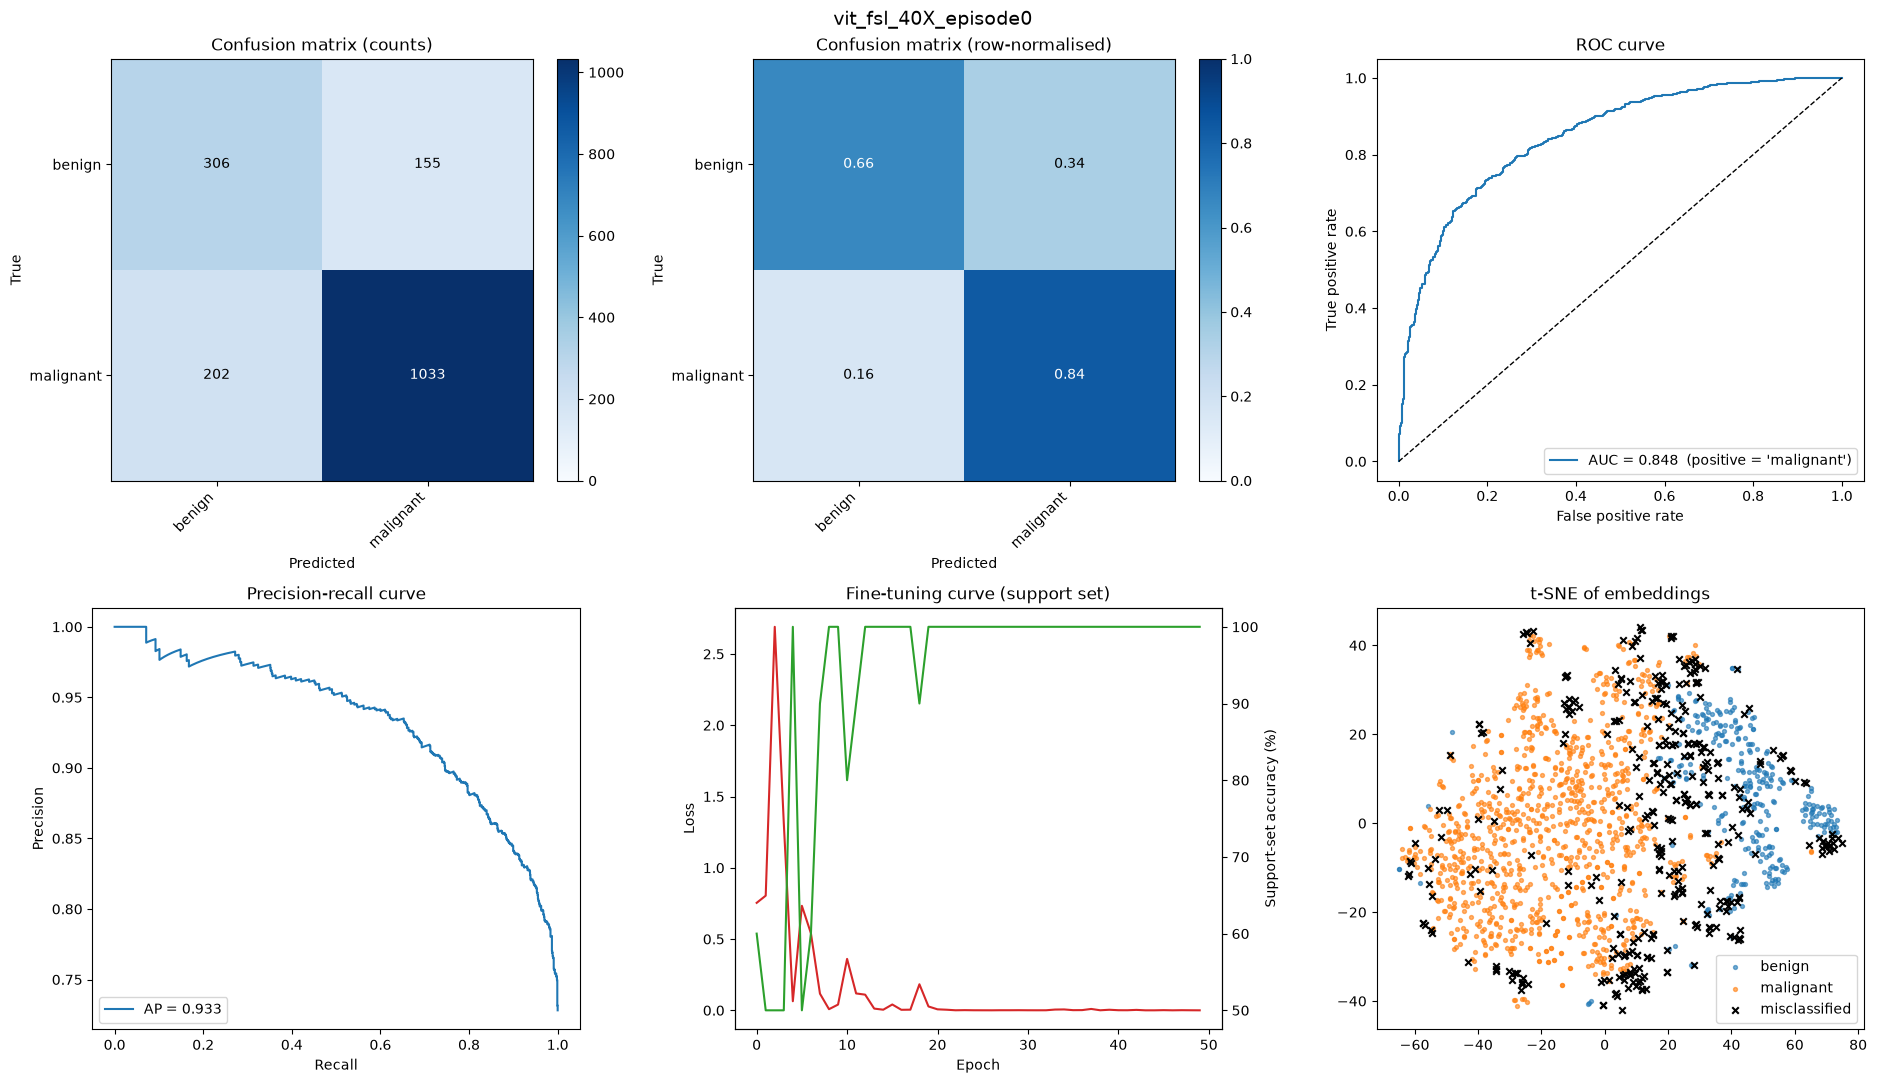


=== [40X] Episode 2/5 (seed=43) ===
support: 10 images | query: 1102 images (patient-disjoint from support)
  epoch 10/50 - loss 0.2422 - support-set acc 90.0%
  epoch 20/50 - loss 0.0637 - support-set acc 100.0%
  epoch 30/50 - loss 0.0004 - support-set acc 100.0%
  epoch 40/50 - loss 0.0001 - support-set acc 100.0%
  epoch 50/50 - loss 0.0025 - support-set acc 100.0%



----- vit_fsl_40X_episode1 -----
              precision    recall  f1-score   support

      benign      0.530     0.505     0.517       440
   malignant      0.823     0.837     0.830      1211

    accuracy                          0.749      1651
   macro avg      0.676     0.671     0.674      1651
weighted avg      0.745     0.749     0.747      1651

                  accuracy: 0.7486
         balanced_accuracy: 0.6709
           precision_macro: 0.6764
              recall_macro: 0.6709
                  f1_macro: 0.6735
               f1_weighted: 0.7466
                       mcc: 0.3473
               cohen_kappa: 0.3471
                   roc_auc: 0.7558
               sensitivity: 0.8373
               specificity: 0.5045
             avg_precision: 0.8853
             accuracy_ci95: [0.7268, 0.7686]
              roc_auc_ci95: [0.7285, 0.7811]
   majority_class_baseline: 0.7335
        test_only_accuracy: 0.8087
  test_only_balanced_accuracy: 0.7055
        test_only_f1_

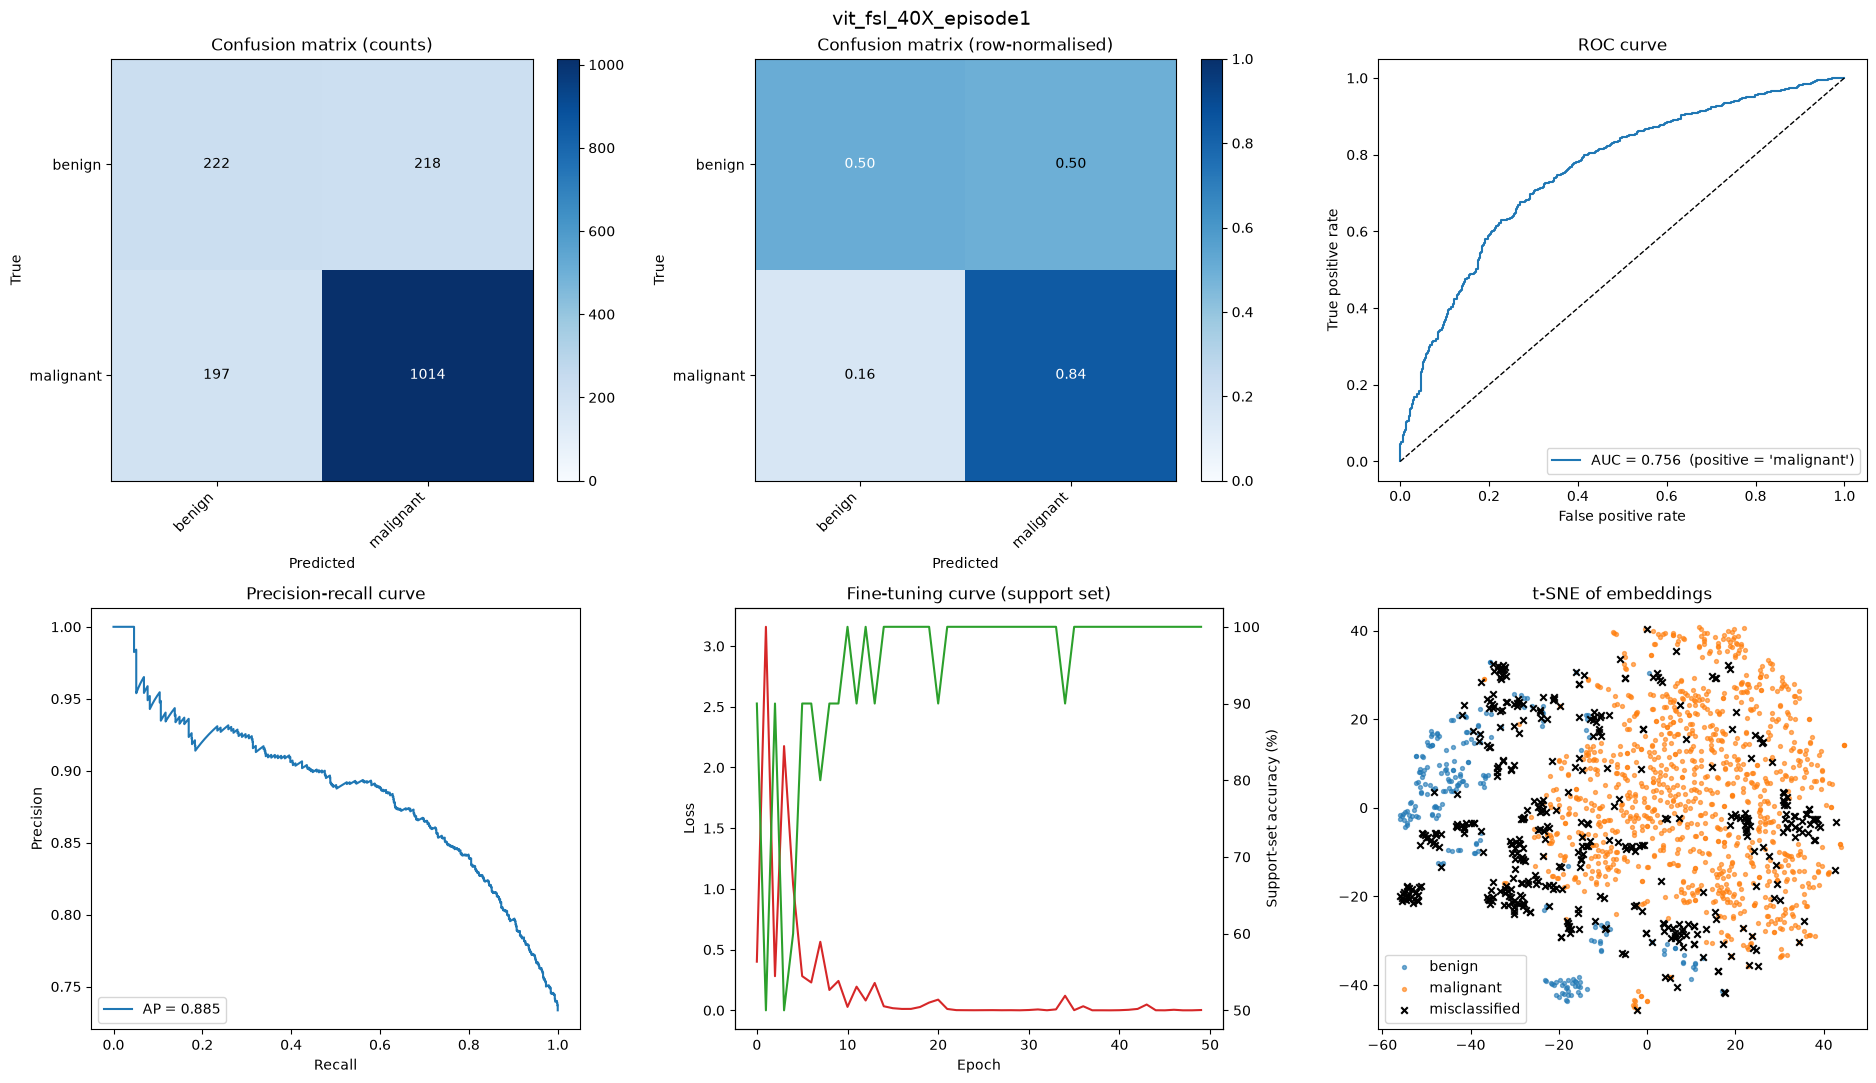


=== [40X] Episode 3/5 (seed=44) ===
support: 10 images | query: 1132 images (patient-disjoint from support)
  epoch 10/50 - loss 0.4854 - support-set acc 70.0%
  epoch 20/50 - loss 0.0095 - support-set acc 100.0%
  epoch 30/50 - loss 0.0025 - support-set acc 100.0%
  epoch 40/50 - loss 0.0008 - support-set acc 100.0%
  epoch 50/50 - loss 0.0001 - support-set acc 100.0%



----- vit_fsl_40X_episode2 -----
              precision    recall  f1-score   support

      benign      0.449     0.698     0.546       460
   malignant      0.856     0.677     0.756      1221

    accuracy                          0.683      1681
   macro avg      0.653     0.688     0.651      1681
weighted avg      0.745     0.683     0.699      1681

                  accuracy: 0.6829
         balanced_accuracy: 0.6876
           precision_macro: 0.6525
              recall_macro: 0.6876
                  f1_macro: 0.6513
               f1_weighted: 0.6988
                       mcc: 0.3383
               cohen_kappa: 0.3199
                   roc_auc: 0.7534
               sensitivity: 0.6773
               specificity: 0.6978
             avg_precision: 0.8696
             accuracy_ci95: [0.6603, 0.7043]
              roc_auc_ci95: [0.7261, 0.7800]
   majority_class_baseline: 0.7264
        test_only_accuracy: 0.7304
  test_only_balanced_accuracy: 0.7577
        test_only_f1_

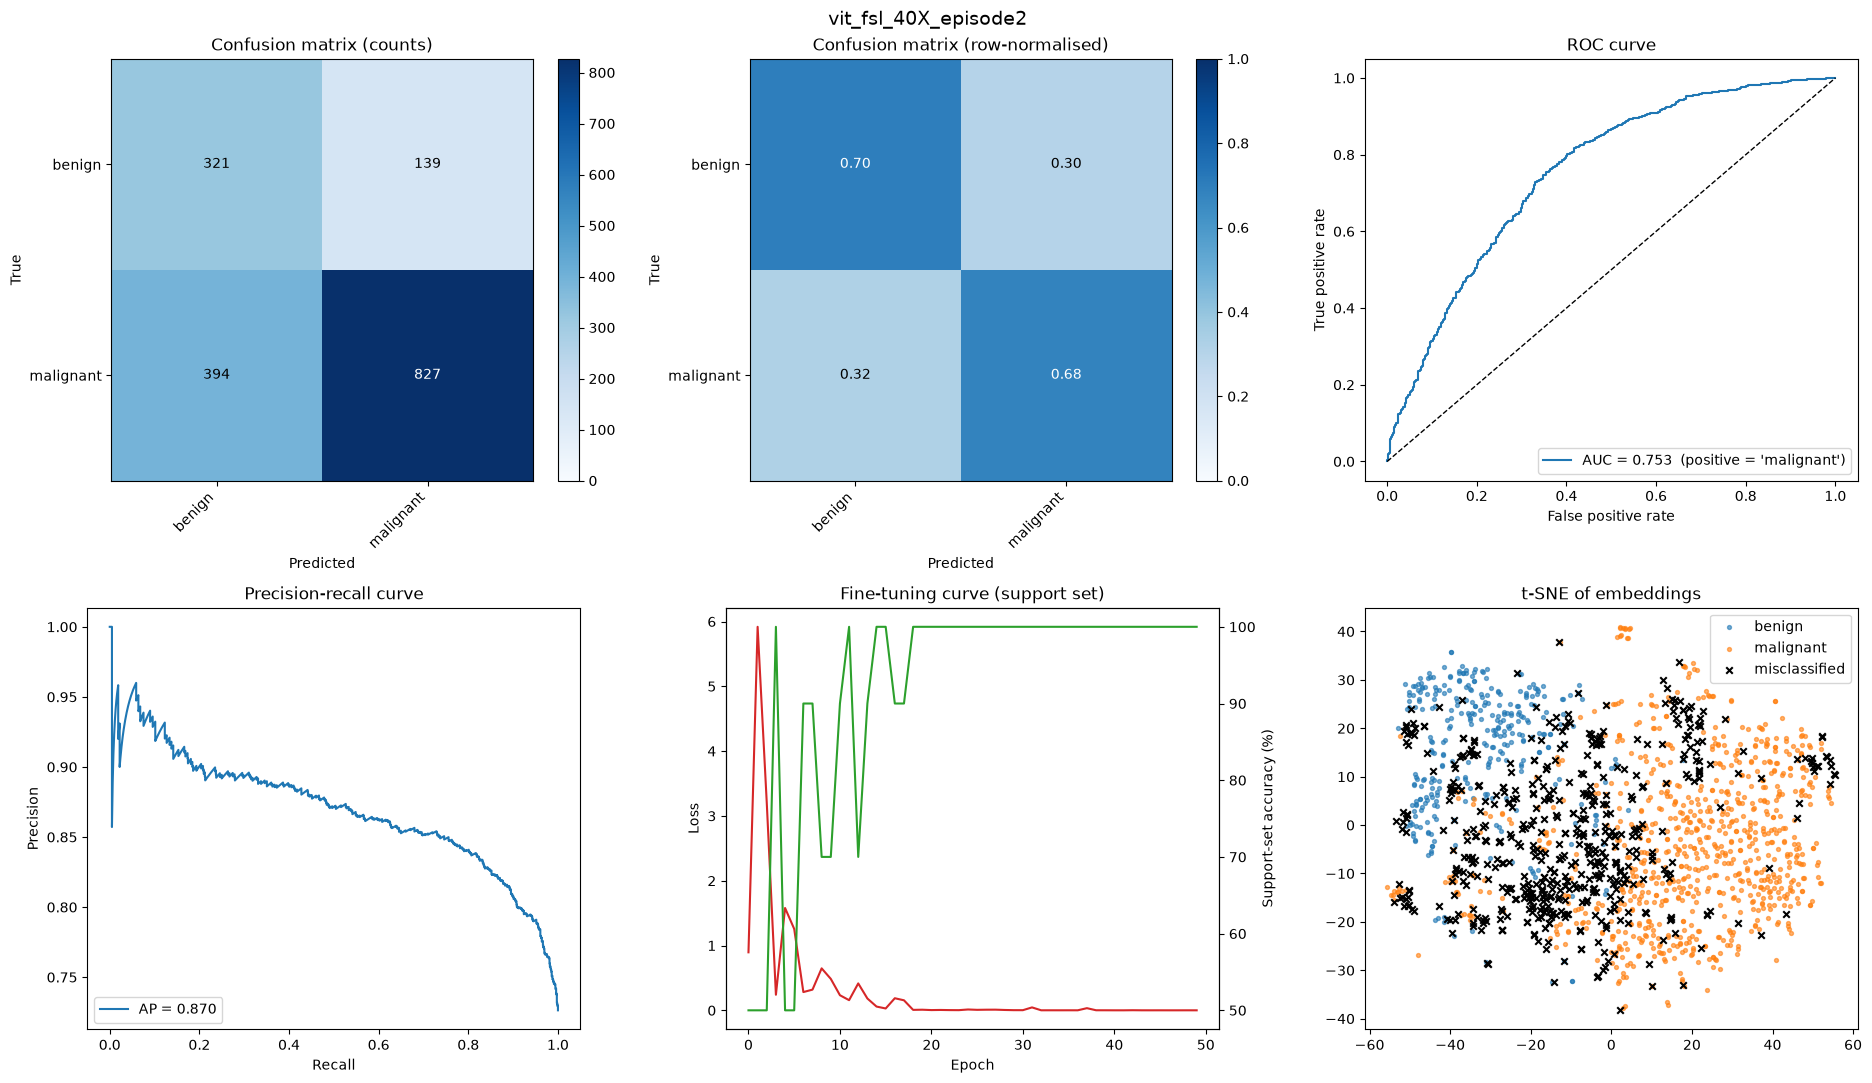


=== [40X] Episode 4/5 (seed=45) ===
support: 10 images | query: 1139 images (patient-disjoint from support)
  epoch 10/50 - loss 0.0759 - support-set acc 100.0%
  epoch 20/50 - loss 0.0090 - support-set acc 100.0%
  epoch 30/50 - loss 0.0007 - support-set acc 100.0%
  epoch 40/50 - loss 0.0004 - support-set acc 100.0%
  epoch 50/50 - loss 0.0006 - support-set acc 100.0%



----- vit_fsl_40X_episode3 -----
              precision    recall  f1-score   support

      benign      0.468     0.725     0.569       483
   malignant      0.859     0.670     0.752      1205

    accuracy                          0.685      1688
   macro avg      0.663     0.697     0.661      1688
weighted avg      0.747     0.685     0.700      1688

                  accuracy: 0.6854
         balanced_accuracy: 0.6972
           precision_macro: 0.6632
              recall_macro: 0.6972
                  f1_macro: 0.6605
               f1_weighted: 0.6999
                       mcc: 0.3588
               cohen_kappa: 0.3387
                   roc_auc: 0.7667
               sensitivity: 0.6697
               specificity: 0.7246
             avg_precision: 0.8953
             accuracy_ci95: [0.6635, 0.7086]
              roc_auc_ci95: [0.7440, 0.7898]
   majority_class_baseline: 0.7139
        test_only_accuracy: 0.6794
  test_only_balanced_accuracy: 0.7212
        test_only_f1_

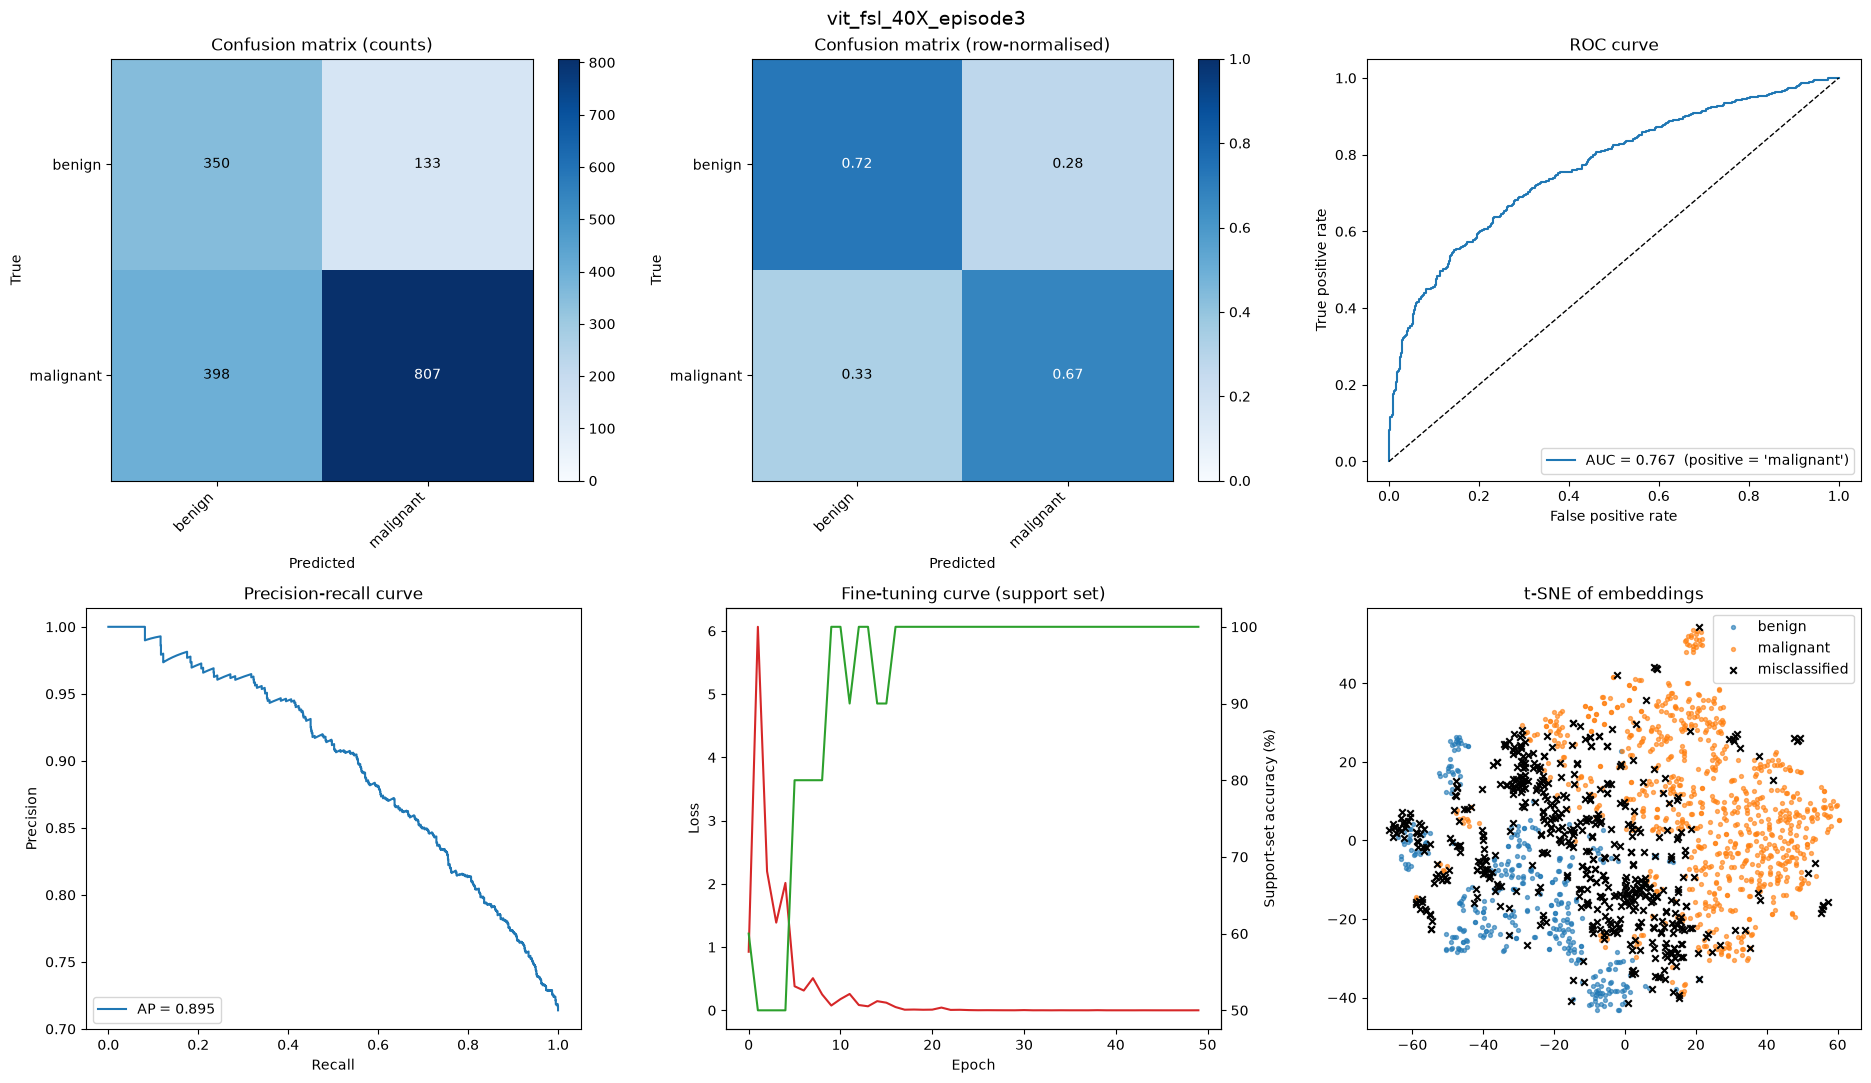


=== [40X] Episode 5/5 (seed=46) ===
support: 10 images | query: 1105 images (patient-disjoint from support)
  epoch 10/50 - loss 0.2264 - support-set acc 100.0%
  epoch 20/50 - loss 0.0149 - support-set acc 100.0%
  epoch 30/50 - loss 0.0016 - support-set acc 100.0%
  epoch 40/50 - loss 0.0377 - support-set acc 100.0%
  epoch 50/50 - loss 0.0001 - support-set acc 100.0%



----- vit_fsl_40X_episode4 -----
              precision    recall  f1-score   support

      benign      0.480     0.847     0.613       445
   malignant      0.922     0.662     0.770      1209

    accuracy                          0.712      1654
   macro avg      0.701     0.754     0.691      1654
weighted avg      0.803     0.712     0.728      1654

                  accuracy: 0.7116
         balanced_accuracy: 0.7544
           precision_macro: 0.7007
              recall_macro: 0.7544
                  f1_macro: 0.6914
               f1_weighted: 0.7279
                       mcc: 0.4519
               cohen_kappa: 0.4097
                   roc_auc: 0.8578
               sensitivity: 0.6617
               specificity: 0.8472
             avg_precision: 0.9357
             accuracy_ci95: [0.6911, 0.7322]
              roc_auc_ci95: [0.8375, 0.8773]
   majority_class_baseline: 0.7310
        test_only_accuracy: 0.7195
  test_only_balanced_accuracy: 0.7718
        test_only_f1_

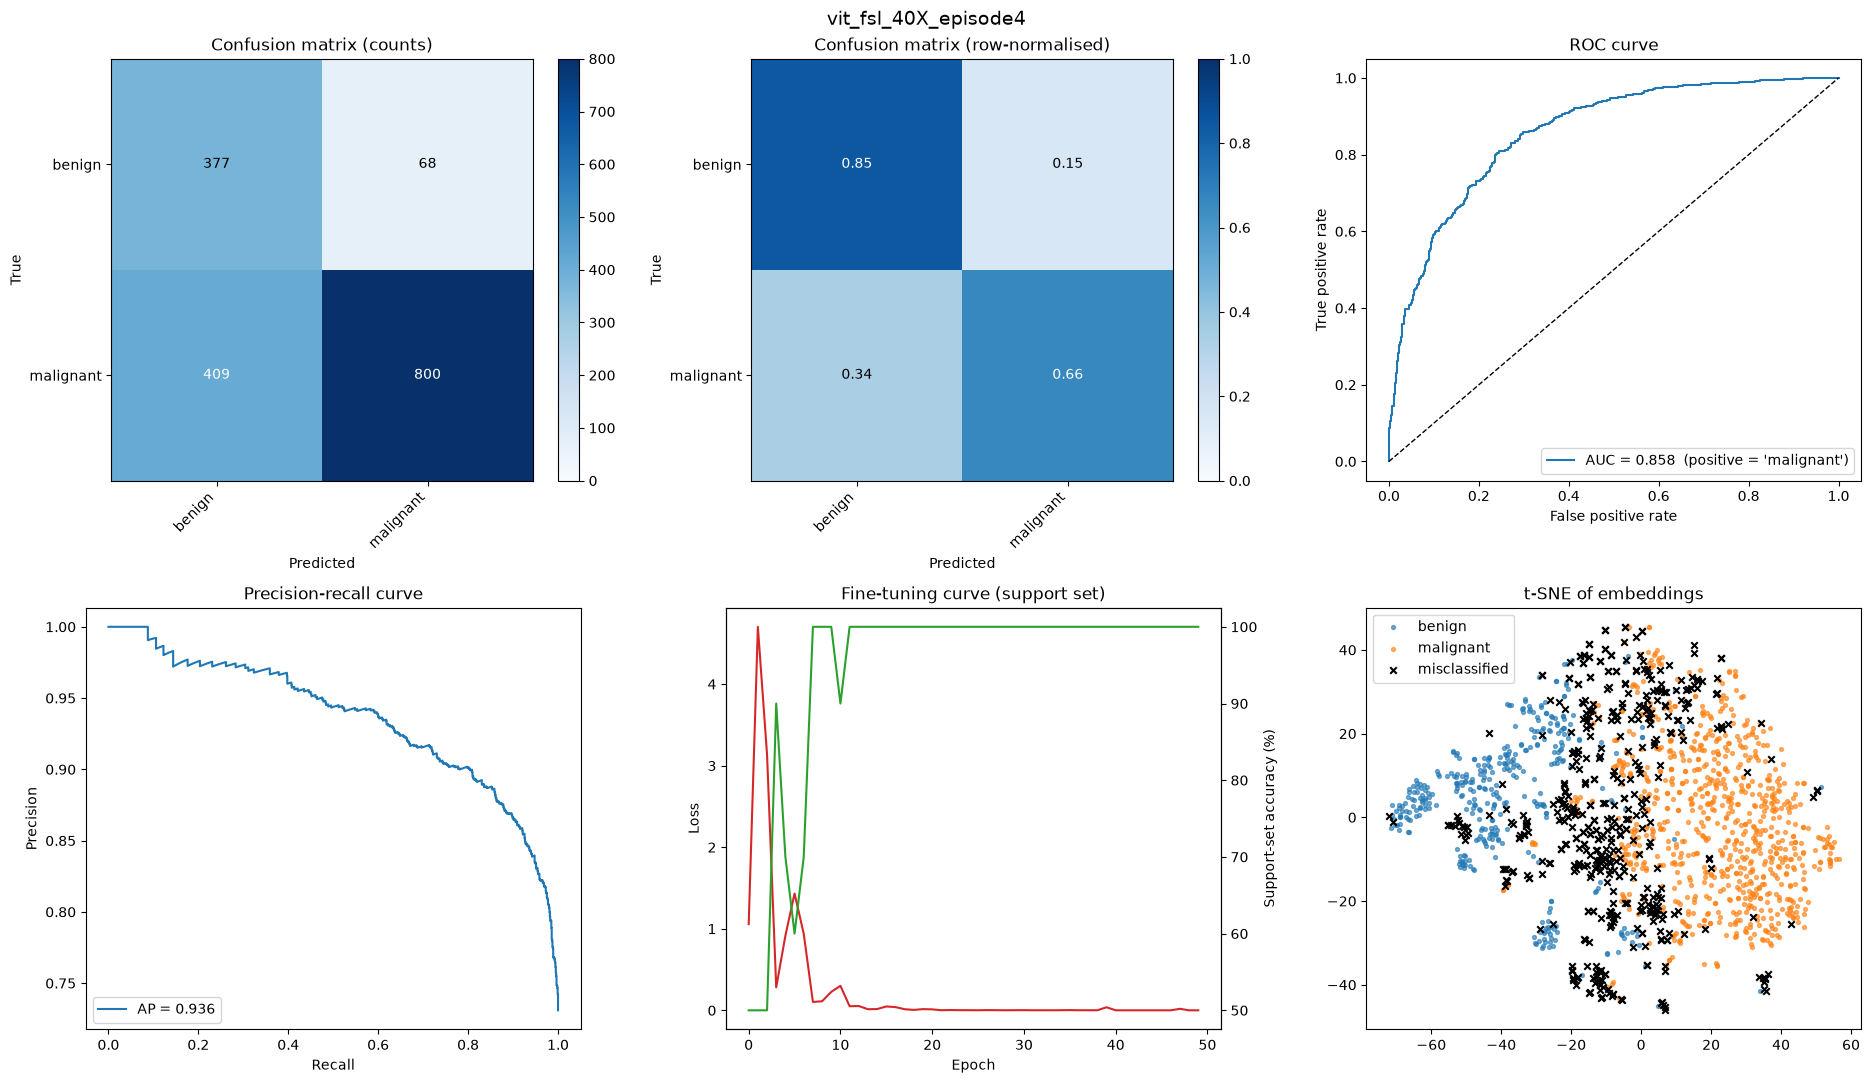


===== vit_fsl_40X: summary over 5 episode(s) =====
                                     mean     std
accuracy                           0.7236  0.0406
balanced_accuracy                  0.7120  0.0339
precision_macro                    0.6858  0.0298
recall_macro                       0.7120  0.0339
f1_macro                           0.6838  0.0321
f1_weighted                        0.7332  0.0347
mcc                                0.3964  0.0605
cohen_kappa                        0.3800  0.0604
roc_auc                            0.7964  0.0466
sensitivity                        0.7365  0.0821
specificity                        0.6876  0.1105
avg_precision                      0.9038  0.0263
majority_class_baseline            0.7266  0.0068
test_only_accuracy                 0.7450  0.0469
test_only_balanced_accuracy        0.7432  0.0253
test_only_f1_macro                 0.7023  0.0287
test_only_roc_auc                  0.8385  0.0372
test_only_majority_class_baseline  0.7468  0.000


----- vit_fsl_100X_episode0 -----
              precision    recall  f1-score   support

      benign      0.437     0.836     0.574       475
   malignant      0.907     0.598     0.720      1270

    accuracy                          0.662      1745
   macro avg      0.672     0.717     0.647      1745
weighted avg      0.779     0.662     0.681      1745

                  accuracy: 0.6625
         balanced_accuracy: 0.7167
           precision_macro: 0.6720
              recall_macro: 0.7167
                  f1_macro: 0.6473
               f1_weighted: 0.6806
                       mcc: 0.3862
               cohen_kappa: 0.3372
                   roc_auc: 0.8099
               sensitivity: 0.5976
               specificity: 0.8358
             avg_precision: 0.9142
             accuracy_ci95: [0.6395, 0.6848]
              roc_auc_ci95: [0.7855, 0.8317]
   majority_class_baseline: 0.7278
        test_only_accuracy: 0.6791
  test_only_balanced_accuracy: 0.7249
        test_only_f1

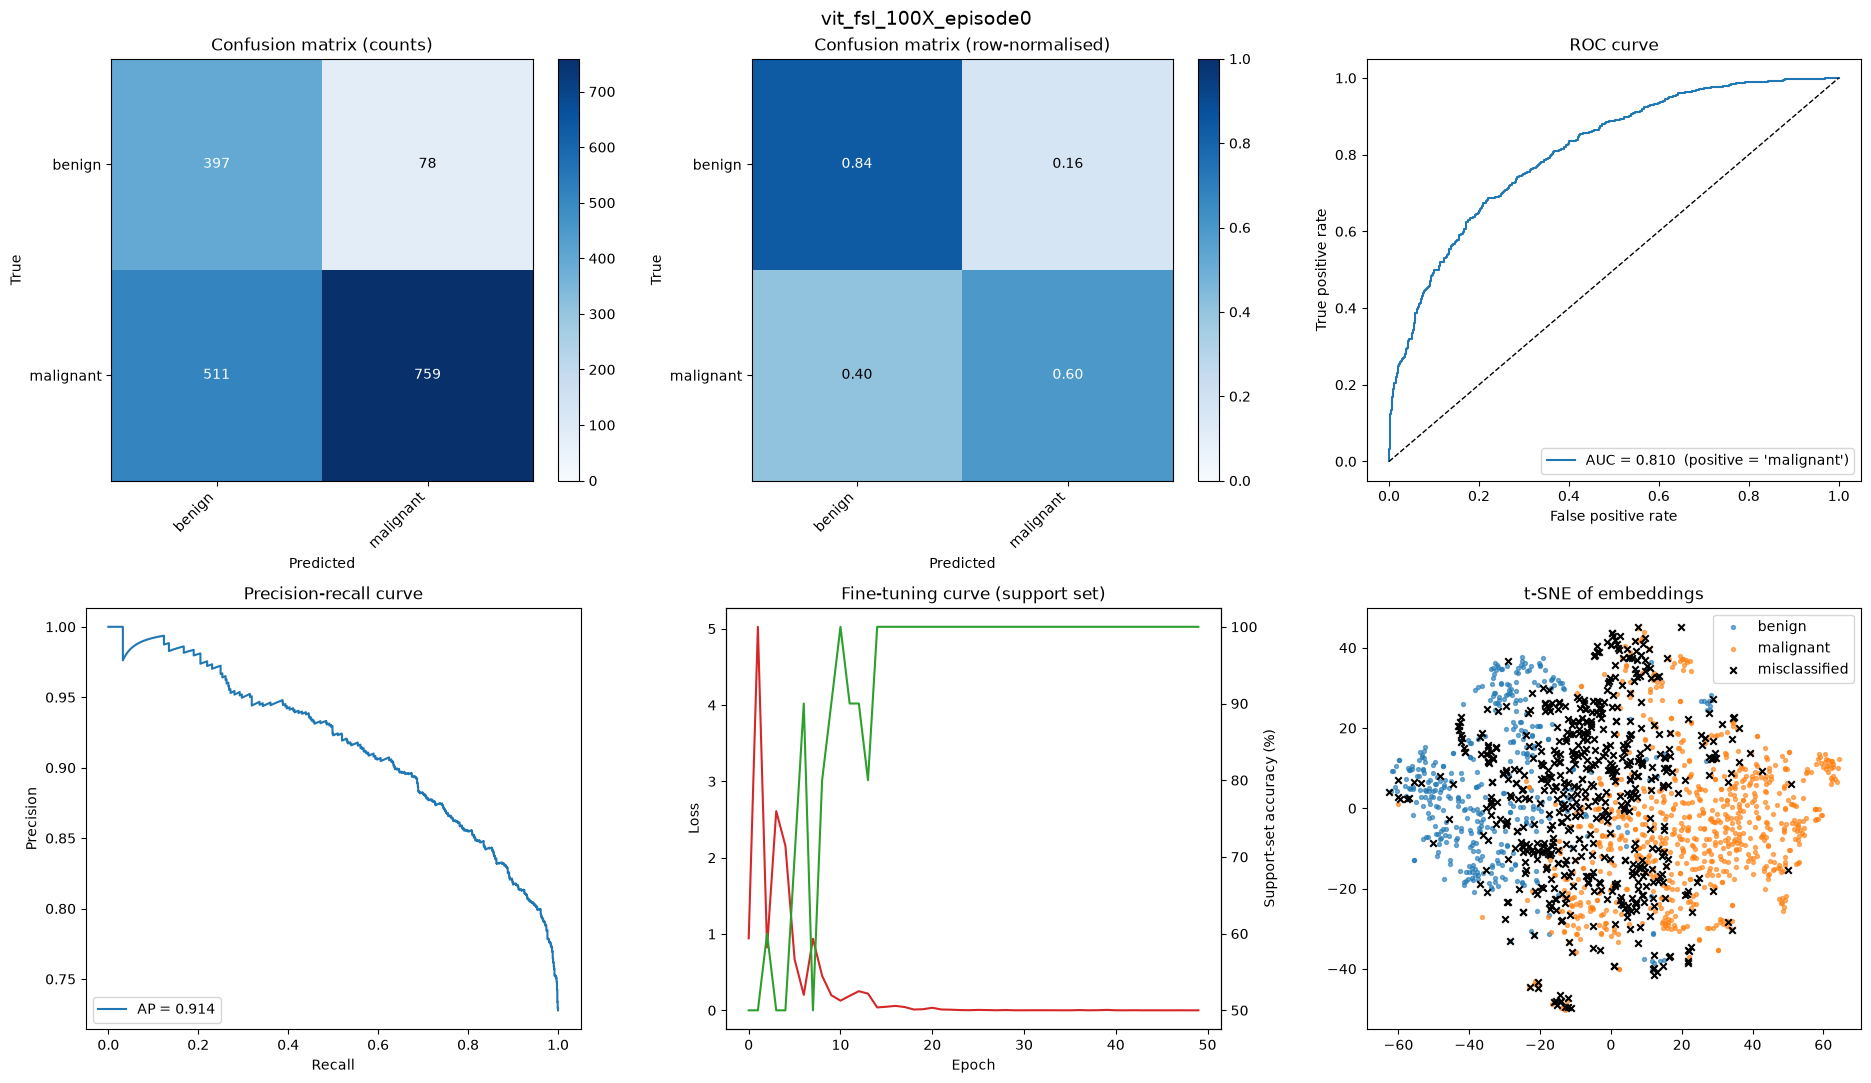


=== [100X] Episode 2/5 (seed=43) ===
support: 10 images | query: 1205 images (patient-disjoint from support)
  epoch 10/50 - loss 0.2341 - support-set acc 80.0%
  epoch 20/50 - loss 0.0193 - support-set acc 100.0%
  epoch 30/50 - loss 0.1836 - support-set acc 90.0%
  epoch 40/50 - loss 0.0001 - support-set acc 100.0%
  epoch 50/50 - loss 0.0000 - support-set acc 100.0%



----- vit_fsl_100X_episode1 -----
              precision    recall  f1-score   support

      benign      0.536     0.619     0.575       464
   malignant      0.856     0.810     0.832      1302

    accuracy                          0.759      1766
   macro avg      0.696     0.714     0.703      1766
weighted avg      0.772     0.759     0.765      1766

                  accuracy: 0.7593
         balanced_accuracy: 0.7140
           precision_macro: 0.6963
              recall_macro: 0.7140
                  f1_macro: 0.7034
               f1_weighted: 0.7645
                       mcc: 0.4100
               cohen_kappa: 0.4080
                   roc_auc: 0.8006
               sensitivity: 0.8095
               specificity: 0.6185
             avg_precision: 0.9140
             accuracy_ci95: [0.7395, 0.7780]
              roc_auc_ci95: [0.7780, 0.8229]
   majority_class_baseline: 0.7373
        test_only_accuracy: 0.7611
  test_only_balanced_accuracy: 0.7257
        test_only_f1

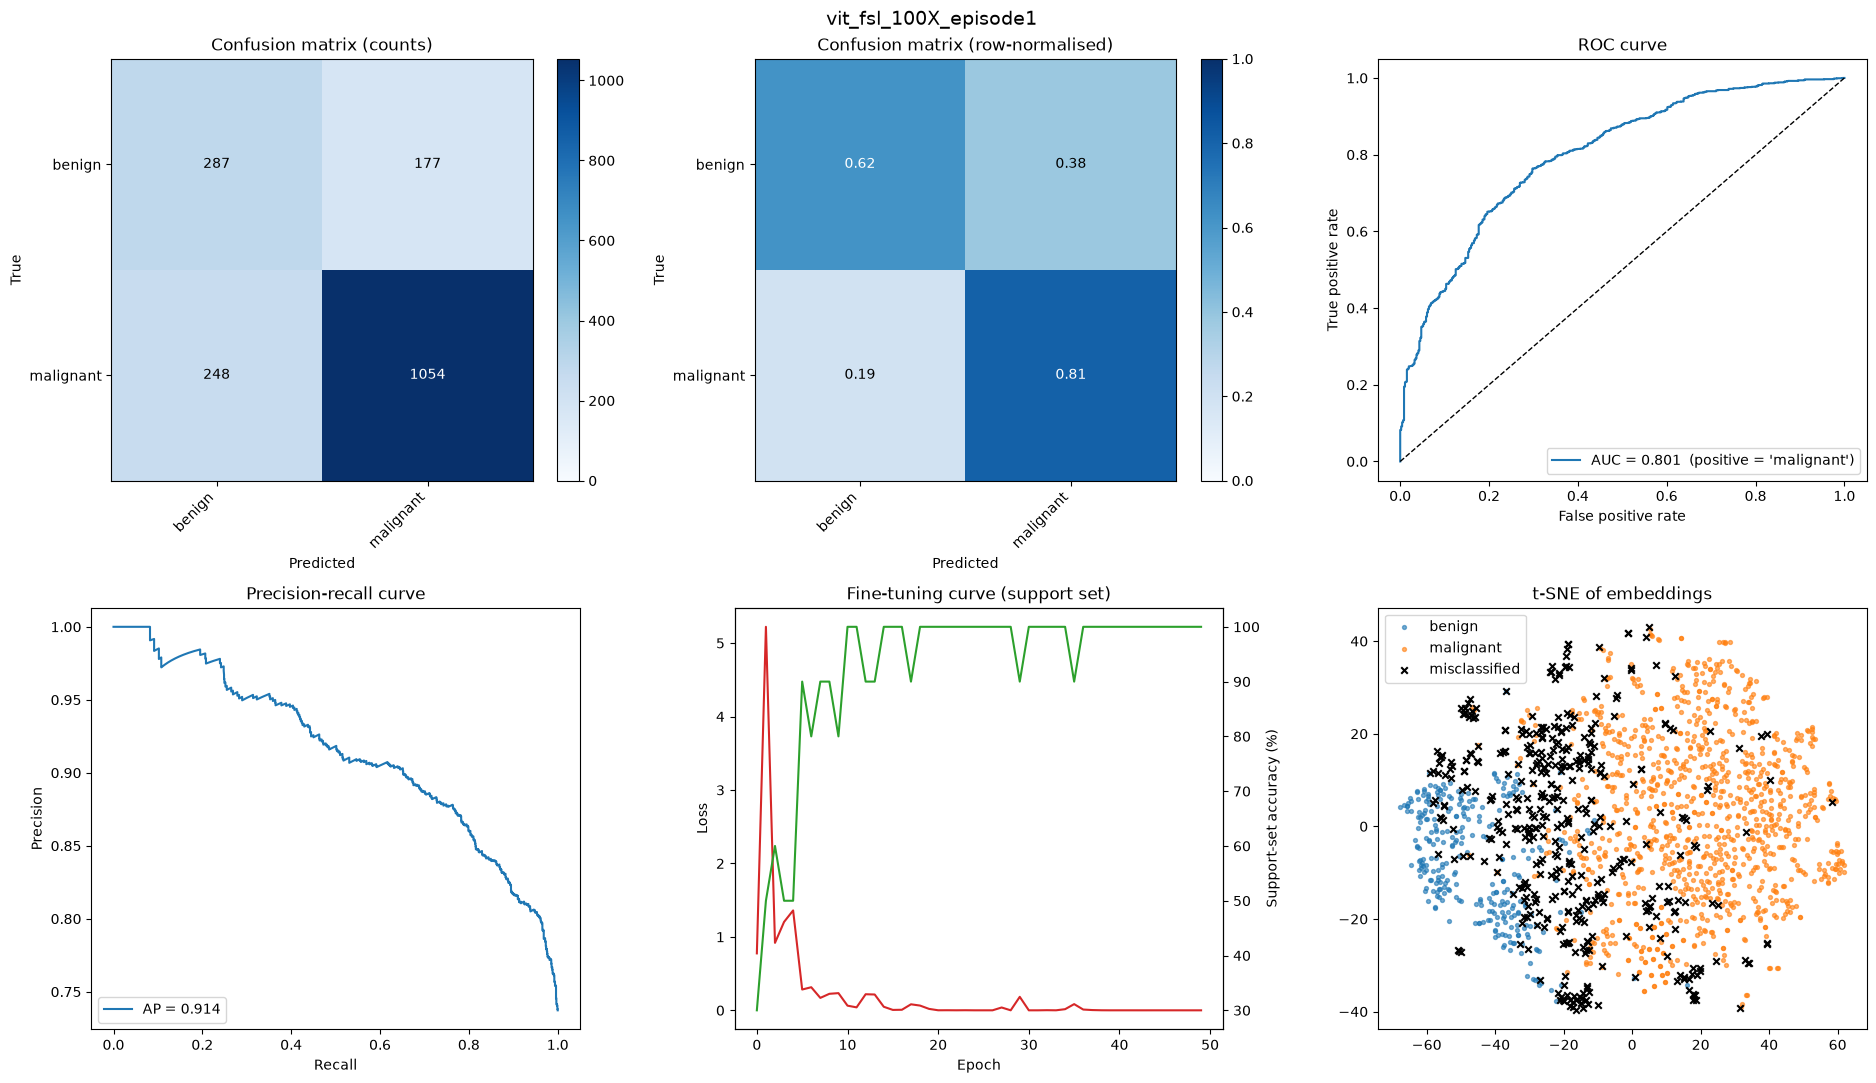


=== [100X] Episode 3/5 (seed=44) ===
support: 10 images | query: 1242 images (patient-disjoint from support)
  epoch 10/50 - loss 0.6090 - support-set acc 70.0%
  epoch 20/50 - loss 0.0298 - support-set acc 100.0%
  epoch 30/50 - loss 0.0197 - support-set acc 100.0%
  epoch 40/50 - loss 0.0005 - support-set acc 100.0%
  epoch 50/50 - loss 0.0061 - support-set acc 100.0%



----- vit_fsl_100X_episode2 -----
              precision    recall  f1-score   support

      benign      0.373     0.571     0.452       462
   malignant      0.819     0.670     0.737      1341

    accuracy                          0.644      1803
   macro avg      0.596     0.621     0.594      1803
weighted avg      0.705     0.644     0.664      1803

                  accuracy: 0.6445
         balanced_accuracy: 0.6205
           precision_macro: 0.5964
              recall_macro: 0.6205
                  f1_macro: 0.5943
               f1_weighted: 0.6639
                       mcc: 0.2156
               cohen_kappa: 0.2054
                   roc_auc: 0.6864
               sensitivity: 0.6696
               specificity: 0.5714
             avg_precision: 0.8535
             accuracy_ci95: [0.6217, 0.6656]
              roc_auc_ci95: [0.6561, 0.7138]
   majority_class_baseline: 0.7438
        test_only_accuracy: 0.6524
  test_only_balanced_accuracy: 0.6328
        test_only_f1

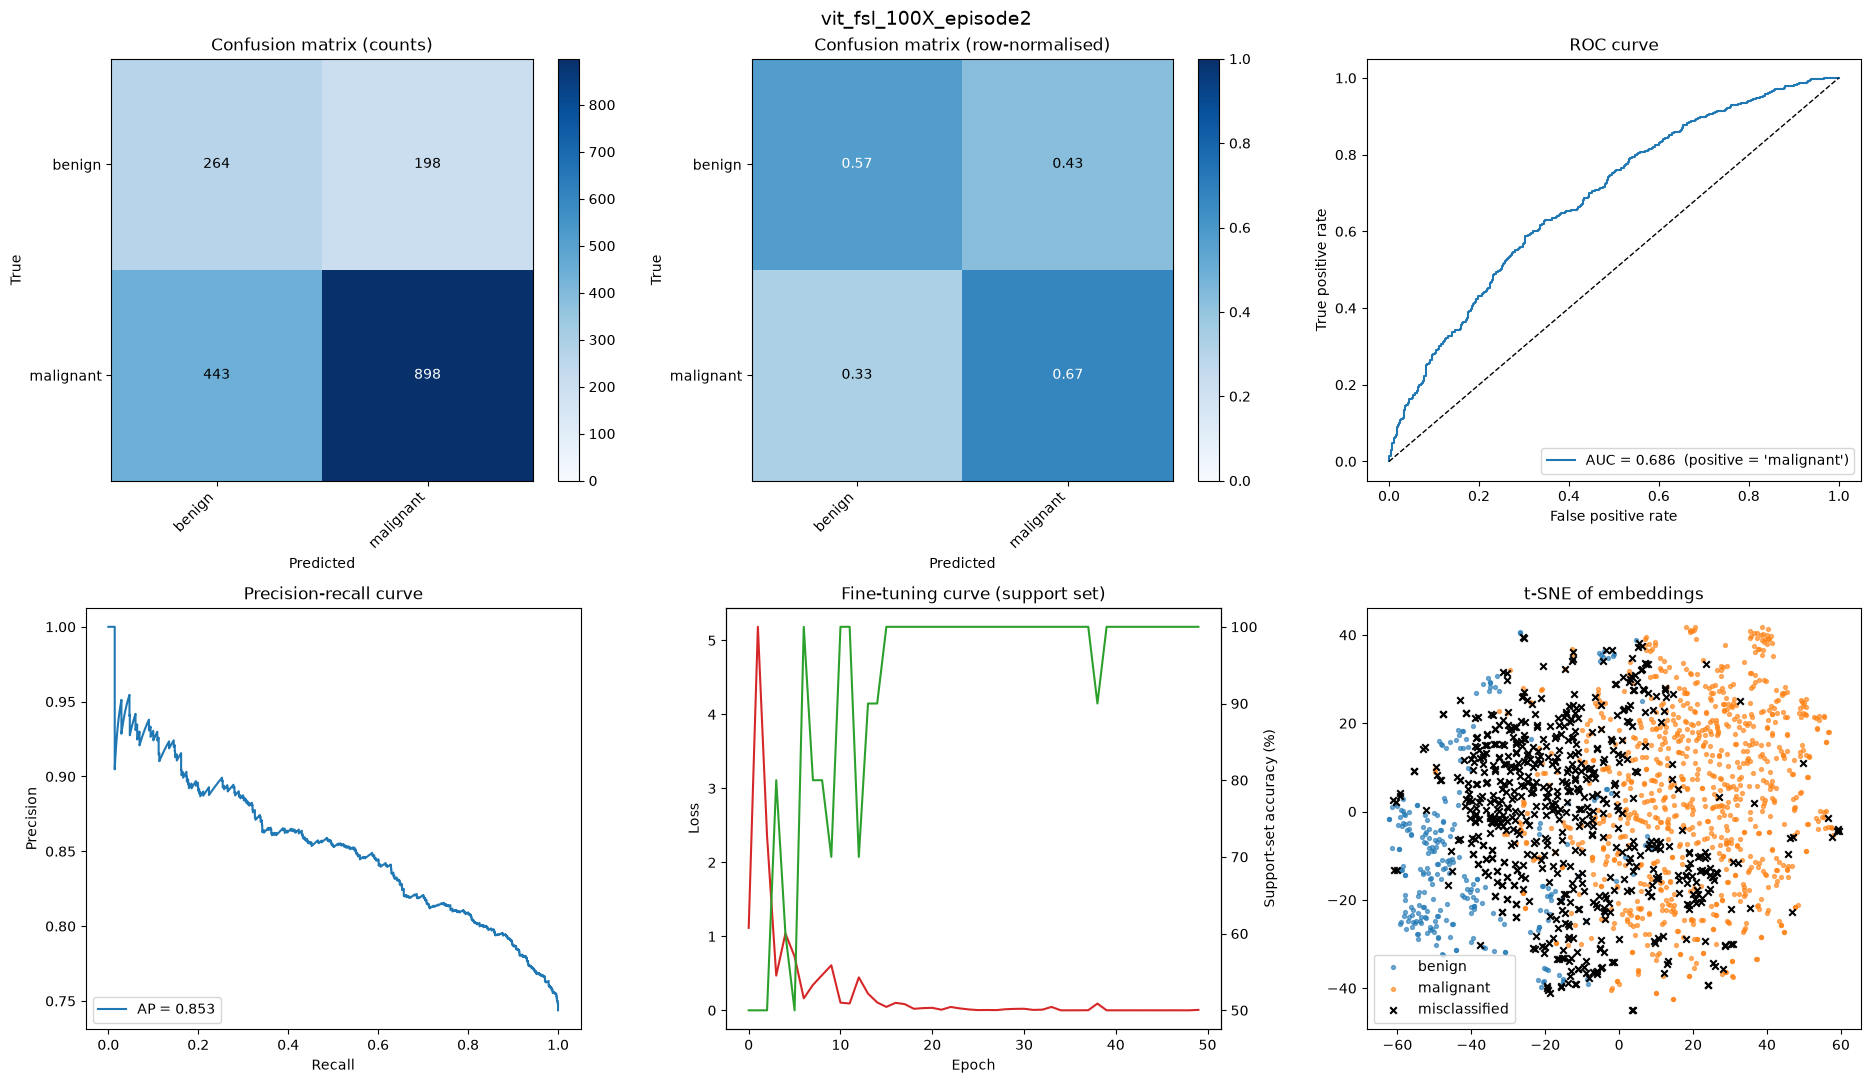


=== [100X] Episode 4/5 (seed=45) ===
support: 10 images | query: 1158 images (patient-disjoint from support)
  epoch 10/50 - loss 0.1361 - support-set acc 90.0%
  epoch 20/50 - loss 0.0279 - support-set acc 100.0%
  epoch 30/50 - loss 0.0068 - support-set acc 100.0%
  epoch 40/50 - loss 0.0009 - support-set acc 100.0%
  epoch 50/50 - loss 0.0012 - support-set acc 100.0%



----- vit_fsl_100X_episode3 -----
              precision    recall  f1-score   support

      benign      0.290     0.789     0.424       445
   malignant      0.815     0.325     0.465      1274

    accuracy                          0.445      1719
   macro avg      0.552     0.557     0.444      1719
weighted avg      0.679     0.445     0.454      1719

                  accuracy: 0.4450
         balanced_accuracy: 0.5569
           precision_macro: 0.5524
              recall_macro: 0.5569
                  f1_macro: 0.4443
               f1_weighted: 0.4541
                       mcc: 0.1092
               cohen_kappa: 0.0729
                   roc_auc: 0.5610
               sensitivity: 0.3250
               specificity: 0.7888
             avg_precision: 0.7869
             accuracy_ci95: [0.4212, 0.4706]
              roc_auc_ci95: [0.5312, 0.5917]
   majority_class_baseline: 0.7411
        test_only_accuracy: 0.5080
  test_only_balanced_accuracy: 0.5900
        test_only_f1

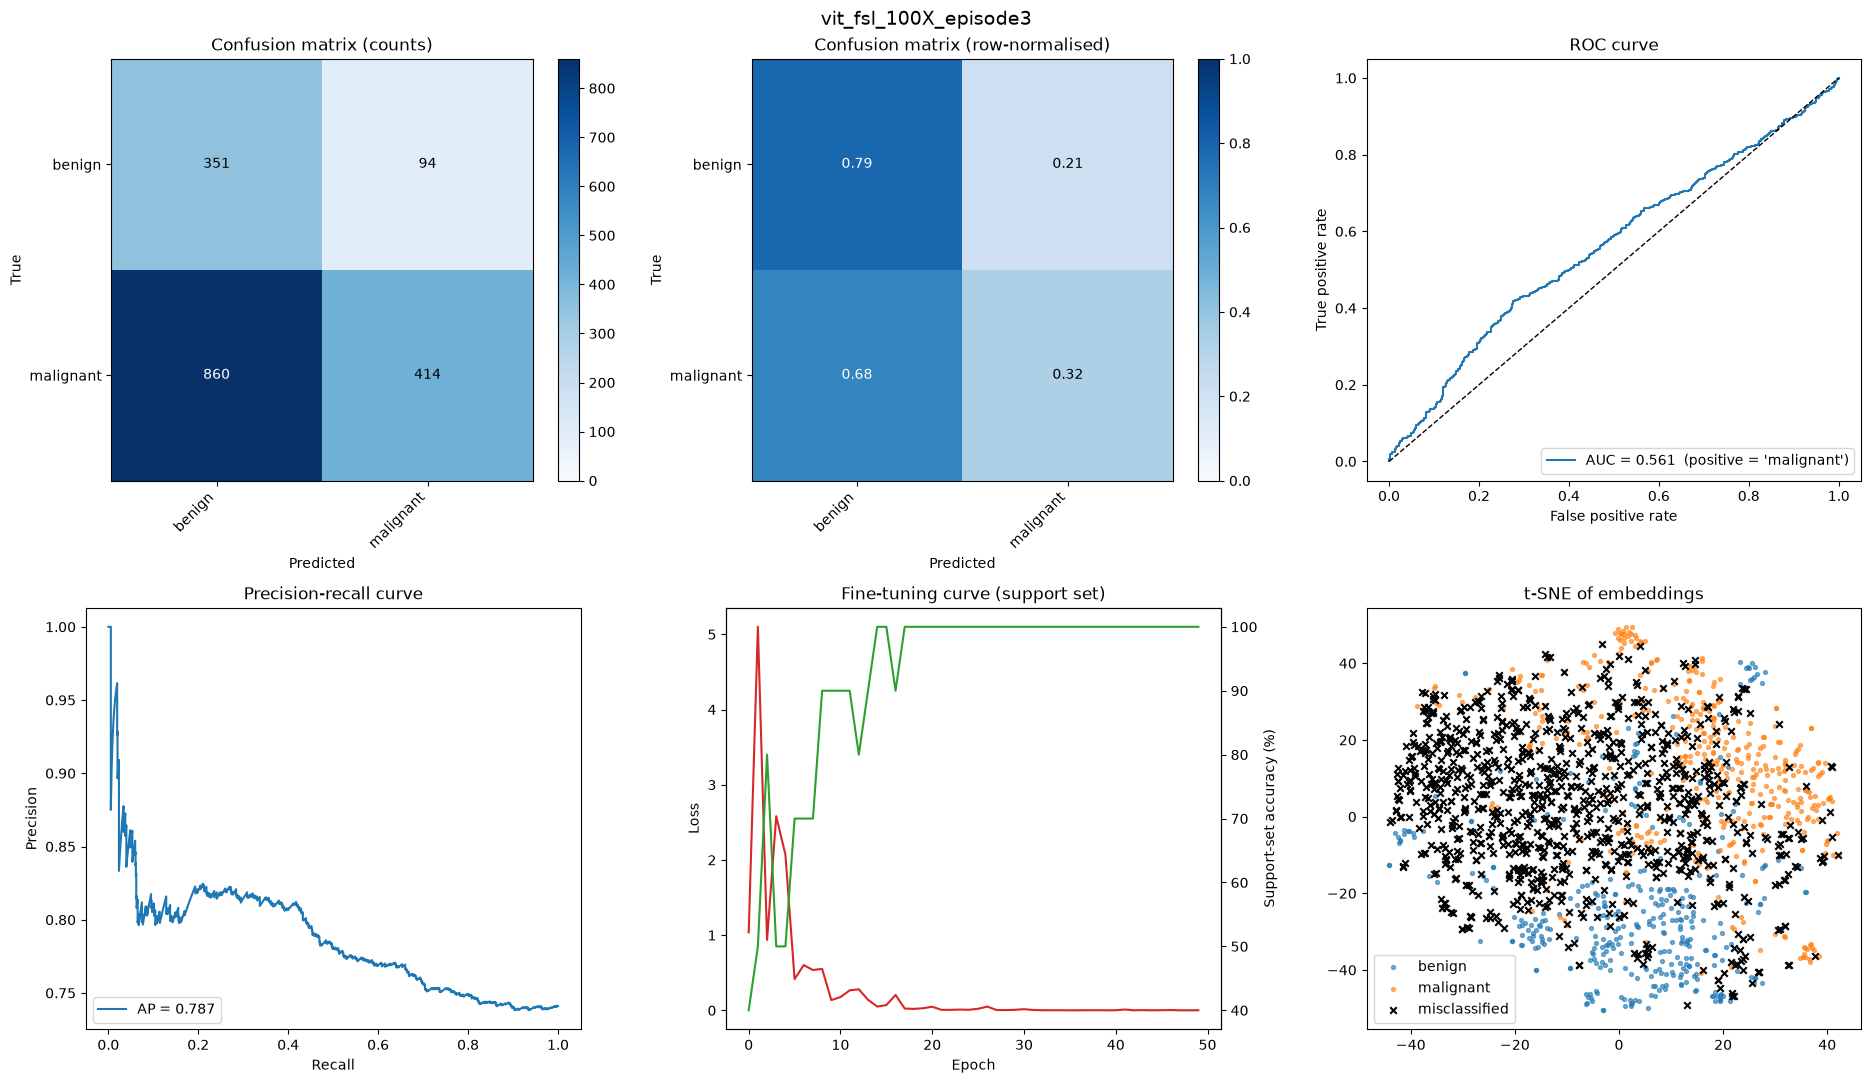


=== [100X] Episode 5/5 (seed=46) ===
support: 10 images | query: 1184 images (patient-disjoint from support)
  epoch 10/50 - loss 0.7269 - support-set acc 70.0%
  epoch 20/50 - loss 0.0134 - support-set acc 100.0%
  epoch 30/50 - loss 0.0054 - support-set acc 100.0%
  epoch 40/50 - loss 0.0067 - support-set acc 100.0%
  epoch 50/50 - loss 0.0005 - support-set acc 100.0%



----- vit_fsl_100X_episode4 -----
              precision    recall  f1-score   support

      benign      0.350     0.624     0.448       436
   malignant      0.831     0.614     0.706      1309

    accuracy                          0.617      1745
   macro avg      0.590     0.619     0.577      1745
weighted avg      0.711     0.617     0.642      1745

                  accuracy: 0.6166
         balanced_accuracy: 0.6190
           precision_macro: 0.5903
              recall_macro: 0.6190
                  f1_macro: 0.5773
               f1_weighted: 0.6418
                       mcc: 0.2074
               cohen_kappa: 0.1888
                   roc_auc: 0.6824
               sensitivity: 0.6142
               specificity: 0.6239
             avg_precision: 0.8555
             accuracy_ci95: [0.5926, 0.6407]
              roc_auc_ci95: [0.6511, 0.7130]
   majority_class_baseline: 0.7501
        test_only_accuracy: 0.6203
  test_only_balanced_accuracy: 0.6139
        test_only_f1

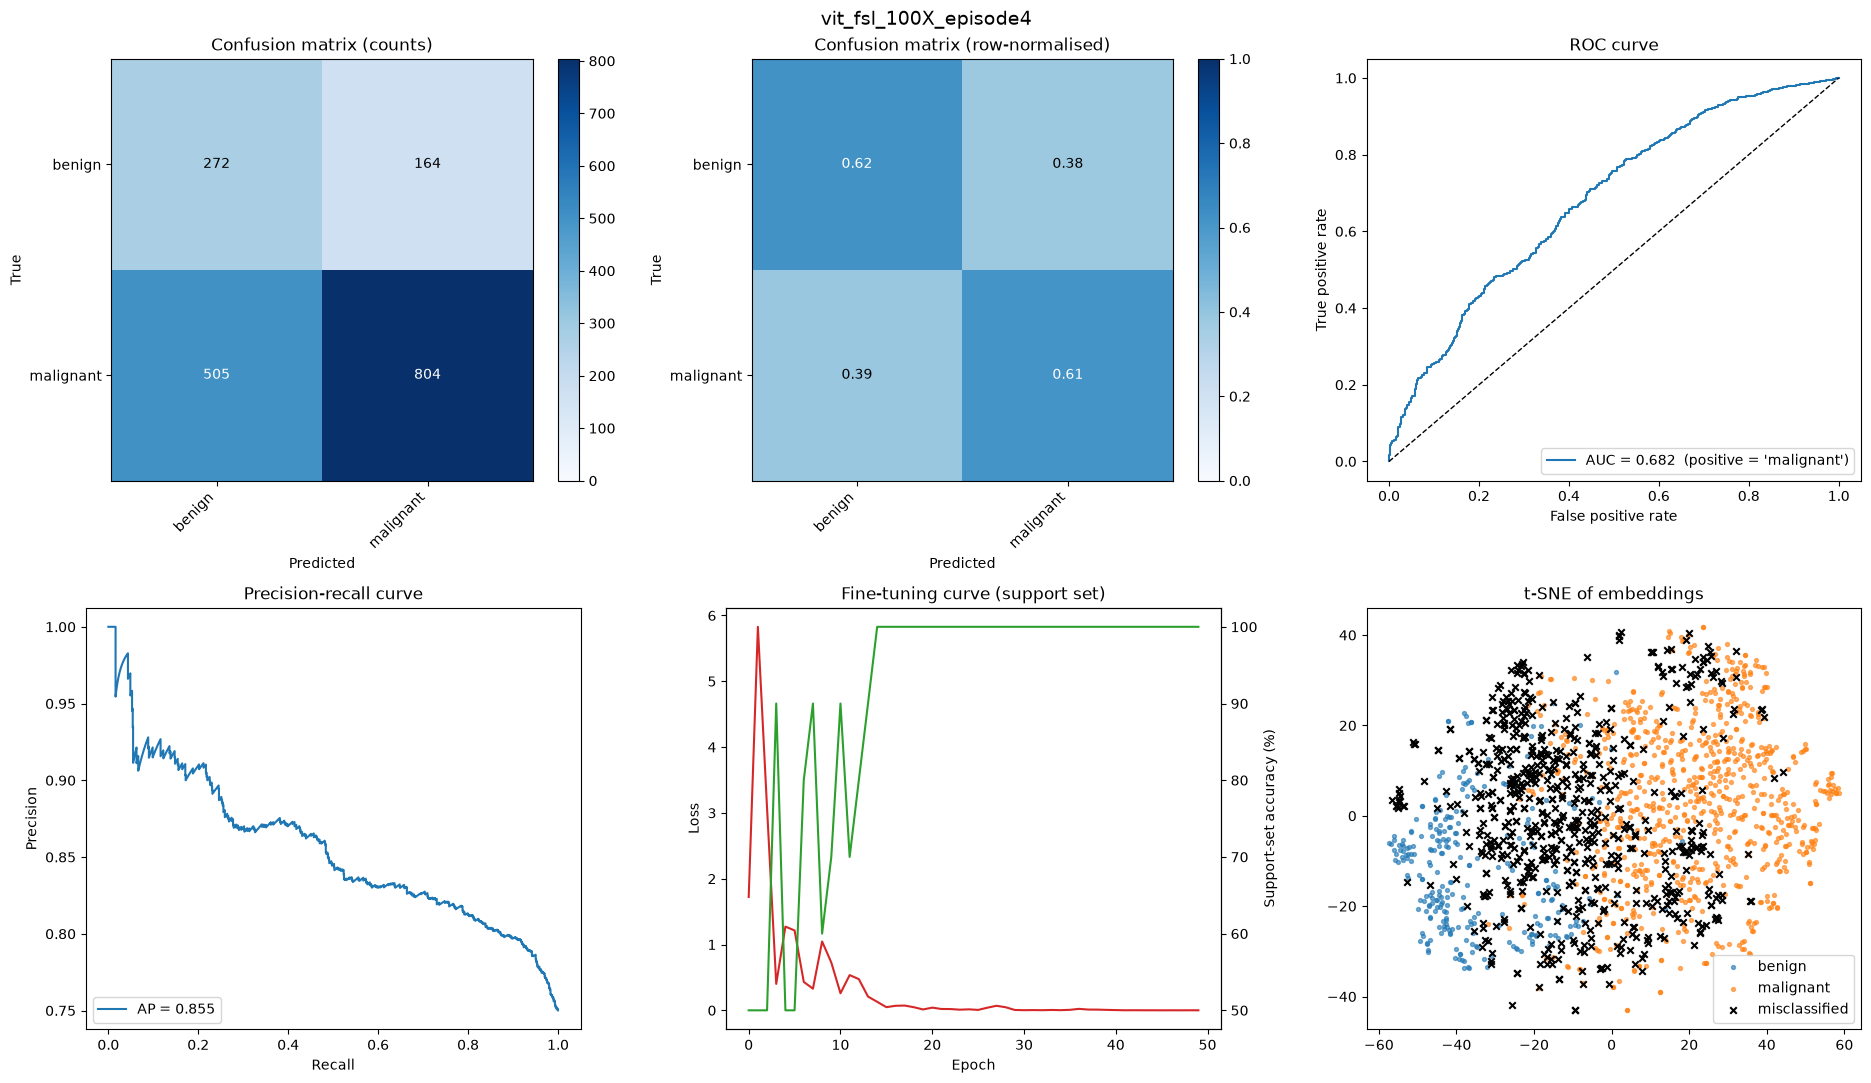


===== vit_fsl_100X: summary over 5 episode(s) =====
                                     mean     std
accuracy                           0.6256  0.1023
balanced_accuracy                  0.6454  0.0616
precision_macro                    0.6215  0.0539
recall_macro                       0.6454  0.0616
f1_macro                           0.5933  0.0866
f1_weighted                        0.6410  0.1023
mcc                                0.2656  0.1147
cohen_kappa                        0.2425  0.1178
roc_auc                            0.7081  0.0913
sensitivity                        0.6032  0.1578
specificity                        0.6877  0.1044
avg_precision                      0.8648  0.0472
majority_class_baseline            0.7400  0.0074
test_only_accuracy                 0.6442  0.0826
test_only_balanced_accuracy        0.6575  0.0571
test_only_f1_macro                 0.6189  0.0716
test_only_roc_auc                  0.7202  0.0711
test_only_majority_class_baseline  0.7112  0.00


----- vit_fsl_200X_episode0 -----
              precision    recall  f1-score   support

      benign      0.332     0.388     0.358       492
   malignant      0.745     0.696     0.720      1264

    accuracy                          0.610      1756
   macro avg      0.539     0.542     0.539      1756
weighted avg      0.629     0.610     0.618      1756

                  accuracy: 0.6099
         balanced_accuracy: 0.5422
           precision_macro: 0.5387
              recall_macro: 0.5422
                  f1_macro: 0.5389
               f1_weighted: 0.6185
                       mcc: 0.0808
               cohen_kappa: 0.0803
                   roc_auc: 0.5620
               sensitivity: 0.6962
               specificity: 0.3882
             avg_precision: 0.7630
             accuracy_ci95: [0.5888, 0.6327]
              roc_auc_ci95: [0.5342, 0.5922]
   majority_class_baseline: 0.7198
        test_only_accuracy: 0.6289
  test_only_balanced_accuracy: 0.5692
        test_only_f1

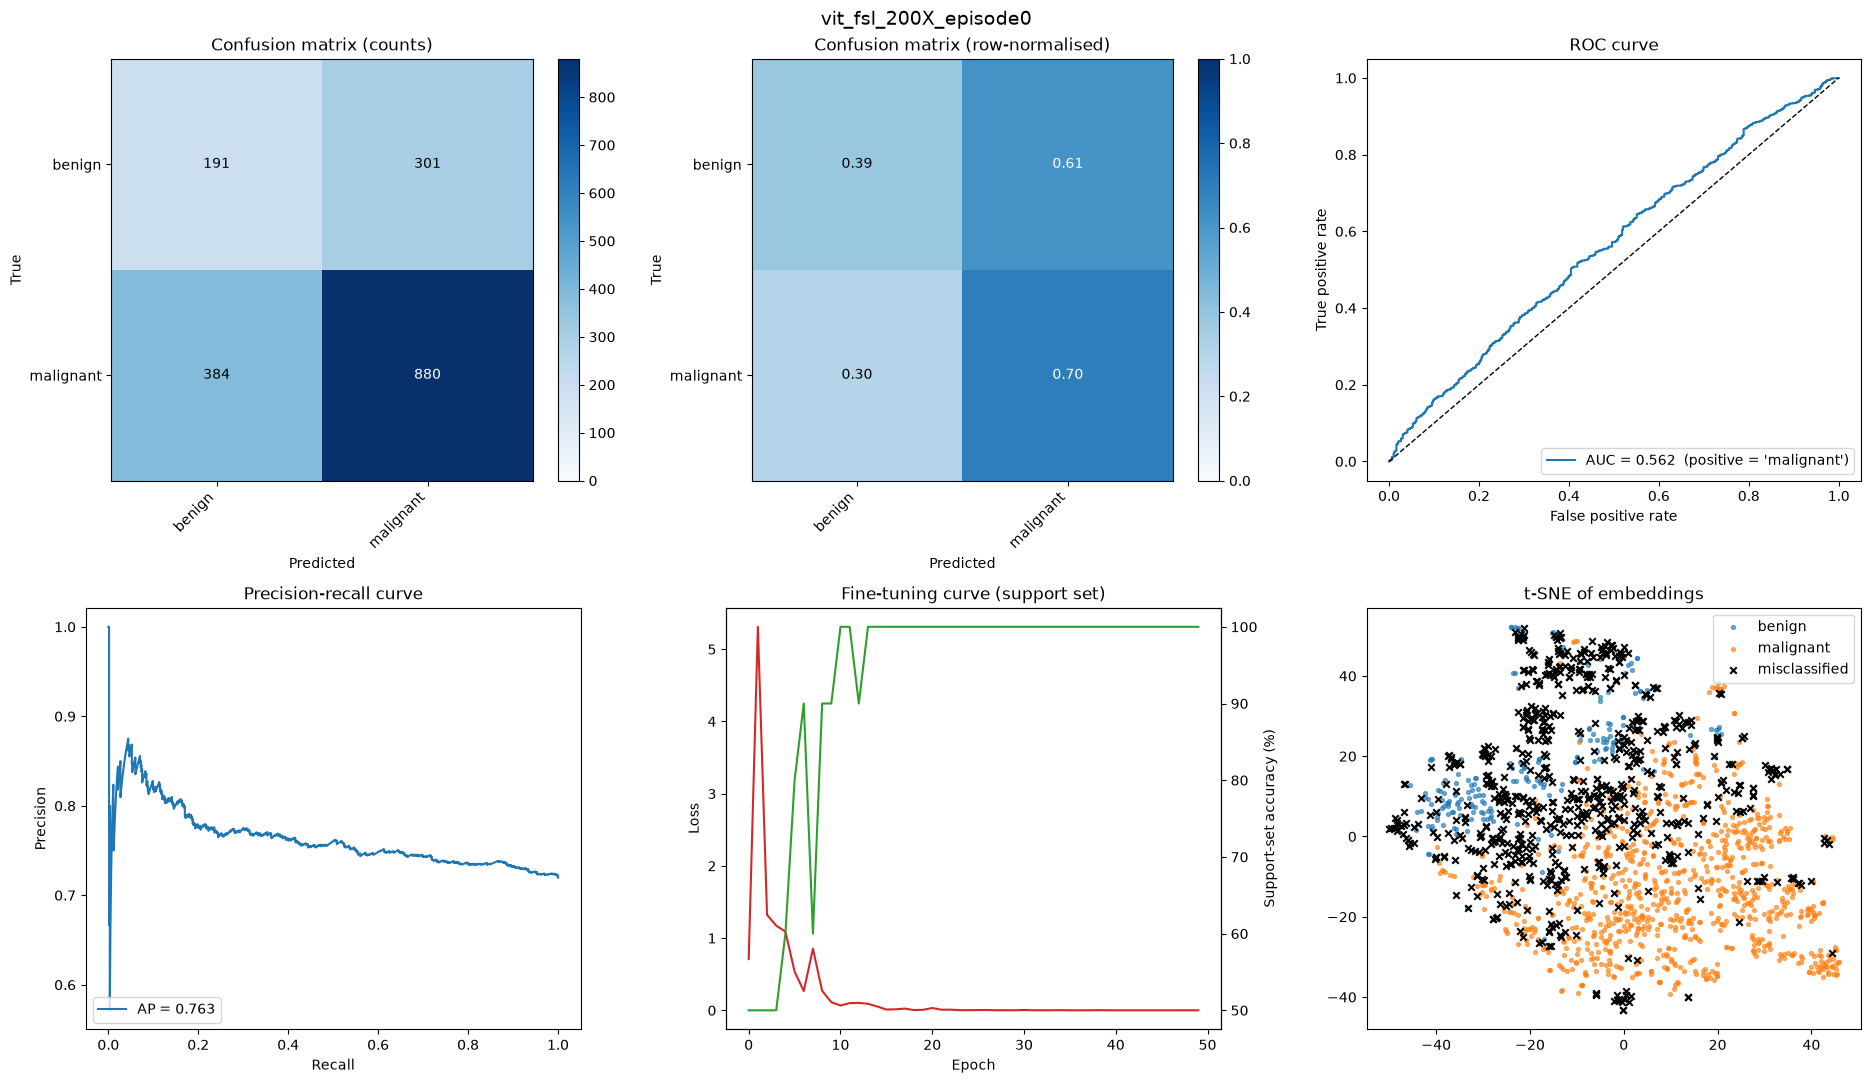


=== [200X] Episode 2/5 (seed=43) ===
support: 10 images | query: 1132 images (patient-disjoint from support)
  epoch 10/50 - loss 0.0295 - support-set acc 100.0%
  epoch 20/50 - loss 0.0003 - support-set acc 100.0%
  epoch 30/50 - loss 0.0000 - support-set acc 100.0%
  epoch 40/50 - loss 0.0000 - support-set acc 100.0%
  epoch 50/50 - loss 0.0000 - support-set acc 100.0%



----- vit_fsl_200X_episode1 -----
              precision    recall  f1-score   support

      benign      0.484     0.663     0.560       469
   malignant      0.852     0.732     0.787      1237

    accuracy                          0.713      1706
   macro avg      0.668     0.698     0.674      1706
weighted avg      0.751     0.713     0.725      1706

                  accuracy: 0.7134
         balanced_accuracy: 0.6978
           precision_macro: 0.6680
              recall_macro: 0.6978
                  f1_macro: 0.6737
               f1_weighted: 0.7249
                       mcc: 0.3645
               cohen_kappa: 0.3549
                   roc_auc: 0.7547
               sensitivity: 0.7324
               specificity: 0.6631
             avg_precision: 0.8685
             accuracy_ci95: [0.6922, 0.7356]
              roc_auc_ci95: [0.7273, 0.7797]
   majority_class_baseline: 0.7251
        test_only_accuracy: 0.7195
  test_only_balanced_accuracy: 0.6773
        test_only_f1

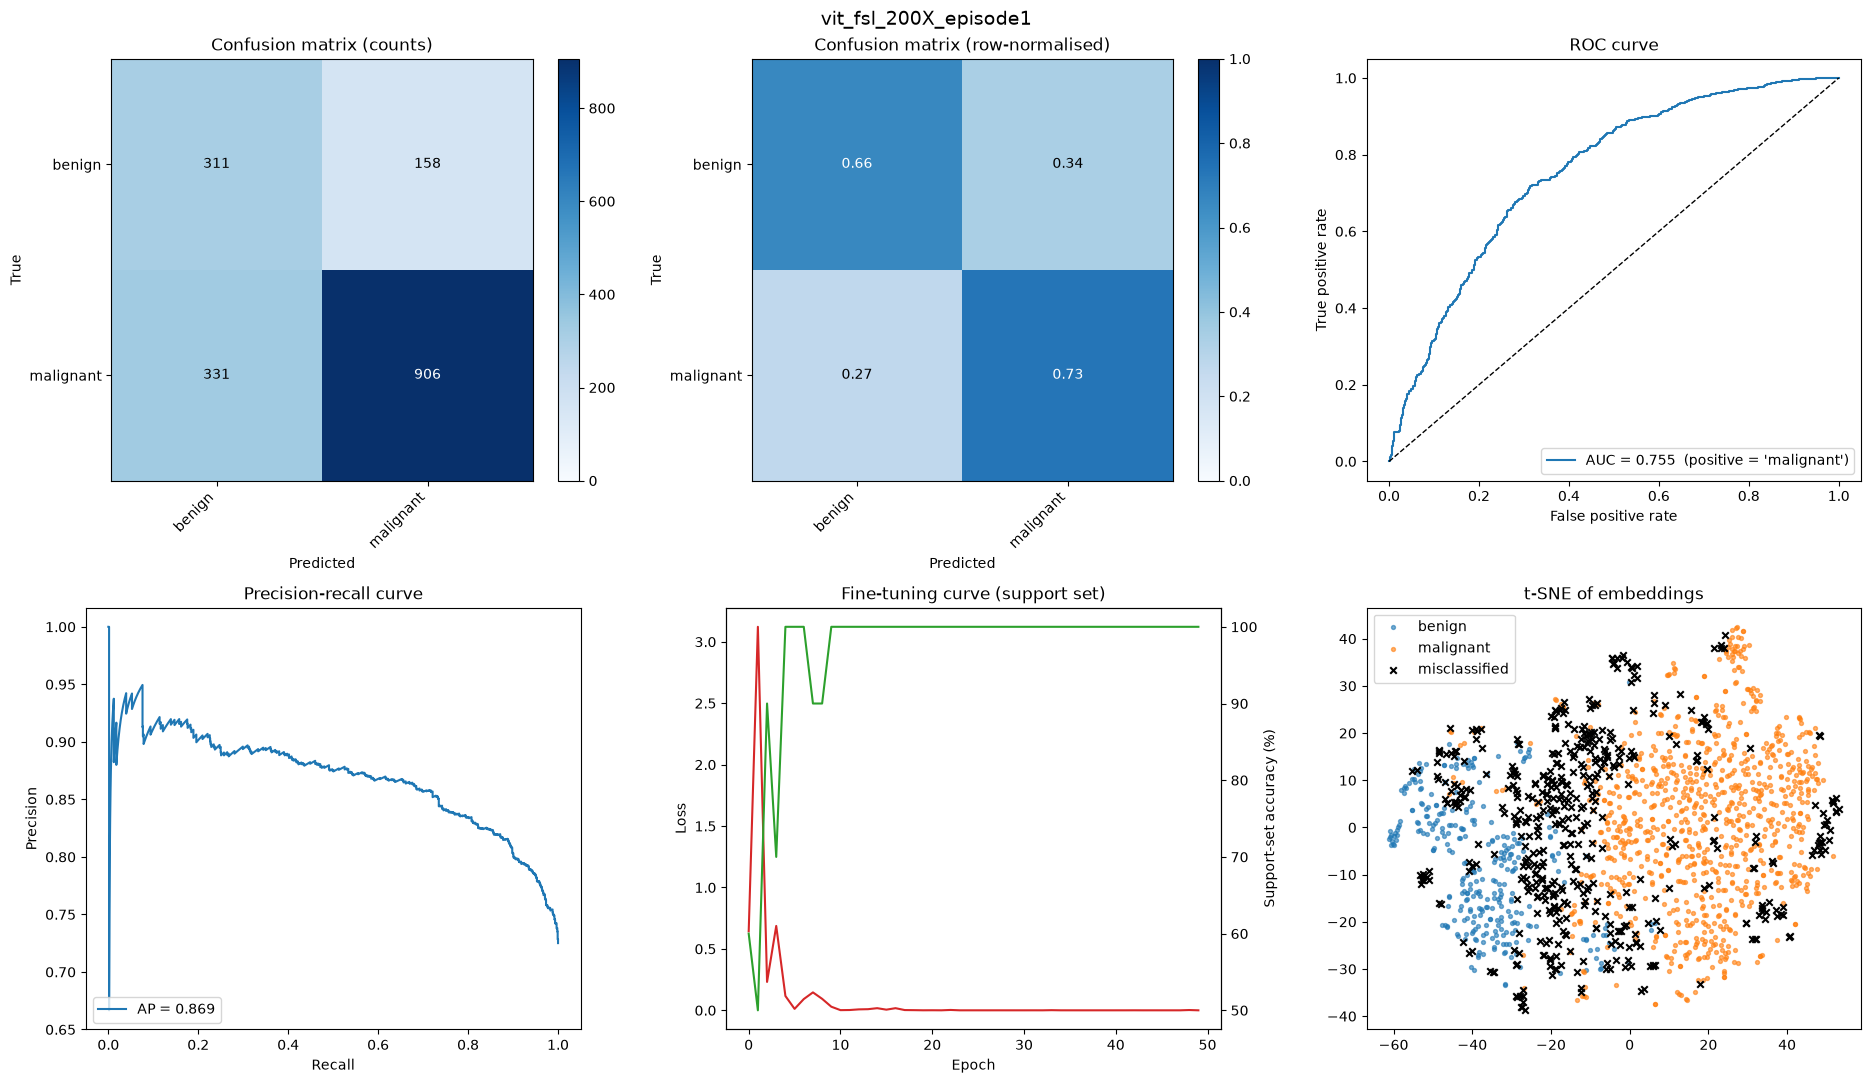


=== [200X] Episode 3/5 (seed=44) ===
support: 10 images | query: 1200 images (patient-disjoint from support)
  epoch 10/50 - loss 0.3555 - support-set acc 80.0%
  epoch 20/50 - loss 0.0146 - support-set acc 100.0%
  epoch 30/50 - loss 0.0005 - support-set acc 100.0%
  epoch 40/50 - loss 0.0054 - support-set acc 100.0%
  epoch 50/50 - loss 0.0001 - support-set acc 100.0%



----- vit_fsl_200X_episode2 -----
              precision    recall  f1-score   support

      benign      0.418     0.749     0.537       494
   malignant      0.861     0.598     0.705      1280

    accuracy                          0.640      1774
   macro avg      0.639     0.673     0.621      1774
weighted avg      0.737     0.640     0.658      1774

                  accuracy: 0.6398
         balanced_accuracy: 0.6733
           precision_macro: 0.6393
              recall_macro: 0.6733
                  f1_macro: 0.6210
               f1_weighted: 0.6584
                       mcc: 0.3108
               cohen_kappa: 0.2789
                   roc_auc: 0.7351
               sensitivity: 0.5977
               specificity: 0.7490
             avg_precision: 0.8828
             accuracy_ci95: [0.6189, 0.6624]
              roc_auc_ci95: [0.7119, 0.7594]
   majority_class_baseline: 0.7215
        test_only_accuracy: 0.6934
  test_only_balanced_accuracy: 0.7246
        test_only_f1

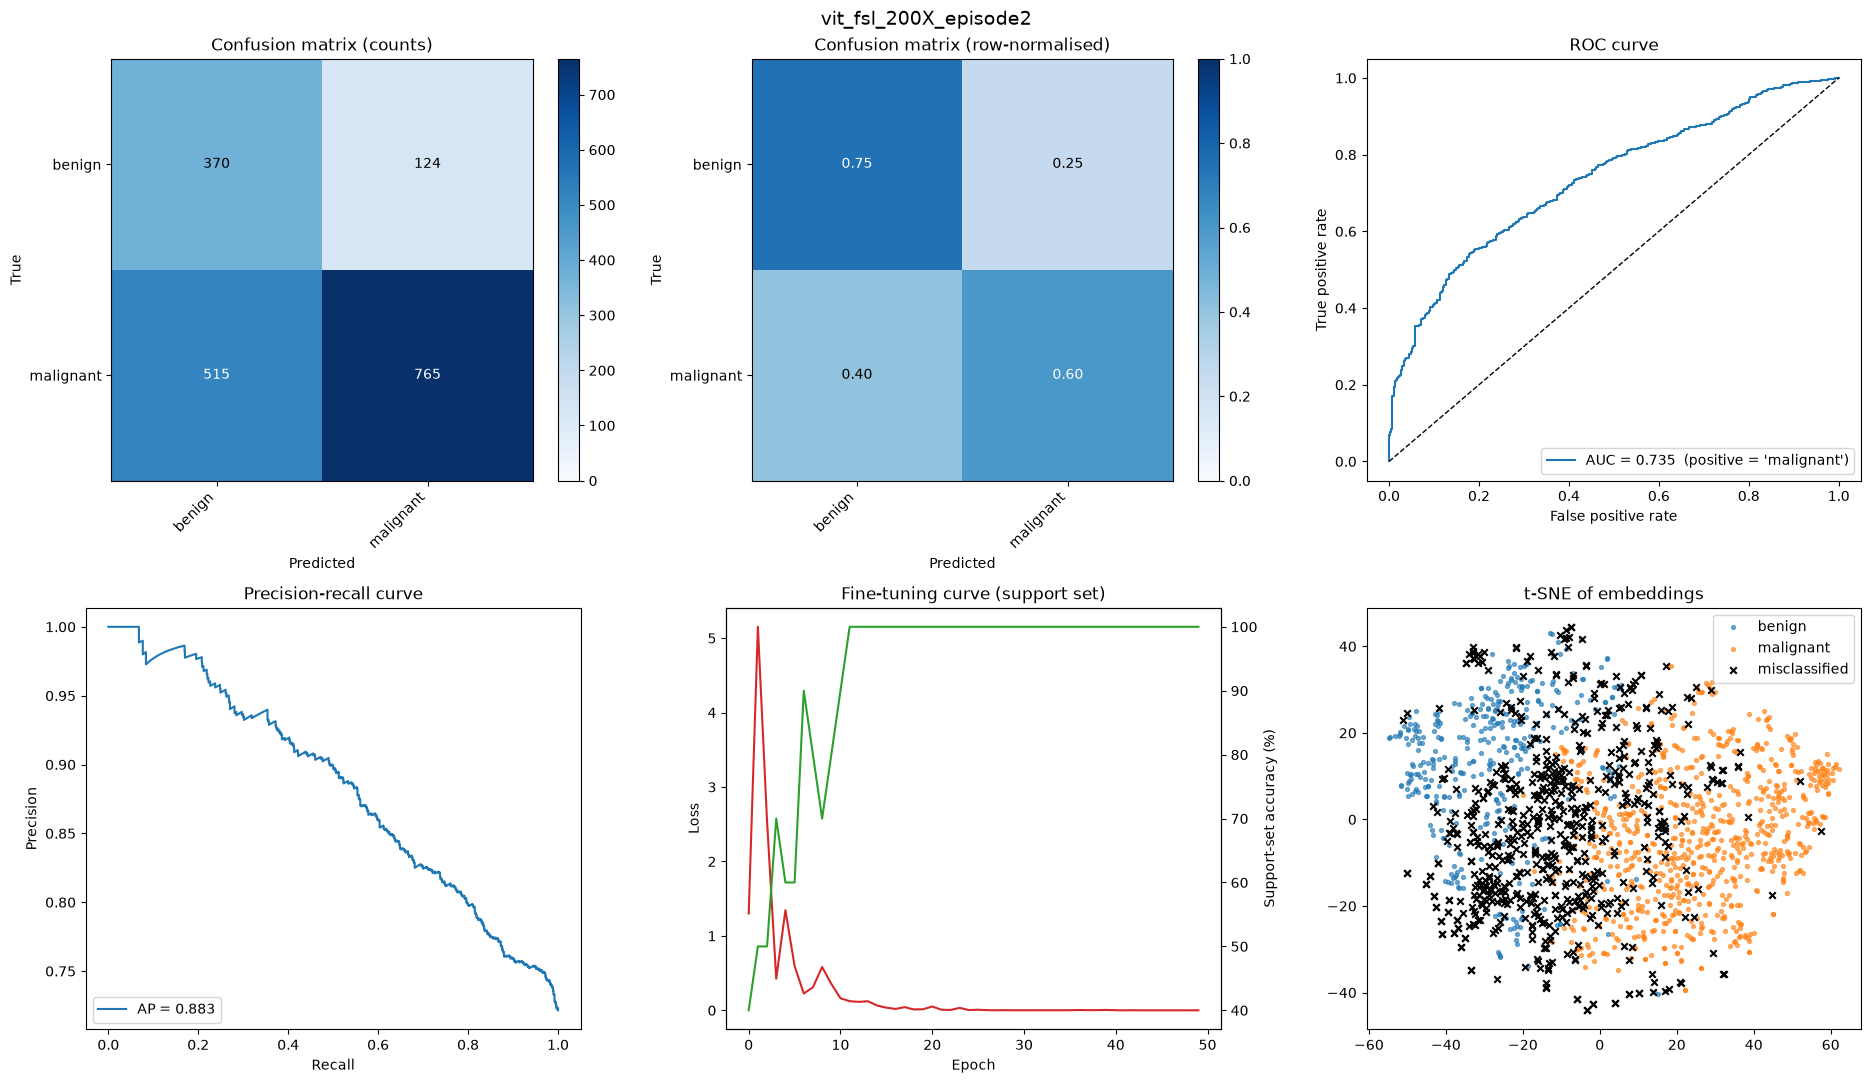


=== [200X] Episode 4/5 (seed=45) ===
support: 10 images | query: 1130 images (patient-disjoint from support)
  epoch 10/50 - loss 0.4631 - support-set acc 80.0%
  epoch 20/50 - loss 0.1533 - support-set acc 90.0%
  epoch 30/50 - loss 0.0127 - support-set acc 100.0%
  epoch 40/50 - loss 0.0000 - support-set acc 100.0%
  epoch 50/50 - loss 0.0021 - support-set acc 100.0%



----- vit_fsl_200X_episode3 -----
              precision    recall  f1-score   support

      benign      0.524     0.700     0.600       464
   malignant      0.872     0.762     0.813      1240

    accuracy                          0.745      1704
   macro avg      0.698     0.731     0.706      1704
weighted avg      0.777     0.745     0.755      1704

                  accuracy: 0.7453
         balanced_accuracy: 0.7313
           precision_macro: 0.6980
              recall_macro: 0.7313
                  f1_macro: 0.7064
               f1_weighted: 0.7551
                       mcc: 0.4280
               cohen_kappa: 0.4185
                   roc_auc: 0.8033
               sensitivity: 0.7621
               specificity: 0.7004
             avg_precision: 0.8938
             accuracy_ci95: [0.7253, 0.7658]
              roc_auc_ci95: [0.7787, 0.8265]
   majority_class_baseline: 0.7277
        test_only_accuracy: 0.7544
  test_only_balanced_accuracy: 0.7315
        test_only_f1

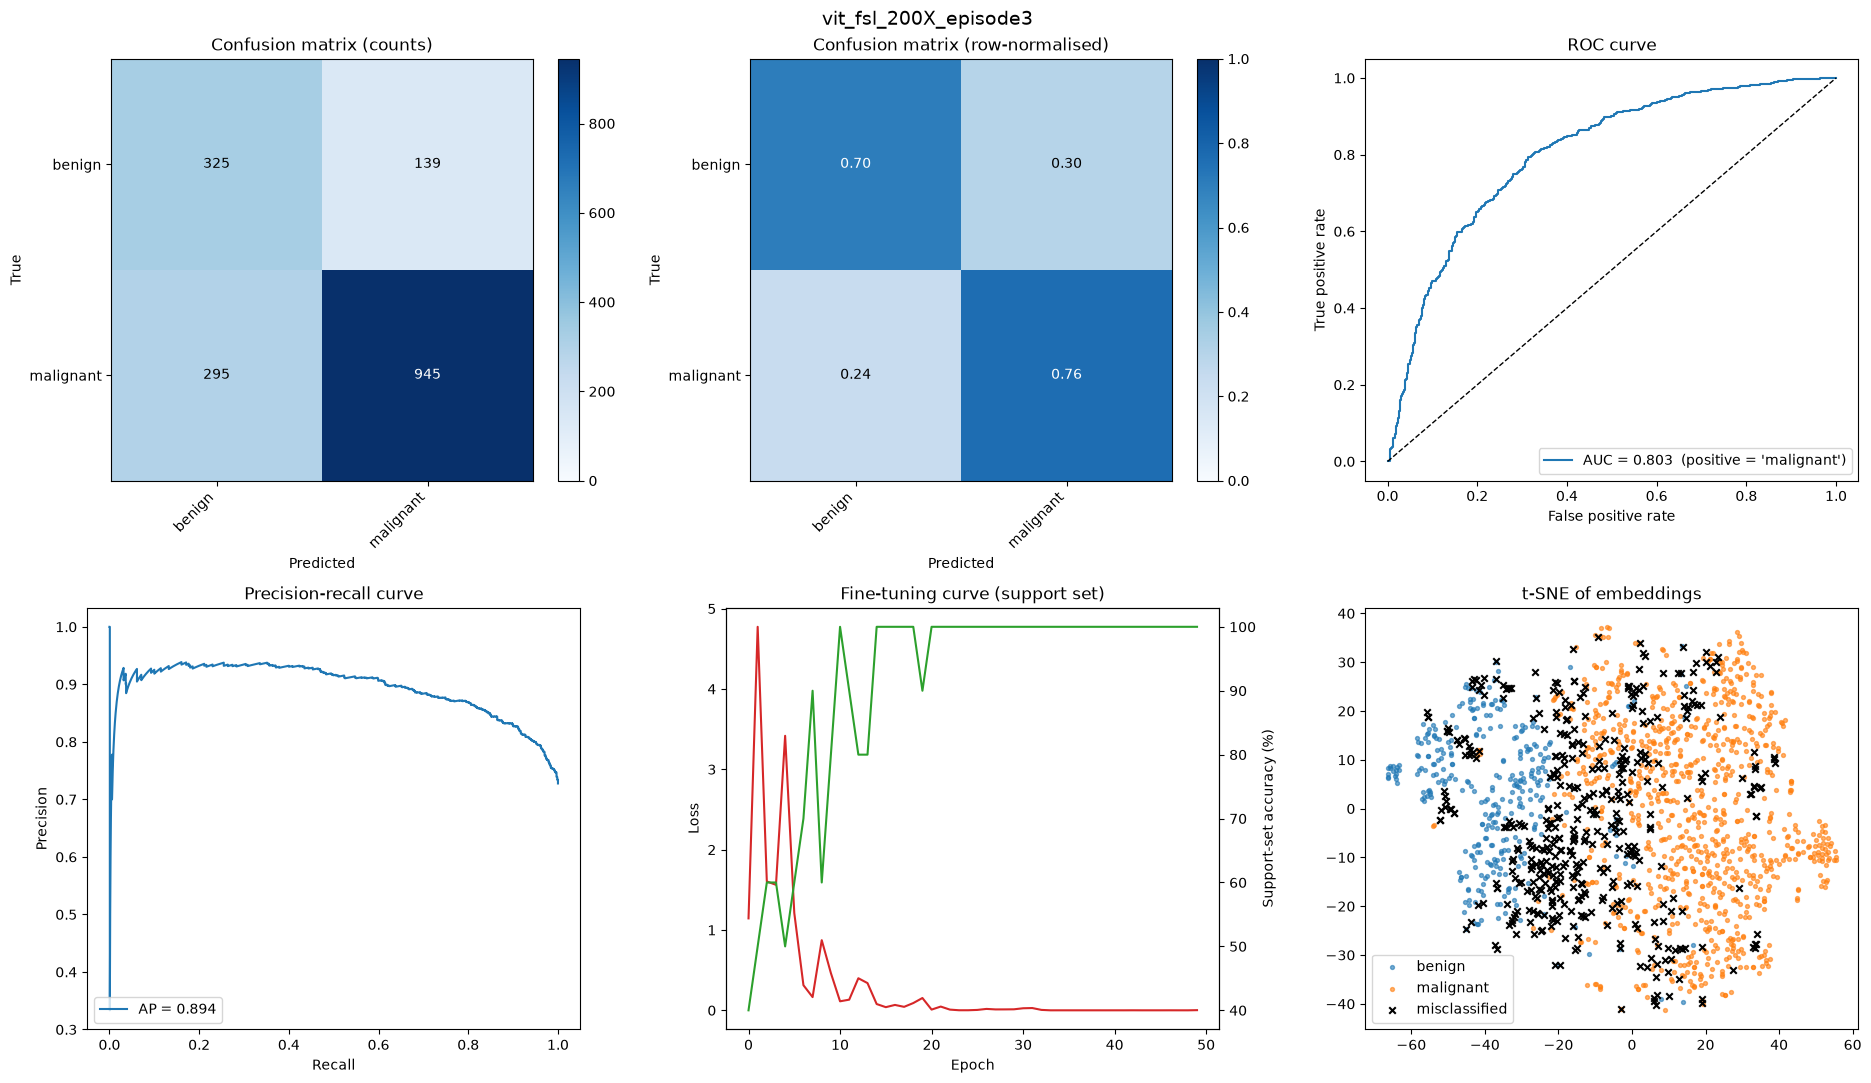


=== [200X] Episode 5/5 (seed=46) ===
support: 10 images | query: 1170 images (patient-disjoint from support)
  epoch 10/50 - loss 0.4079 - support-set acc 70.0%
  epoch 20/50 - loss 0.0072 - support-set acc 100.0%
  epoch 30/50 - loss 0.0019 - support-set acc 100.0%
  epoch 40/50 - loss 0.0059 - support-set acc 100.0%
  epoch 50/50 - loss 0.0000 - support-set acc 100.0%



----- vit_fsl_200X_episode4 -----
              precision    recall  f1-score   support

      benign      0.513     0.790     0.622       472
   malignant      0.903     0.722     0.802      1272

    accuracy                          0.740      1744
   macro avg      0.708     0.756     0.712      1744
weighted avg      0.797     0.740     0.753      1744

                  accuracy: 0.7403
         balanced_accuracy: 0.7560
           precision_macro: 0.7079
              recall_macro: 0.7560
                  f1_macro: 0.7121
               f1_weighted: 0.7534
                       mcc: 0.4613
               cohen_kappa: 0.4376
                   roc_auc: 0.8486
               sensitivity: 0.7217
               specificity: 0.7903
             avg_precision: 0.9380
             accuracy_ci95: [0.7202, 0.7603]
              roc_auc_ci95: [0.8309, 0.8664]
   majority_class_baseline: 0.7294
        test_only_accuracy: 0.7596
  test_only_balanced_accuracy: 0.7726
        test_only_f1

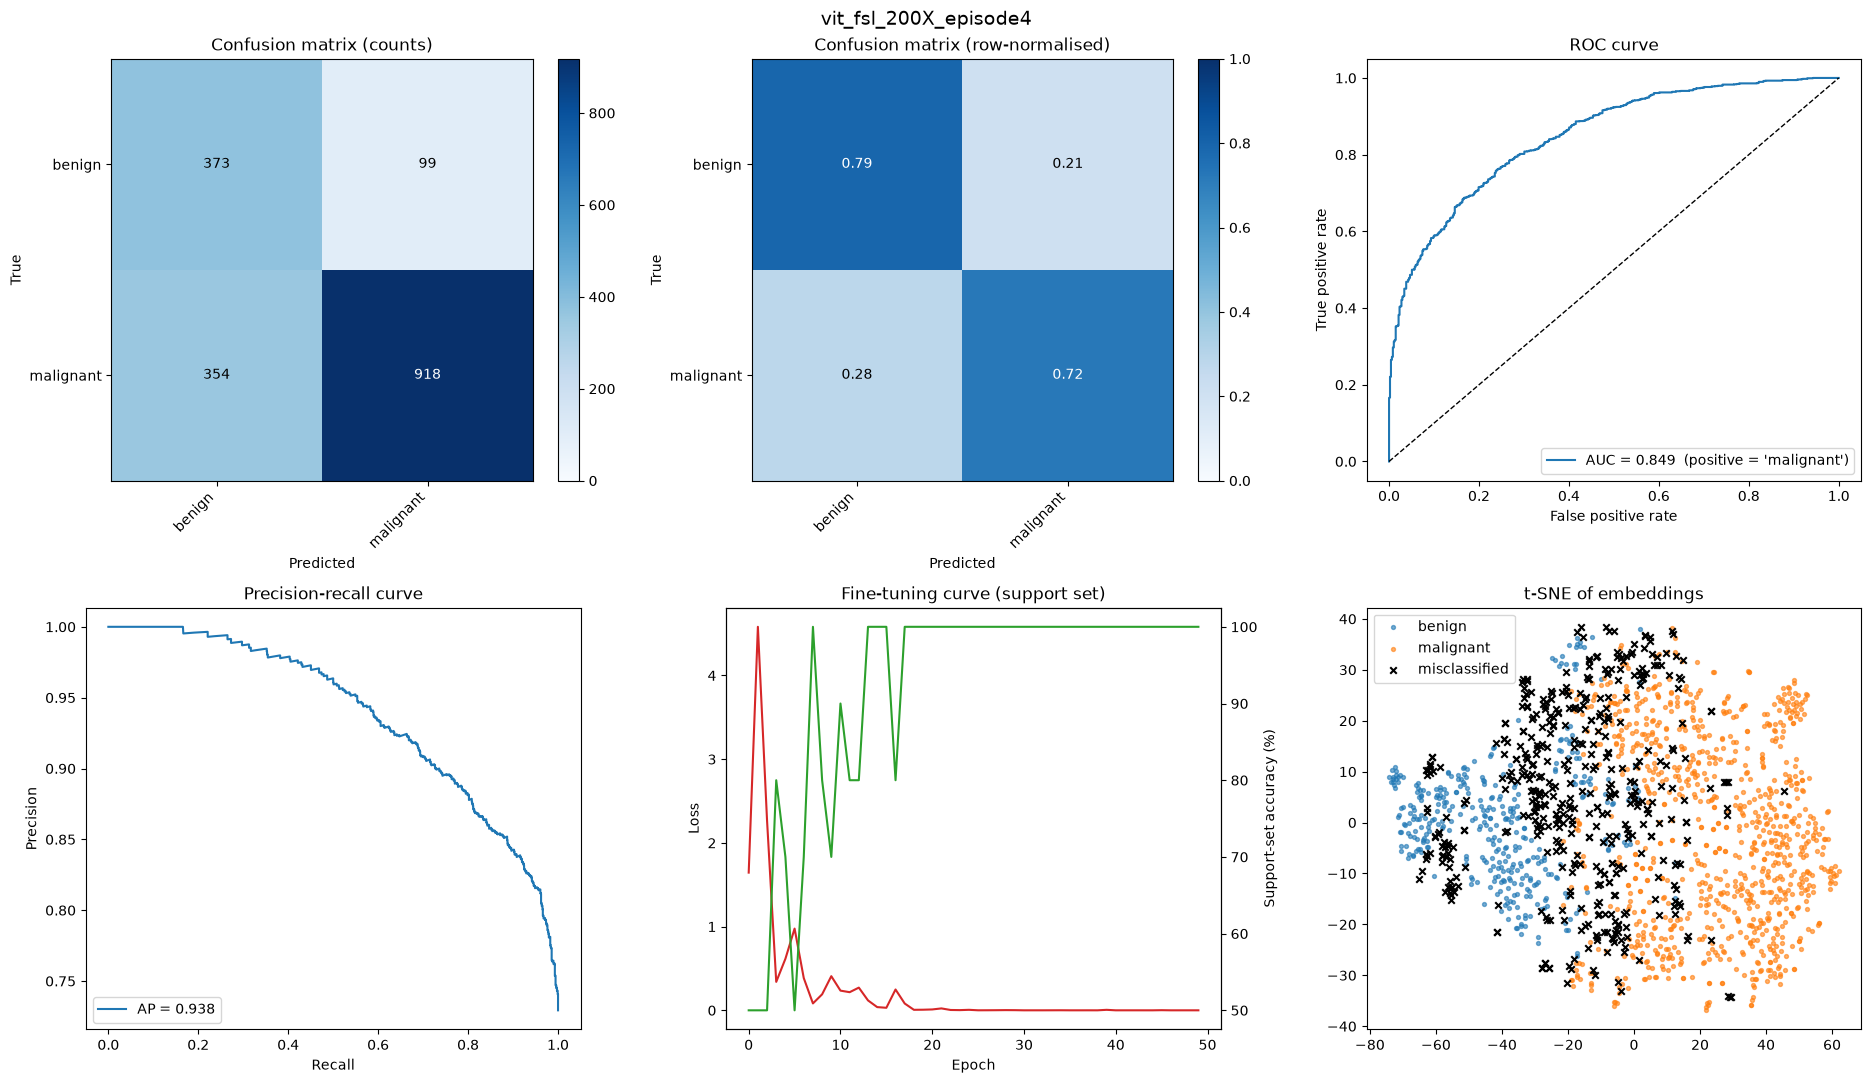


===== vit_fsl_200X: summary over 5 episode(s) =====
                                     mean     std
accuracy                           0.6897  0.0549
balanced_accuracy                  0.6801  0.0745
precision_macro                    0.6504  0.0608
recall_macro                       0.6801  0.0745
f1_macro                           0.6504  0.0645
f1_weighted                        0.7021  0.0545
mcc                                0.3291  0.1345
cohen_kappa                        0.3140  0.1294
roc_auc                            0.7407  0.0977
sensitivity                        0.7020  0.0563
specificity                        0.6582  0.1417
avg_precision                      0.8692  0.0580
majority_class_baseline            0.7247  0.0036
test_only_accuracy                 0.7111  0.0477
test_only_balanced_accuracy        0.6950  0.0698
test_only_f1_macro                 0.6713  0.0590
test_only_roc_auc                  0.7499  0.1001
test_only_majority_class_baseline  0.7178  0.00


----- vit_fsl_400X_episode0 -----
              precision    recall  f1-score   support

      benign      0.414     0.810     0.548       468
   malignant      0.872     0.530     0.659      1140

    accuracy                          0.611      1608
   macro avg      0.643     0.670     0.604      1608
weighted avg      0.738     0.611     0.627      1608

                  accuracy: 0.6113
         balanced_accuracy: 0.6698
           precision_macro: 0.6429
              recall_macro: 0.6698
                  f1_macro: 0.6036
               f1_weighted: 0.6267
                       mcc: 0.3116
               cohen_kappa: 0.2650
                   roc_auc: 0.7515
               sensitivity: 0.5298
               specificity: 0.8098
             avg_precision: 0.8796
             accuracy_ci95: [0.5877, 0.6337]
              roc_auc_ci95: [0.7243, 0.7773]
   majority_class_baseline: 0.7090
        test_only_accuracy: 0.6554
  test_only_balanced_accuracy: 0.7299
        test_only_f1

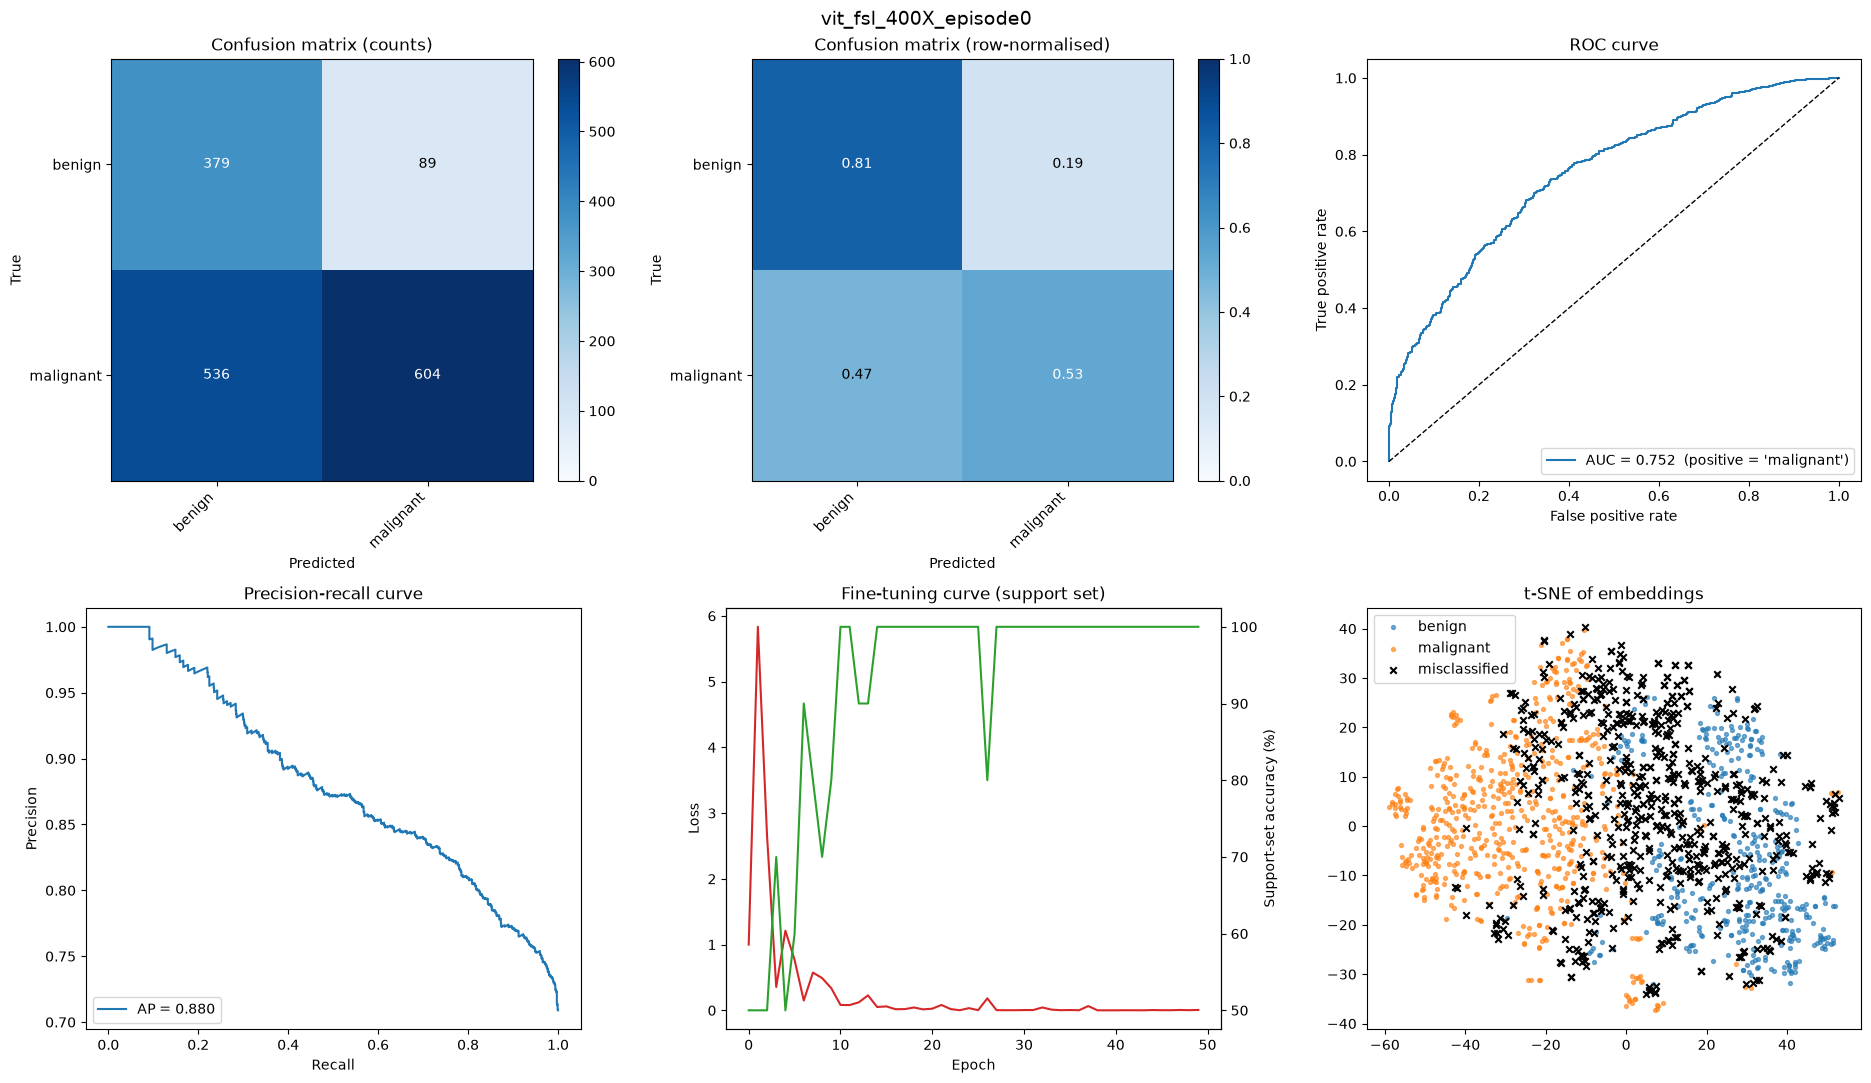


=== [400X] Episode 2/5 (seed=43) ===
support: 10 images | query: 1043 images (patient-disjoint from support)
  epoch 10/50 - loss 0.0877 - support-set acc 100.0%
  epoch 20/50 - loss 0.1991 - support-set acc 90.0%
  epoch 30/50 - loss 0.0050 - support-set acc 100.0%
  epoch 40/50 - loss 0.0025 - support-set acc 100.0%
  epoch 50/50 - loss 0.0002 - support-set acc 100.0%



----- vit_fsl_400X_episode1 -----
              precision    recall  f1-score   support

      benign      0.381     0.749     0.505       419
   malignant      0.855     0.547     0.667      1129

    accuracy                          0.602      1548
   macro avg      0.618     0.648     0.586      1548
weighted avg      0.726     0.602     0.623      1548

                  accuracy: 0.6021
         balanced_accuracy: 0.6484
           precision_macro: 0.6177
              recall_macro: 0.6484
                  f1_macro: 0.5861
               f1_weighted: 0.6234
                       mcc: 0.2643
               cohen_kappa: 0.2275
                   roc_auc: 0.7086
               sensitivity: 0.5474
               specificity: 0.7494
             avg_precision: 0.8664
             accuracy_ci95: [0.5795, 0.6260]
              roc_auc_ci95: [0.6812, 0.7371]
   majority_class_baseline: 0.7293
        test_only_accuracy: 0.6277
  test_only_balanced_accuracy: 0.6595
        test_only_f1

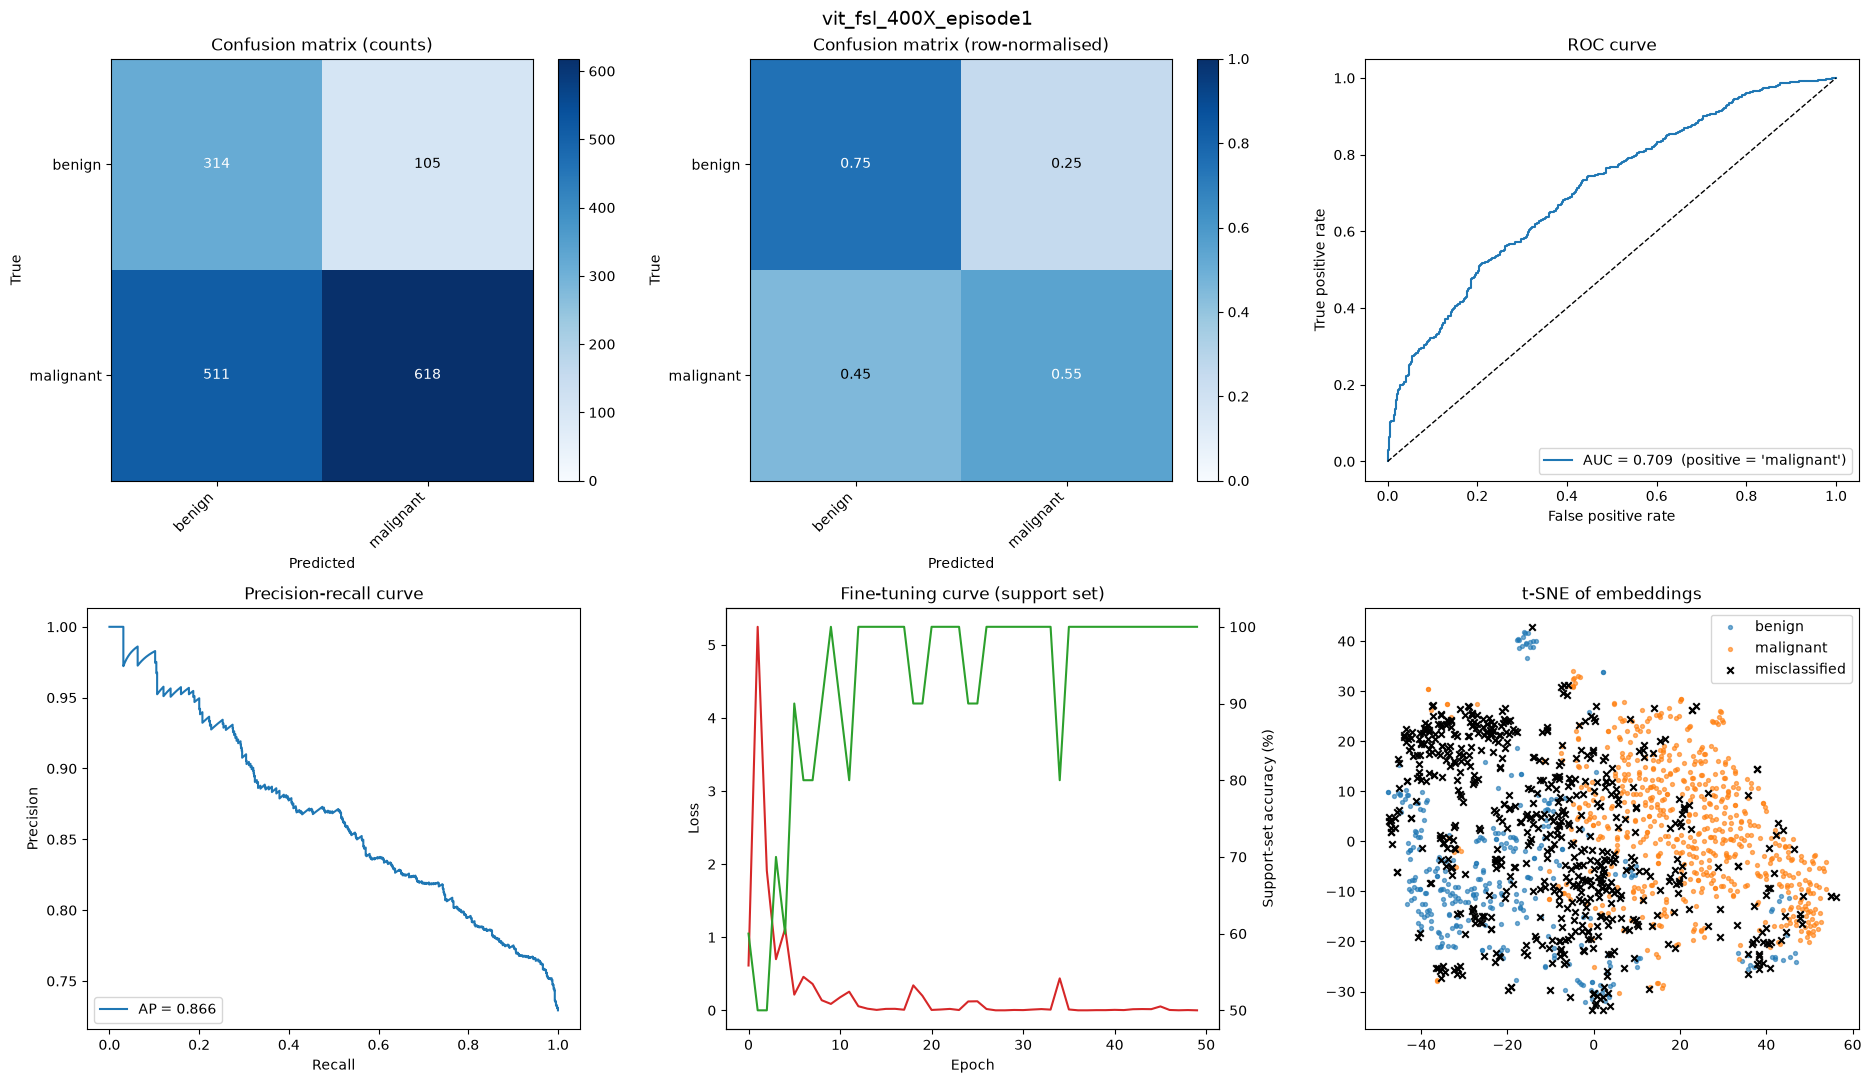


=== [400X] Episode 3/5 (seed=44) ===
support: 10 images | query: 1082 images (patient-disjoint from support)
  epoch 10/50 - loss 0.1394 - support-set acc 90.0%
  epoch 20/50 - loss 0.0164 - support-set acc 100.0%
  epoch 30/50 - loss 0.0002 - support-set acc 100.0%
  epoch 40/50 - loss 0.0001 - support-set acc 100.0%
  epoch 50/50 - loss 0.0000 - support-set acc 100.0%



----- vit_fsl_400X_episode2 -----
              precision    recall  f1-score   support

      benign      0.389     0.831     0.530       449
   malignant      0.879     0.485     0.625      1138

    accuracy                          0.583      1587
   macro avg      0.634     0.658     0.577      1587
weighted avg      0.740     0.583     0.598      1587

                  accuracy: 0.5829
         balanced_accuracy: 0.6579
           precision_macro: 0.6340
              recall_macro: 0.6579
                  f1_macro: 0.5775
               f1_weighted: 0.5982
                       mcc: 0.2909
               cohen_kappa: 0.2350
                   roc_auc: 0.7677
               sensitivity: 0.4851
               specificity: 0.8307
             avg_precision: 0.8789
             accuracy_ci95: [0.5595, 0.6062]
              roc_auc_ci95: [0.7435, 0.7943]
   majority_class_baseline: 0.7171
        test_only_accuracy: 0.6574
  test_only_balanced_accuracy: 0.7007
        test_only_f1

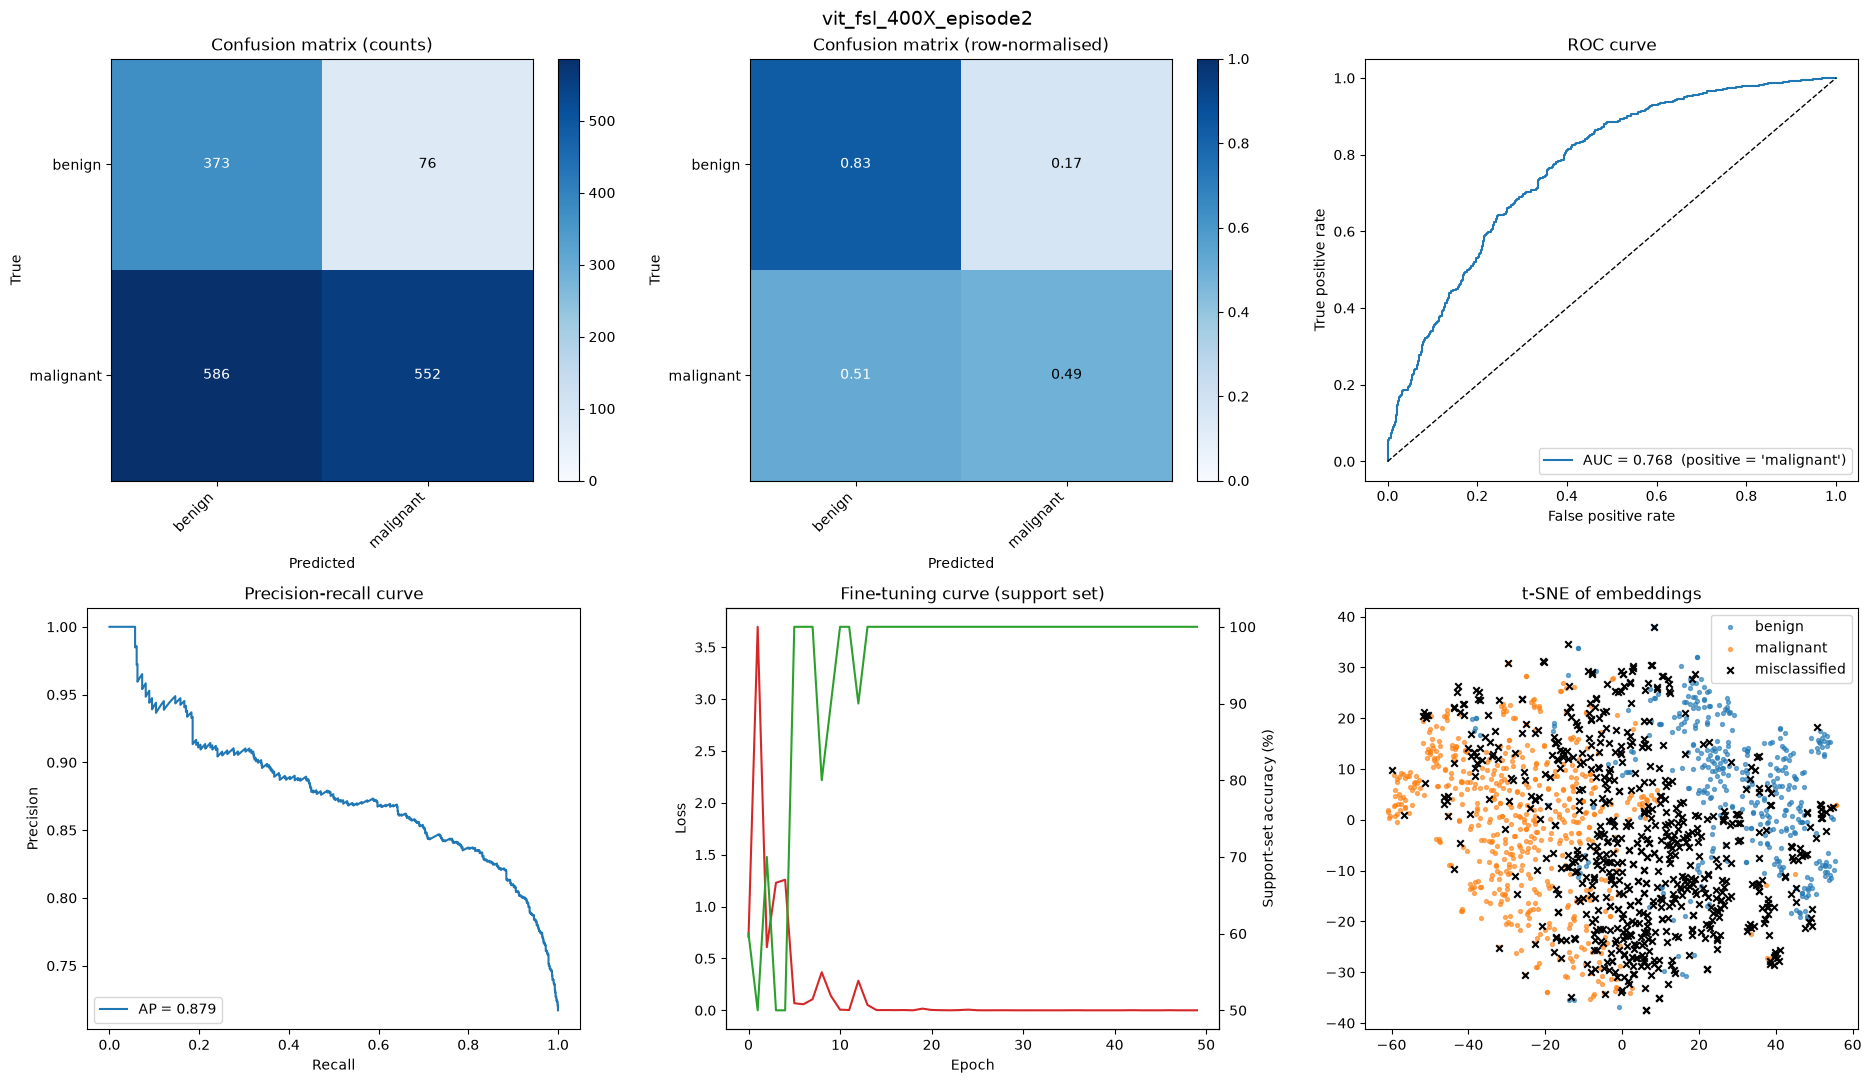


=== [400X] Episode 4/5 (seed=45) ===
support: 10 images | query: 1067 images (patient-disjoint from support)
  epoch 10/50 - loss 0.0128 - support-set acc 100.0%
  epoch 20/50 - loss 0.0010 - support-set acc 100.0%
  epoch 30/50 - loss 0.0006 - support-set acc 100.0%
  epoch 40/50 - loss 0.0049 - support-set acc 100.0%
  epoch 50/50 - loss 0.0001 - support-set acc 100.0%



----- vit_fsl_400X_episode3 -----
              precision    recall  f1-score   support

      benign      0.570     0.697     0.627       442
   malignant      0.870     0.795     0.831      1130

    accuracy                          0.767      1572
   macro avg      0.720     0.746     0.729      1572
weighted avg      0.786     0.767     0.774      1572

                  accuracy: 0.7672
         balanced_accuracy: 0.7458
           precision_macro: 0.7203
              recall_macro: 0.7458
                  f1_macro: 0.7290
               f1_weighted: 0.7735
                       mcc: 0.4653
               cohen_kappa: 0.4604
                   roc_auc: 0.8148
               sensitivity: 0.7947
               specificity: 0.6968
             avg_precision: 0.9088
             accuracy_ci95: [0.7475, 0.7869]
              roc_auc_ci95: [0.7921, 0.8374]
   majority_class_baseline: 0.7188
        test_only_accuracy: 0.7545
  test_only_balanced_accuracy: 0.7240
        test_only_f1

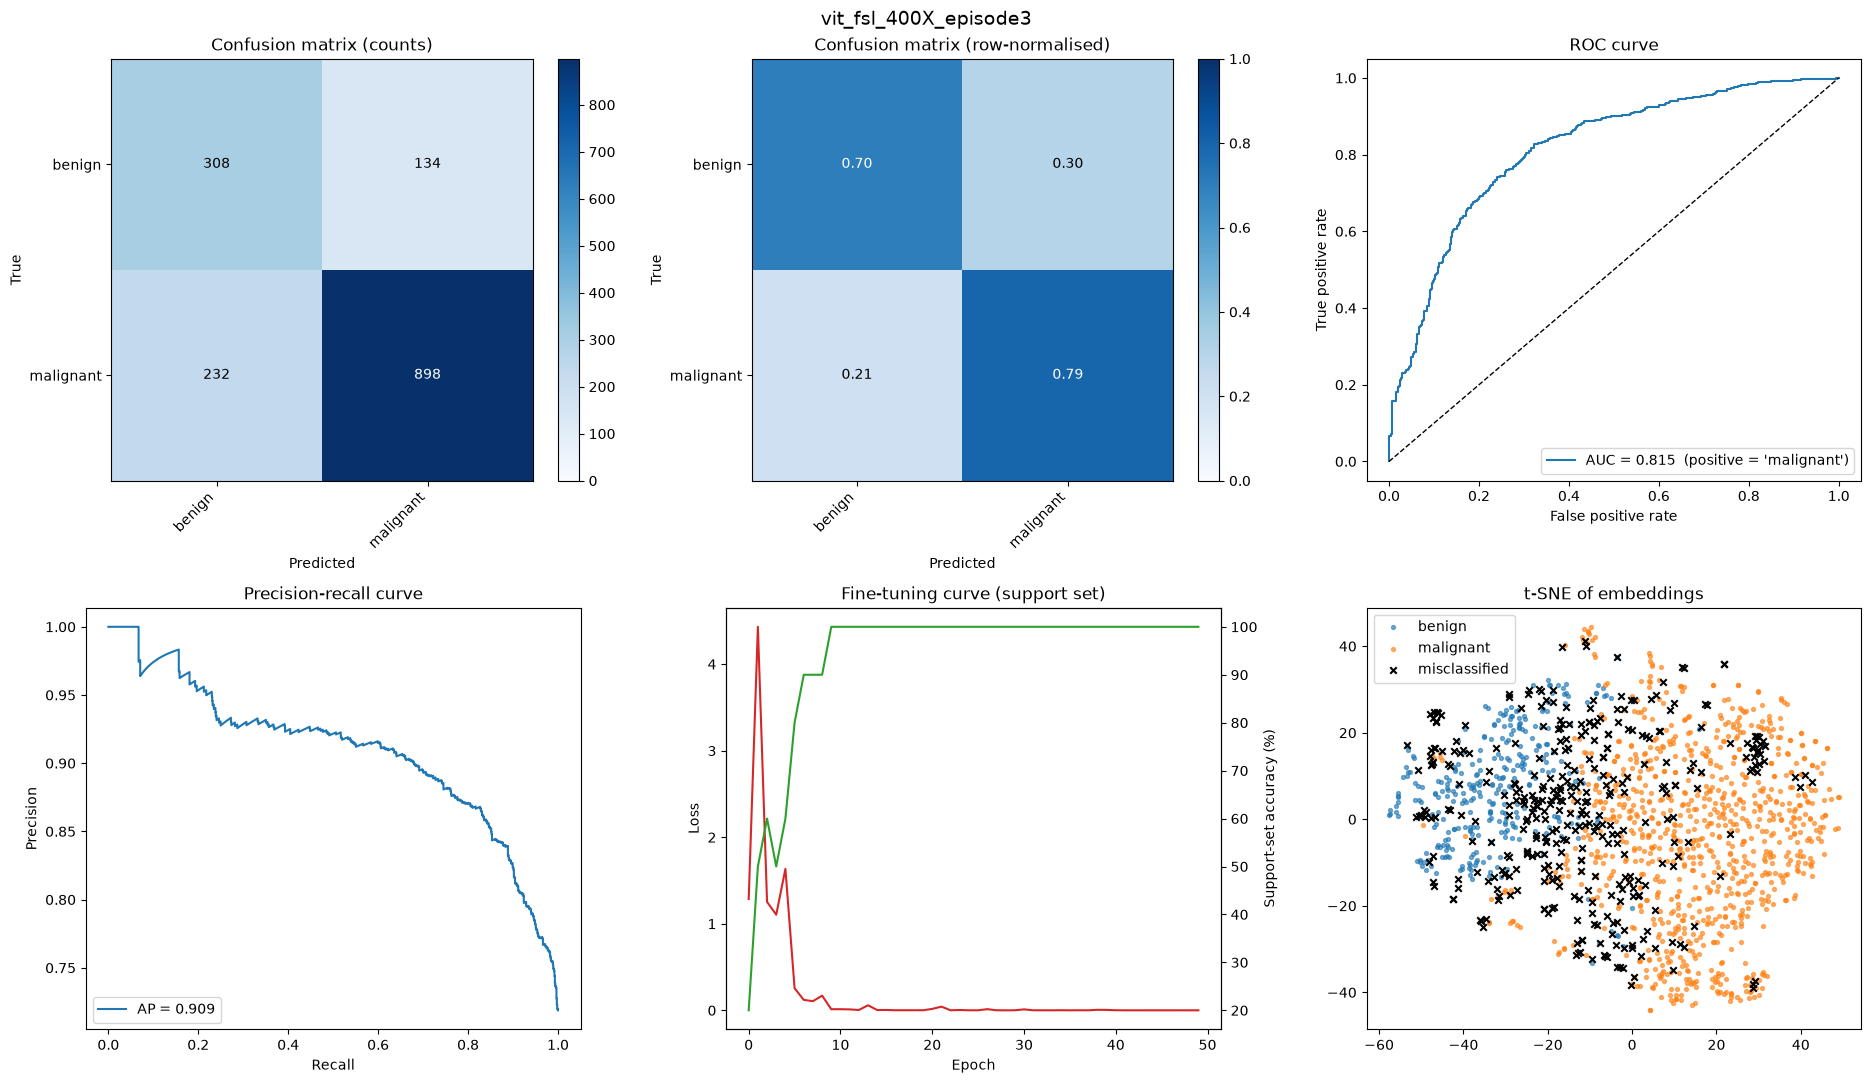


=== [400X] Episode 5/5 (seed=46) ===
support: 10 images | query: 1035 images (patient-disjoint from support)
  epoch 10/50 - loss 0.2345 - support-set acc 80.0%
  epoch 20/50 - loss 0.0088 - support-set acc 100.0%
  epoch 30/50 - loss 0.0001 - support-set acc 100.0%
  epoch 40/50 - loss 0.0008 - support-set acc 100.0%
  epoch 50/50 - loss 0.0000 - support-set acc 100.0%



----- vit_fsl_400X_episode4 -----
              precision    recall  f1-score   support

      benign      0.484     0.602     0.537       427
   malignant      0.832     0.754     0.791      1113

    accuracy                          0.712      1540
   macro avg      0.658     0.678     0.664      1540
weighted avg      0.735     0.712     0.720      1540

                  accuracy: 0.7117
         balanced_accuracy: 0.6778
           precision_macro: 0.6578
              recall_macro: 0.6778
                  f1_macro: 0.6636
               f1_weighted: 0.7203
                       mcc: 0.3350
               cohen_kappa: 0.3309
                   roc_auc: 0.7318
               sensitivity: 0.7538
               specificity: 0.6019
             avg_precision: 0.8519
             accuracy_ci95: [0.6896, 0.7344]
              roc_auc_ci95: [0.7015, 0.7615]
   majority_class_baseline: 0.7227
        test_only_accuracy: 0.7663
  test_only_balanced_accuracy: 0.7488
        test_only_f1

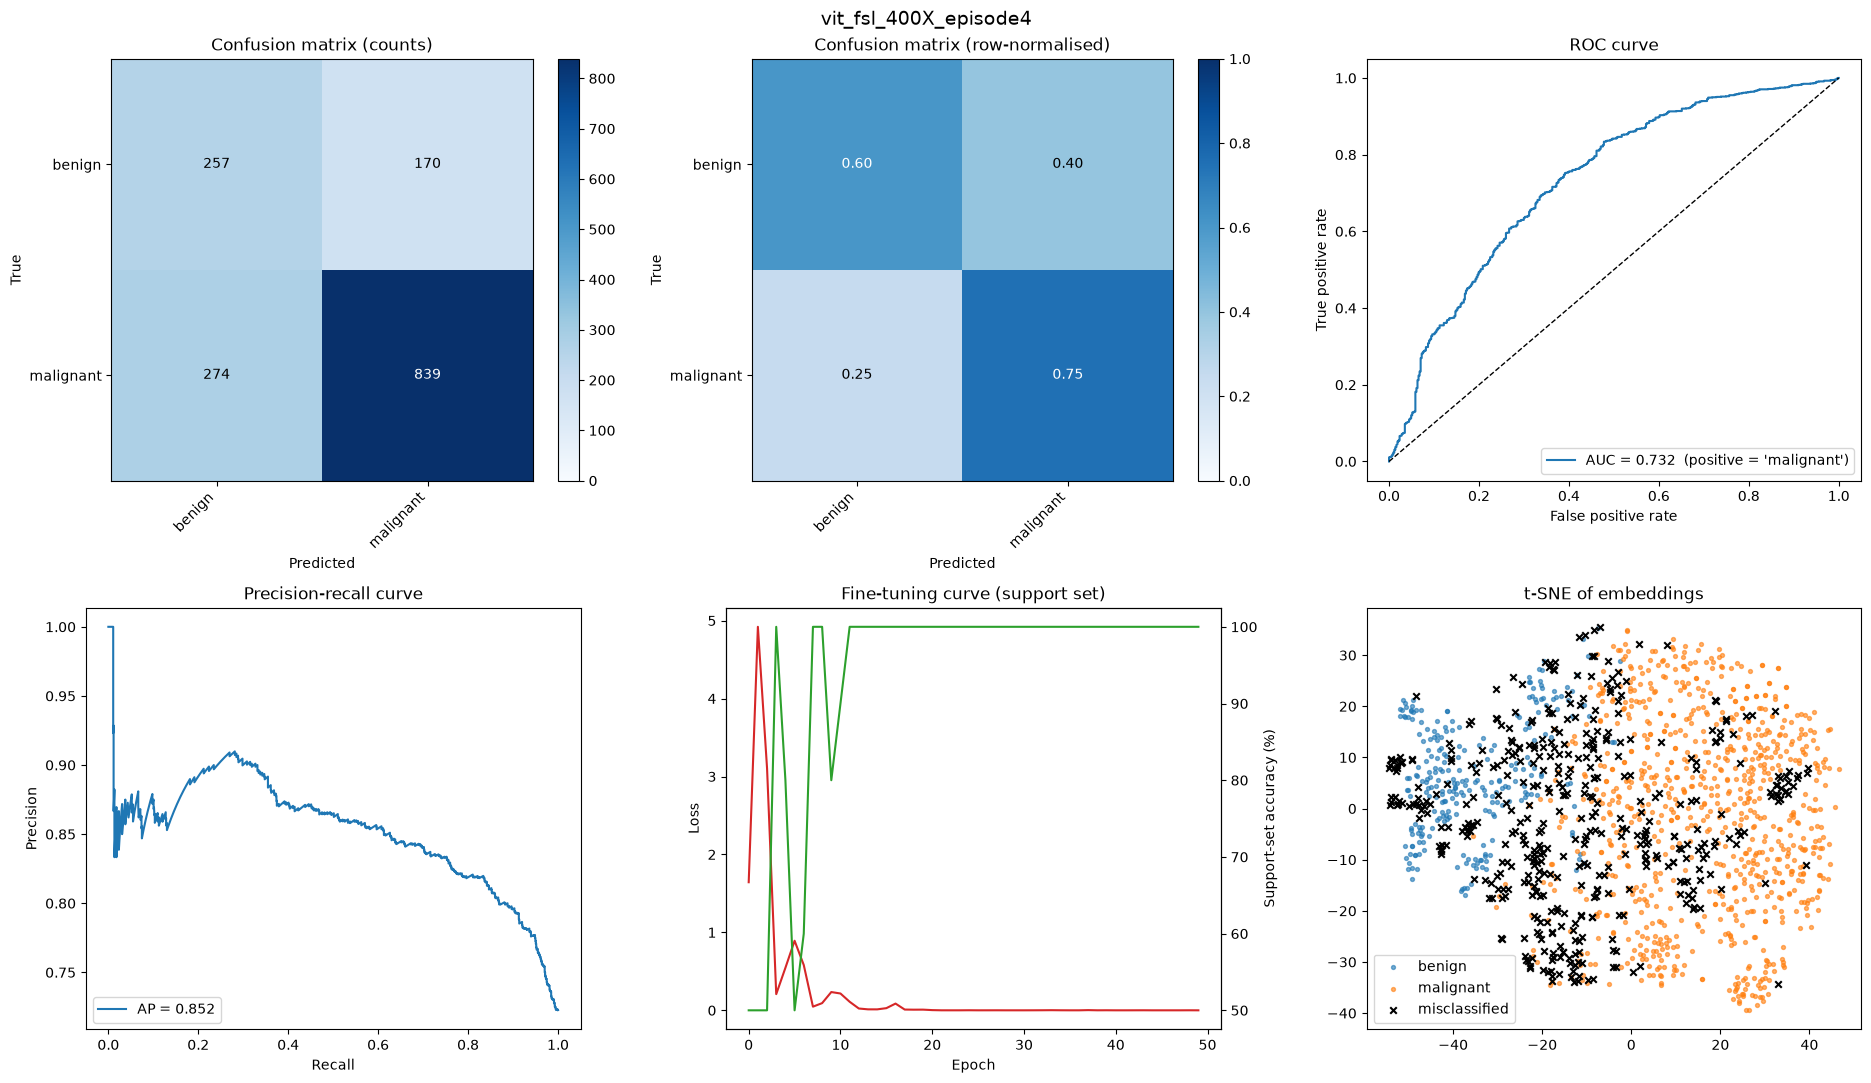


===== vit_fsl_400X: summary over 5 episode(s) =====
                                     mean     std
accuracy                           0.6550  0.0717
balanced_accuracy                  0.6799  0.0344
precision_macro                    0.6545  0.0353
recall_macro                       0.6799  0.0344
f1_macro                           0.6320  0.0571
f1_weighted                        0.6684  0.0670
mcc                                0.3334  0.0700
cohen_kappa                        0.3038  0.0864
roc_auc                            0.7549  0.0359
sensitivity                        0.6222  0.1265
specificity                        0.7377  0.0826
avg_precision                      0.8771  0.0188
majority_class_baseline            0.7194  0.0067
test_only_accuracy                 0.6923  0.0567
test_only_balanced_accuracy        0.7126  0.0306
test_only_f1_macro                 0.6746  0.0455
test_only_roc_auc                  0.7860  0.0397
test_only_majority_class_baseline  0.6931  0.00


----- vit_fsl_40X_100X_200X_400X_episode0 -----
              precision    recall  f1-score   support

      benign      0.552     0.458     0.500      1819
   malignant      0.815     0.865     0.839      5025

    accuracy                          0.757      6844
   macro avg      0.683     0.662     0.670      6844
weighted avg      0.745     0.757     0.749      6844

                  accuracy: 0.7570
         balanced_accuracy: 0.6616
           precision_macro: 0.6834
              recall_macro: 0.6616
                  f1_macro: 0.6700
               f1_weighted: 0.7494
                       mcc: 0.3443
               cohen_kappa: 0.3417
                   roc_auc: 0.7765
               sensitivity: 0.8653
               specificity: 0.4579
             avg_precision: 0.9044
             accuracy_ci95: [0.7461, 0.7674]
              roc_auc_ci95: [0.7647, 0.7884]
   majority_class_baseline: 0.7342
        test_only_accuracy: 0.7688
  test_only_balanced_accuracy: 0.6883
      

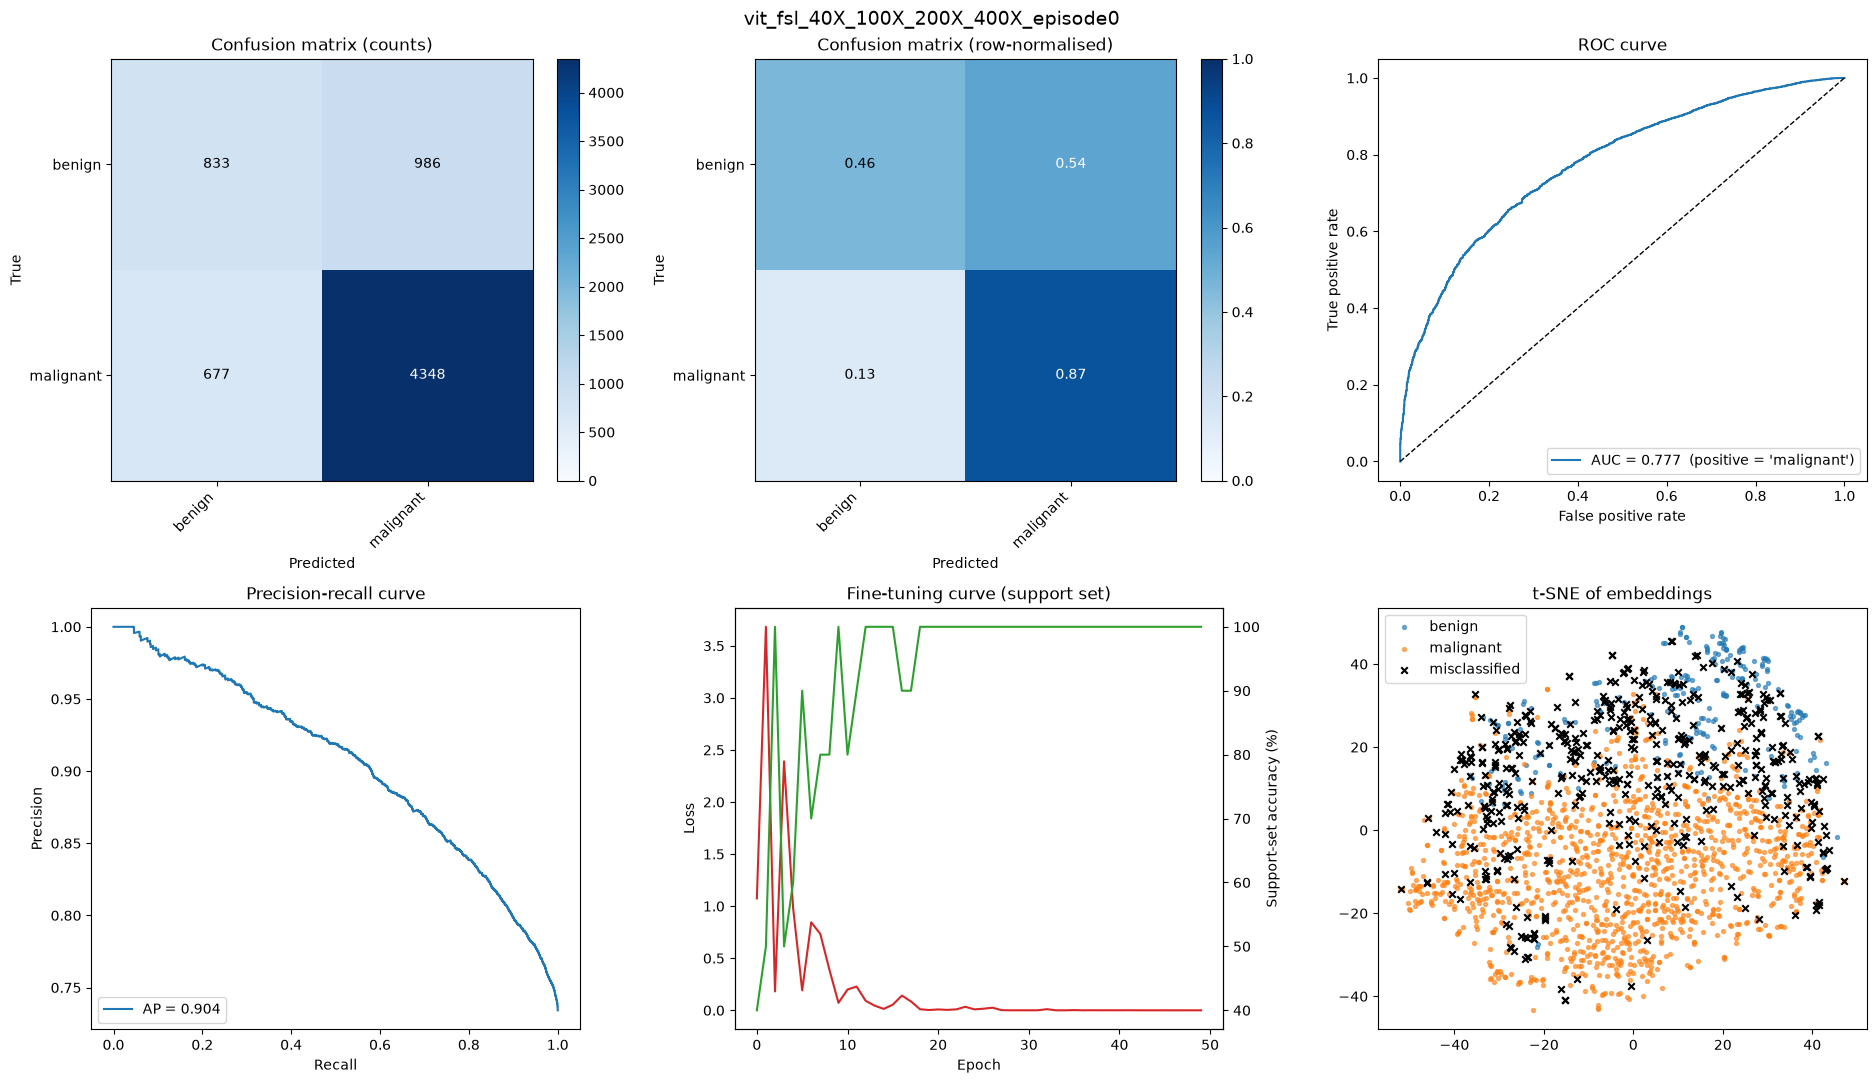


=== [40X+100X+200X+400X] Episode 2/5 (seed=43) ===
support: 10 images | query: 4675 images (patient-disjoint from support)
  epoch 10/50 - loss 0.3139 - support-set acc 90.0%
  epoch 20/50 - loss 0.0919 - support-set acc 90.0%
  epoch 30/50 - loss 0.0012 - support-set acc 100.0%
  epoch 40/50 - loss 0.0009 - support-set acc 100.0%
  epoch 50/50 - loss 0.0017 - support-set acc 100.0%



----- vit_fsl_40X_100X_200X_400X_episode1 -----
              precision    recall  f1-score   support

      benign      0.356     0.335     0.345      1957
   malignant      0.741     0.758     0.749      4907

    accuracy                          0.637      6864
   macro avg      0.548     0.547     0.547      6864
weighted avg      0.631     0.637     0.634      6864

                  accuracy: 0.6374
         balanced_accuracy: 0.5466
           precision_macro: 0.5483
              recall_macro: 0.5466
                  f1_macro: 0.5472
               f1_weighted: 0.6341
                       mcc: 0.0948
               cohen_kappa: 0.0947
                   roc_auc: 0.6120
               sensitivity: 0.7579
               specificity: 0.3352
             avg_precision: 0.8050
             accuracy_ci95: [0.6256, 0.6477]
              roc_auc_ci95: [0.5984, 0.6257]
   majority_class_baseline: 0.7149
        test_only_accuracy: 0.6409
  test_only_balanced_accuracy: 0.5579
      

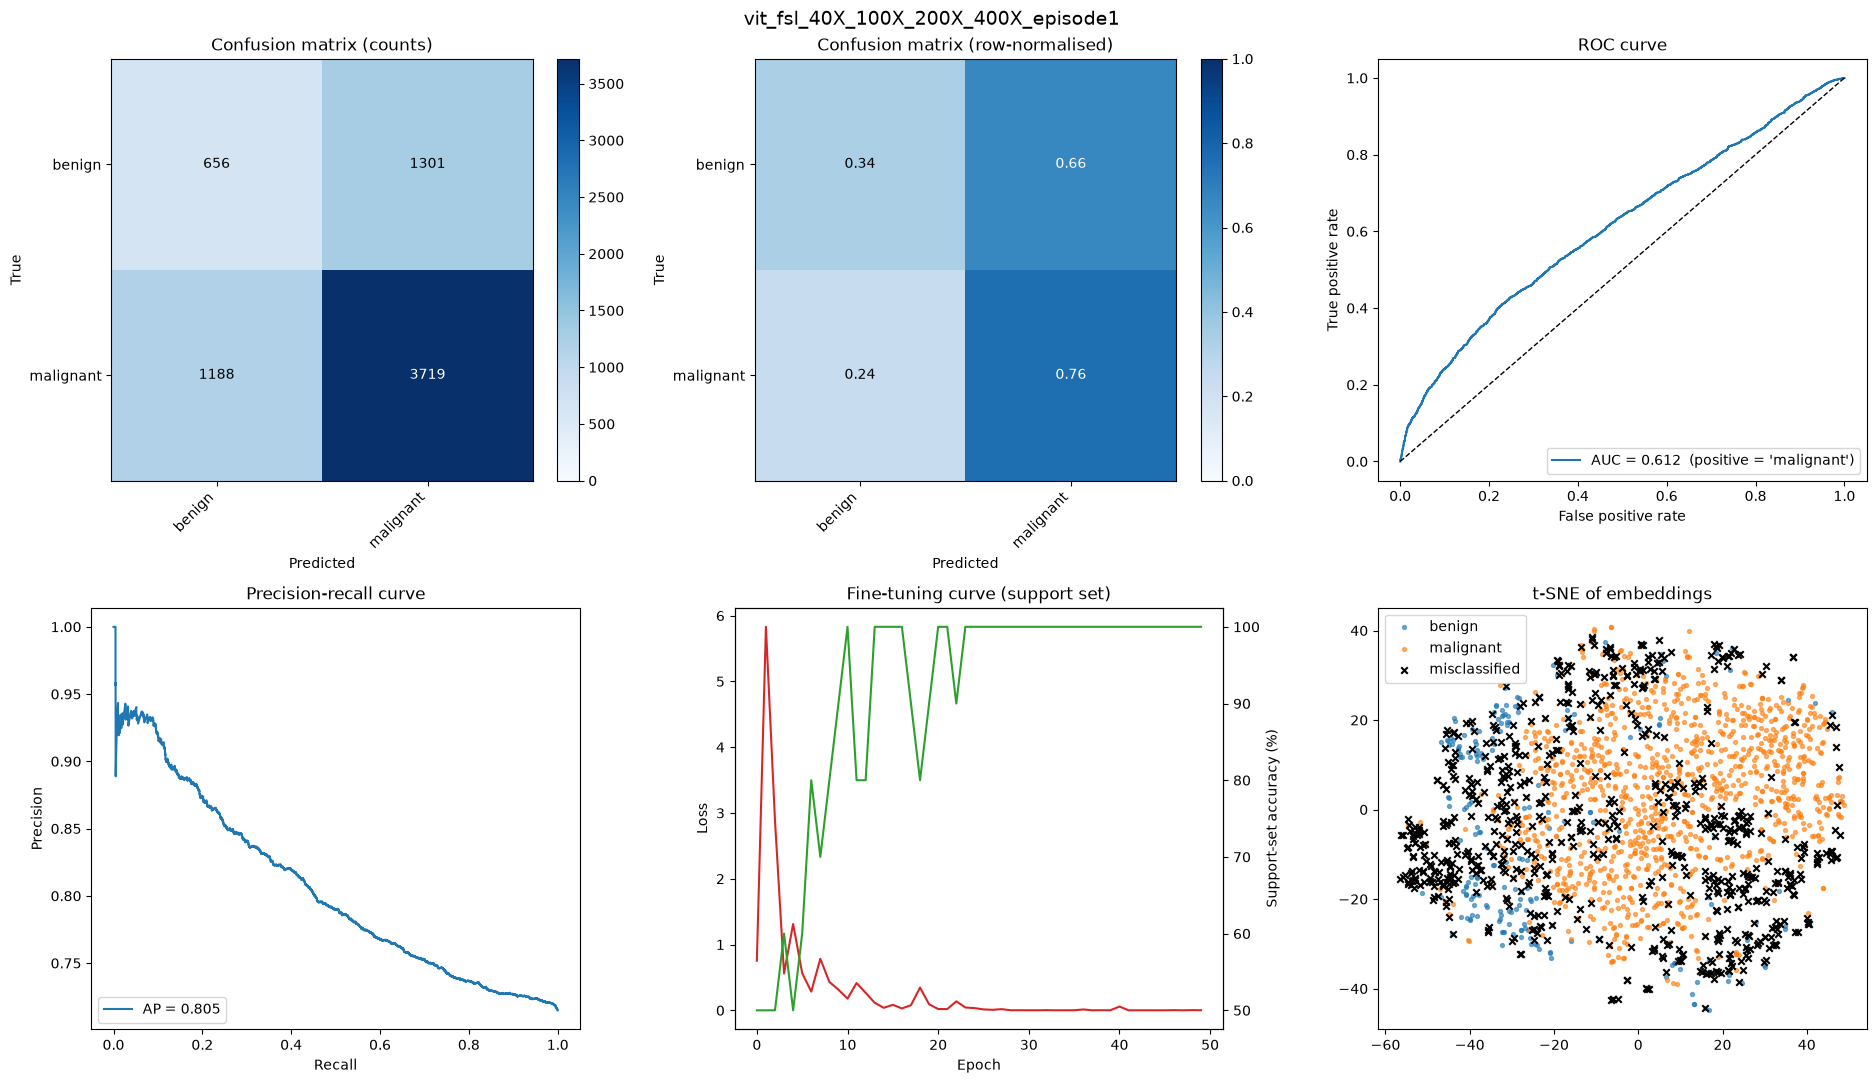


=== [40X+100X+200X+400X] Episode 3/5 (seed=44) ===
support: 10 images | query: 4411 images (patient-disjoint from support)
  epoch 10/50 - loss 0.0995 - support-set acc 100.0%
  epoch 20/50 - loss 0.0111 - support-set acc 100.0%
  epoch 30/50 - loss 0.0000 - support-set acc 100.0%
  epoch 40/50 - loss 0.0000 - support-set acc 100.0%
  epoch 50/50 - loss 0.0000 - support-set acc 100.0%



----- vit_fsl_40X_100X_200X_400X_episode2 -----
              precision    recall  f1-score   support

      benign      0.420     0.753     0.540      1749
   malignant      0.875     0.626     0.730      4851

    accuracy                          0.660      6600
   macro avg      0.648     0.689     0.635      6600
weighted avg      0.755     0.660     0.679      6600

                  accuracy: 0.6595
         balanced_accuracy: 0.6894
           precision_macro: 0.6480
              recall_macro: 0.6894
                  f1_macro: 0.6348
               f1_weighted: 0.6795
                       mcc: 0.3348
               cohen_kappa: 0.3024
                   roc_auc: 0.7611
               sensitivity: 0.6259
               specificity: 0.7530
             avg_precision: 0.8781
             accuracy_ci95: [0.6476, 0.6714]
              roc_auc_ci95: [0.7471, 0.7745]
   majority_class_baseline: 0.7350
        test_only_accuracy: 0.6565
  test_only_balanced_accuracy: 0.6777
      

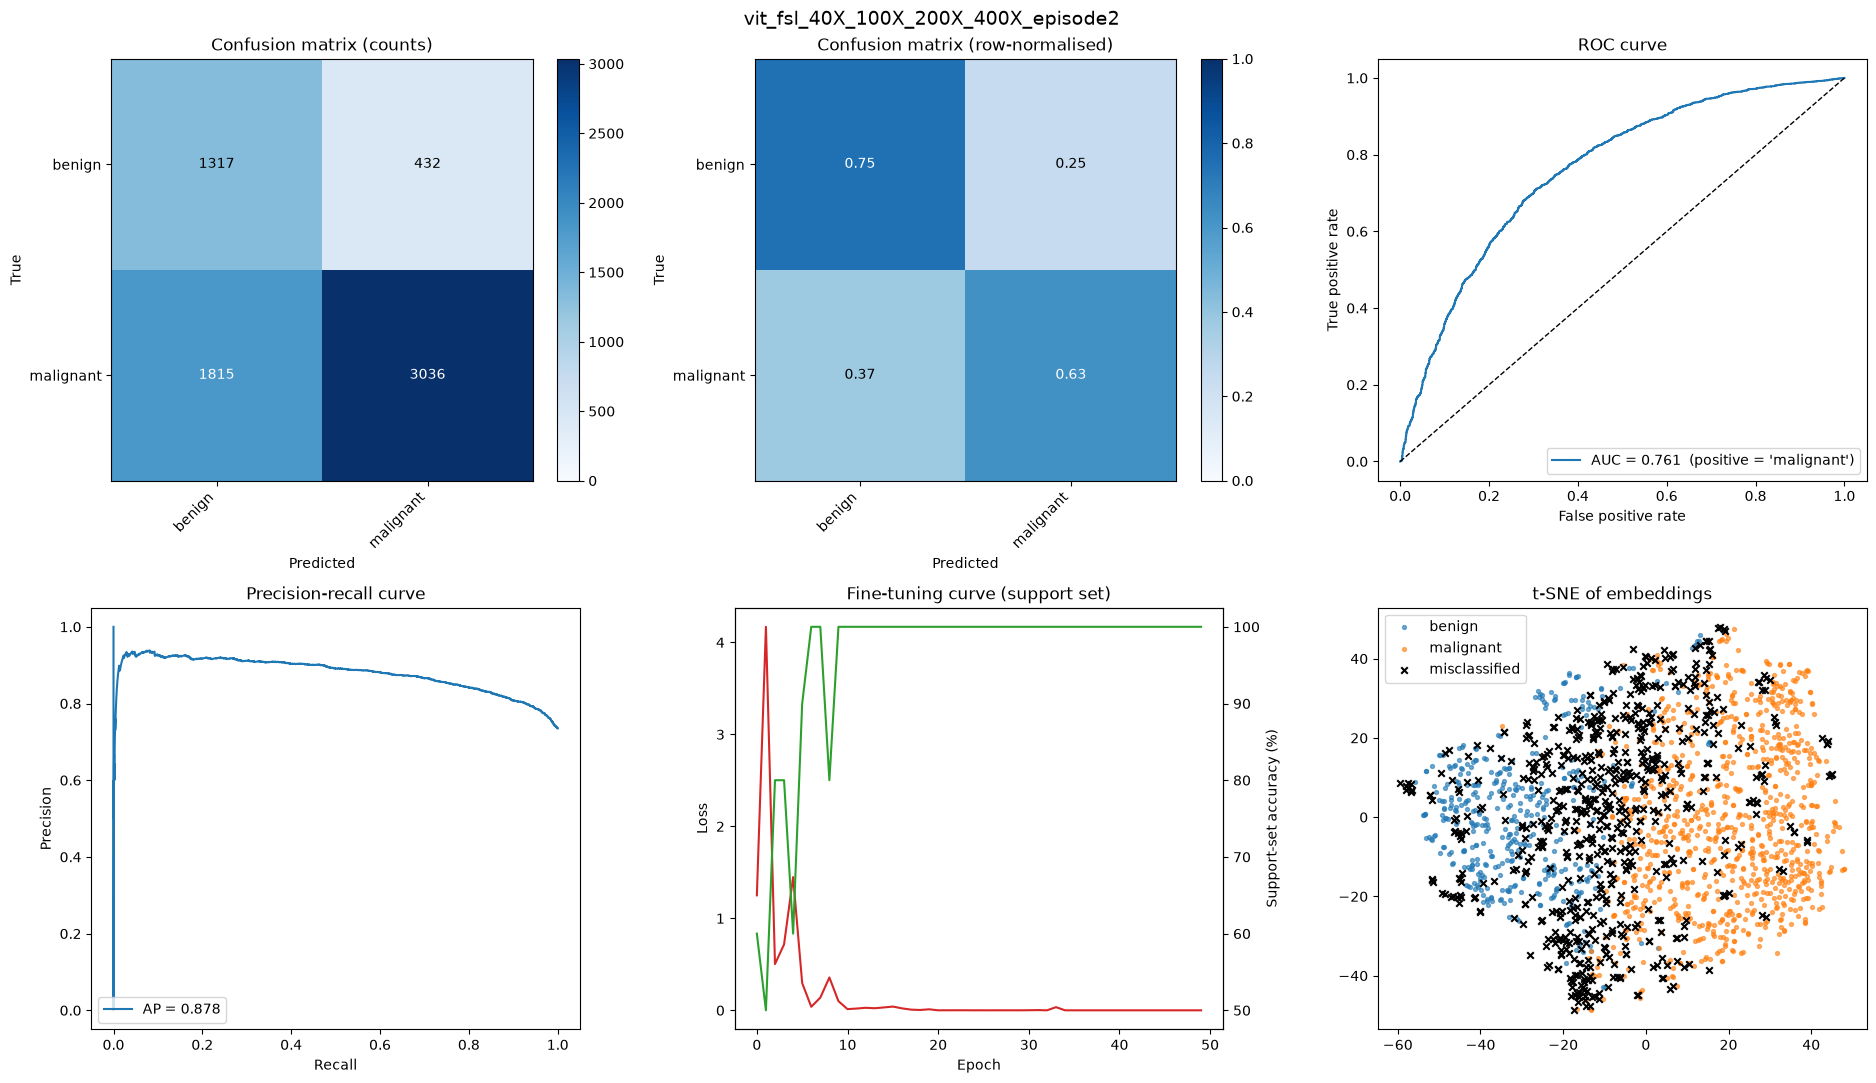


=== [40X+100X+200X+400X] Episode 4/5 (seed=45) ===
support: 10 images | query: 4477 images (patient-disjoint from support)
  epoch 10/50 - loss 0.0402 - support-set acc 100.0%
  epoch 20/50 - loss 0.0014 - support-set acc 100.0%
  epoch 30/50 - loss 0.0044 - support-set acc 100.0%
  epoch 40/50 - loss 0.0007 - support-set acc 100.0%
  epoch 50/50 - loss 0.0001 - support-set acc 100.0%



----- vit_fsl_40X_100X_200X_400X_episode3 -----
              precision    recall  f1-score   support

      benign      0.391     0.487     0.434      1856
   malignant      0.781     0.708     0.743      4810

    accuracy                          0.646      6666
   macro avg      0.586     0.597     0.588      6666
weighted avg      0.673     0.646     0.657      6666

                  accuracy: 0.6464
         balanced_accuracy: 0.5973
           precision_macro: 0.5864
              recall_macro: 0.5973
                  f1_macro: 0.5884
               f1_weighted: 0.6569
                       mcc: 0.1834
               cohen_kappa: 0.1811
                   roc_auc: 0.6402
               sensitivity: 0.7081
               specificity: 0.4865
             avg_precision: 0.8101
             accuracy_ci95: [0.6349, 0.6580]
              roc_auc_ci95: [0.6248, 0.6545]
   majority_class_baseline: 0.7216
        test_only_accuracy: 0.6418
  test_only_balanced_accuracy: 0.5870
      

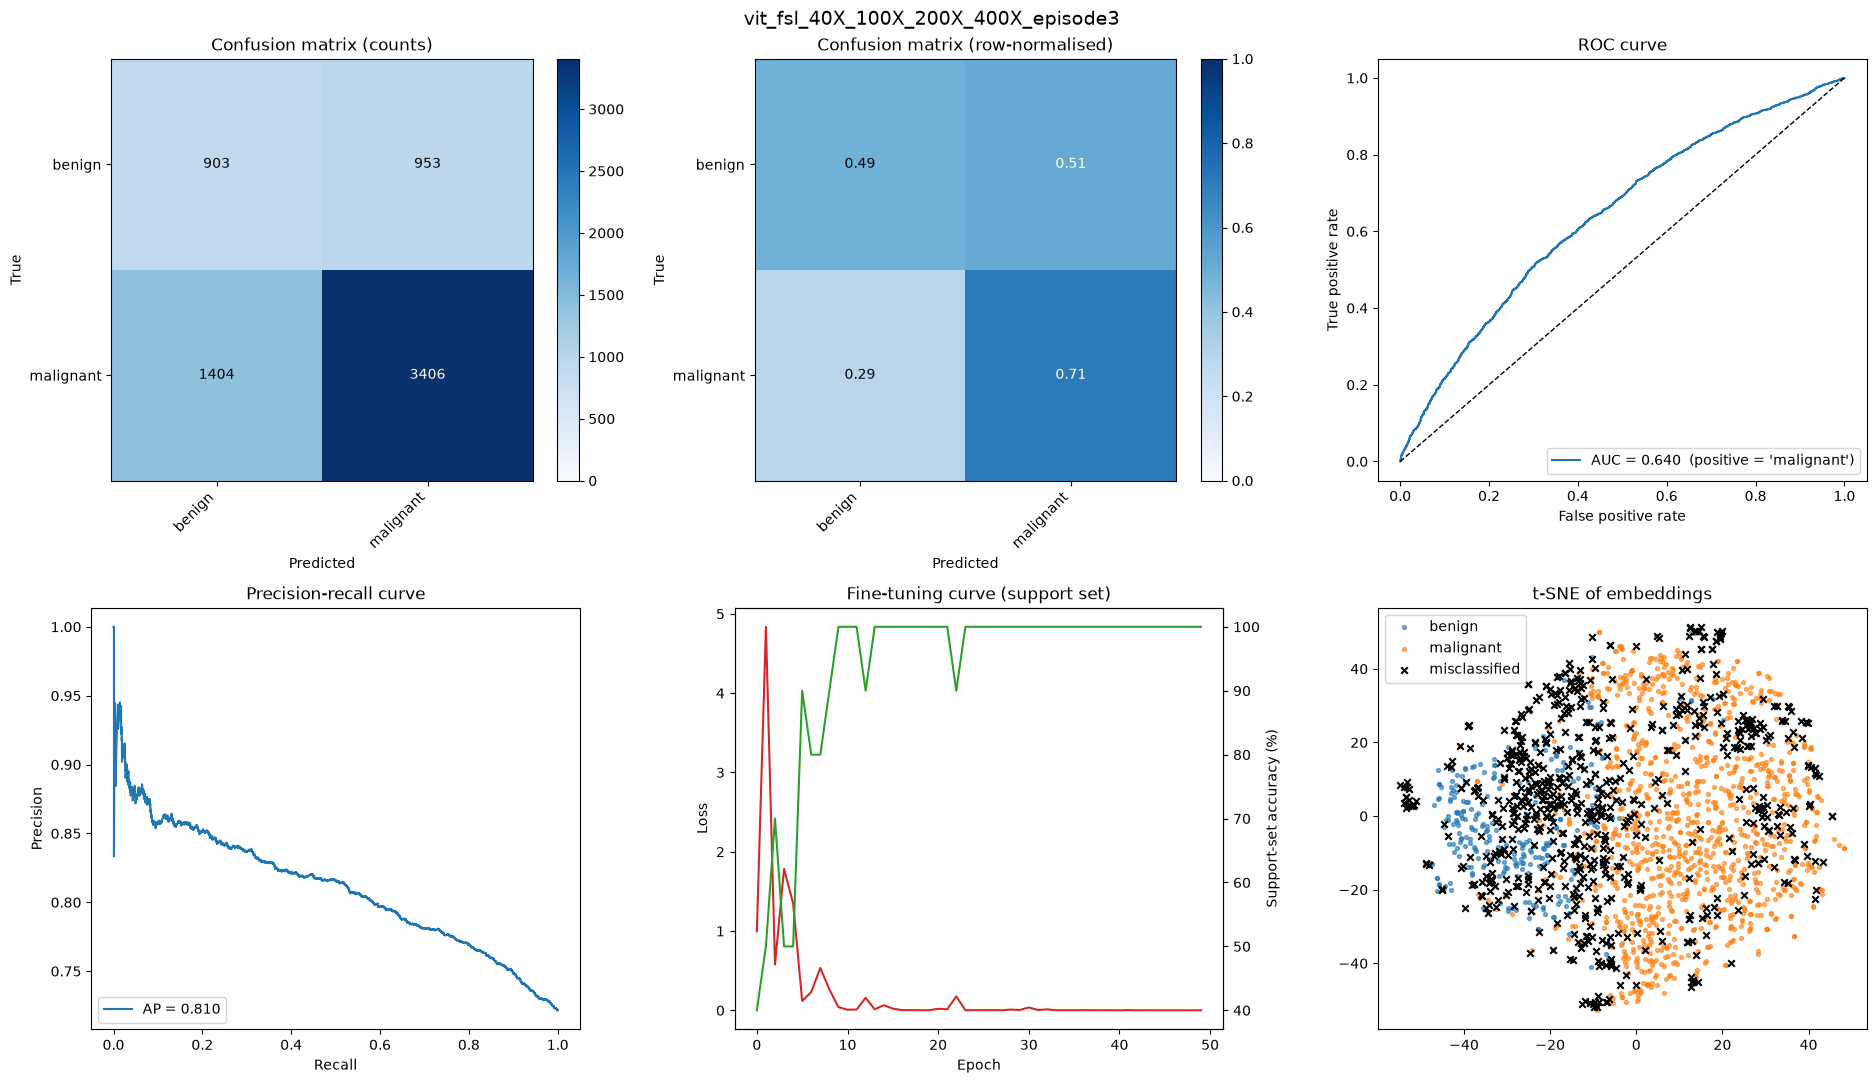


=== [40X+100X+200X+400X] Episode 5/5 (seed=46) ===
support: 10 images | query: 4540 images (patient-disjoint from support)
  epoch 10/50 - loss 0.4369 - support-set acc 70.0%
  epoch 20/50 - loss 0.0593 - support-set acc 100.0%
  epoch 30/50 - loss 0.0184 - support-set acc 100.0%
  epoch 40/50 - loss 0.0114 - support-set acc 100.0%
  epoch 50/50 - loss 0.0002 - support-set acc 100.0%



----- vit_fsl_40X_100X_200X_400X_episode4 -----
              precision    recall  f1-score   support

      benign      0.399     0.482     0.437      1835
   malignant      0.789     0.728     0.757      4894

    accuracy                          0.661      6729
   macro avg      0.594     0.605     0.597      6729
weighted avg      0.683     0.661     0.670      6729

                  accuracy: 0.6609
         balanced_accuracy: 0.6049
           precision_macro: 0.5942
              recall_macro: 0.6049
                  f1_macro: 0.5970
               f1_weighted: 0.6699
                       mcc: 0.1988
               cohen_kappa: 0.1970
                   roc_auc: 0.6373
               sensitivity: 0.7280
               specificity: 0.4817
             avg_precision: 0.7973
             accuracy_ci95: [0.6491, 0.6717]
              roc_auc_ci95: [0.6212, 0.6516]
   majority_class_baseline: 0.7273
        test_only_accuracy: 0.6958
  test_only_balanced_accuracy: 0.6261
      

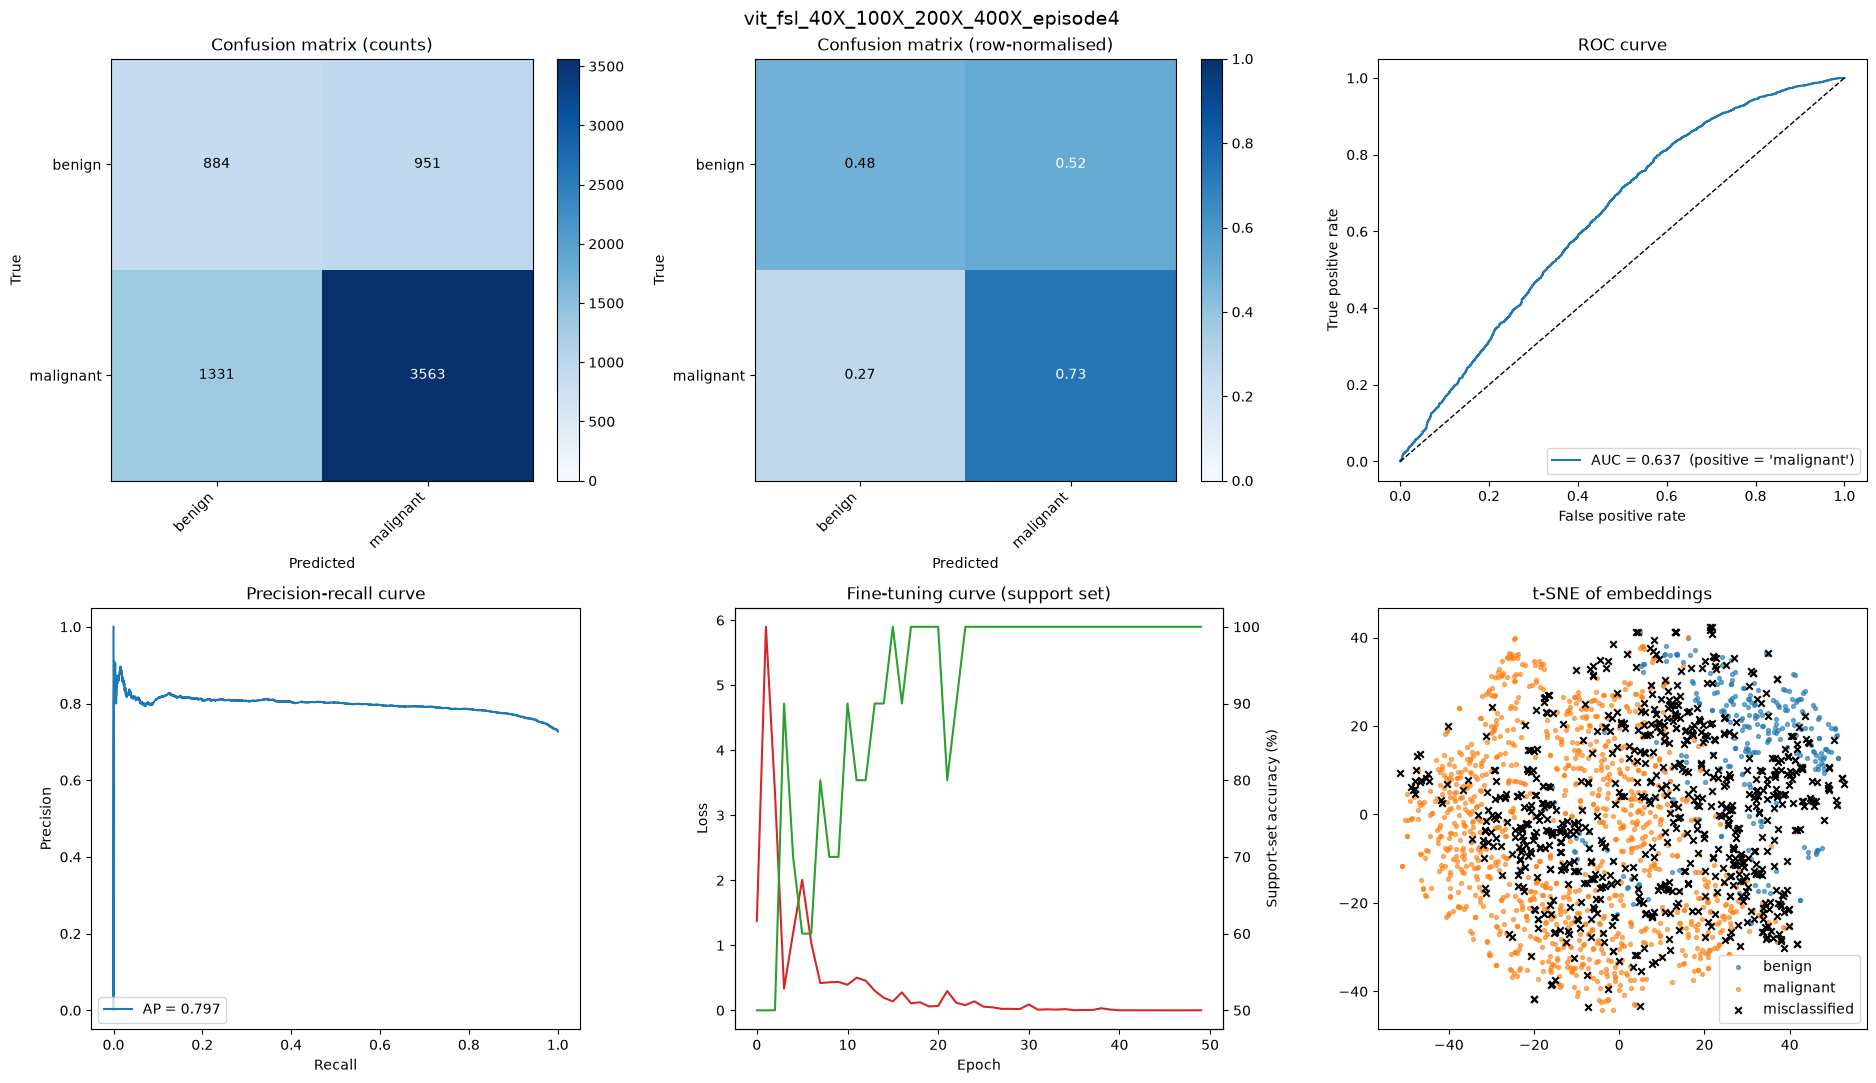


===== vit_fsl_40X_100X_200X_400X: summary over 5 episode(s) =====
                                     mean     std
accuracy                           0.6722  0.0433
balanced_accuracy                  0.6200  0.0504
precision_macro                    0.6121  0.0478
recall_macro                       0.6200  0.0504
f1_macro                           0.6075  0.0418
f1_weighted                        0.6779  0.0388
mcc                                0.2312  0.0954
cohen_kappa                        0.2234  0.0886
roc_auc                            0.6854  0.0690
sensitivity                        0.7370  0.0777
specificity                        0.5029  0.1367
avg_precision                      0.8390  0.0437
majority_class_baseline            0.7266  0.0076
test_only_accuracy                 0.6808  0.0483
test_only_balanced_accuracy        0.6274  0.0504
test_only_f1_macro                 0.6193  0.0484
test_only_roc_auc                  0.7007  0.0657
test_only_majority_class_baseline

In [8]:
TAG_PREFIX = "vit_fsl"
all_setting_summaries = {}

for setting in MAGNIFICATION_SETTINGS:
    print("\n" + "#" * 72 + f"\n# Magnification setting: {setting}\n" + "#" * 72)
    data_dir = prepare_breakhis_split(RAW_DATA_DIR, PREPARED_ROOT, setting, TEST_FRACTION, SPLIT_SEED)
    verify_and_report_split(data_dir)
    train_dataset_aug, train_dataset_eval, test_dataset, class_names = load_datasets(data_dir)
    print(f"Classes: {class_names}")
    safe = setting.replace("+", "_")
    episode_metrics = []

    for episode in range(N_EPISODES):
        seed = BASE_SEED + episode
        print(f"\n=== [{setting}] Episode {episode + 1}/{N_EPISODES} (seed={seed}) ===")
        set_seed(seed)
        rng = np.random.RandomState(seed)

        support_indices, query_indices = create_support_and_query(train_dataset_eval, SHOTS_PER_CLASS, rng)
        print(f"support: {len(support_indices)} images | query: {len(query_indices)} images (patient-disjoint from support)")
        support_set = Subset(train_dataset_aug, support_indices)       # augmented, for training
        support_set_eval = Subset(train_dataset_eval, support_indices)  # clean, for prototype embeddings
        query_set = Subset(train_dataset_eval, query_indices)

        g = torch.Generator().manual_seed(seed)
        support_loader = DataLoader(support_set, batch_size=min(BATCH_SIZE, len(support_set)), shuffle=True, generator=g)
        support_eval_loader = DataLoader(support_set_eval, batch_size=EXTRACT_BATCH_SIZE, shuffle=False)
        query_loader = DataLoader(query_set, batch_size=EXTRACT_BATCH_SIZE, shuffle=False)
        test_loader = DataLoader(test_dataset, batch_size=EXTRACT_BATCH_SIZE, shuffle=False)

        model = build_model()
        if FREEZE_BACKBONE:
            freeze_backbone_except_last_block(model, unfreeze_last_n_blocks=1)

        model, history = train_model_on_support(model, support_loader, NUM_EPOCHS, LEARNING_RATE, WEIGHT_DECAY)

        os.makedirs("checkpoints", exist_ok=True)
        torch.save(model.state_dict(), f"checkpoints/vit_fsl_{safe}_episode{episode}.pt")  # Fix #7

        y_true, y_pred, sims, feats, n_query = evaluate(model, support_eval_loader, query_loader, test_loader)
        metrics = full_analysis(
            y_true, y_pred, similarities_to_probs(sims), class_names,
            tag=f"vit_fsl_{safe}_episode{episode}", features=feats, history=history, n_query=n_query,
        )
        episode_metrics.append(metrics)

    all_setting_summaries[setting] = summarize_episodes(episode_metrics, f"vit_fsl_{safe}")

comparison = pd.DataFrame({s: sm["mean"] for s, sm in all_setting_summaries.items()}).T
cols = [c for c in ["accuracy", "majority_class_baseline", "balanced_accuracy", "f1_macro", "roc_auc", "mcc",
                    "test_only_accuracy", "test_only_majority_class_baseline", "test_only_roc_auc"] if c in comparison.columns]
print("\n===== Comparison across magnification settings (mean over episodes) =====")
print(comparison[cols].round(4).to_string())
comparison[cols].to_csv(f"{RESULTS_DIR}/{TAG_PREFIX}_magnification_comparison.csv")
